# Machine Learning para Economistas (PE1333)
## Tutorial 6 - Parte 1. CART: Árboles de regresión y clasificación 

**Objetivo:**  
Que se familiaricen con los arboles de decisión para regresión y clasificación

### Temario:
- Árbol de decisión y clasificación
- Ejemplo práctico con base de Titanic para predecir sobrevivientes: https://www.kaggle.com/dmilla/introduction-to-decision-trees-titanic-dataset
- Ejemplo práctico con la base de Hitters para predecir salarios

## ¿Qué es un árbol de decisiones? ¿Cómo funciona?
El árbol de decisiones es un tipo de algoritmo de **aprendizaje supervisado** (que tiene una variable objetivo predefinida) que se utiliza para problemas de **clasificación y de regresión**. Funciona para variables tanto categóricas como continuas. 

En esta técnica, el objetivo es dividir a la población o muestra en dos o más conjuntos (o subpoblaciones) homogéneos en función del atributo más significativo en las variables x. Entonces la pureza del nodo aumenta con respecto a la variable objetivo. El árbol de decisión divide los nodos en todas las variables disponibles y luego selecciona la división que da como resultado los subnodos más homogéneos.

### Tipos de árboles de decisión
Los tipos de árbol de decisión se basan en el tipo de variable objetivo que tenemos. Puede ser de dos tipos:

**1. Árbol de decisión de variable categórica:** Árbol de decisión que tiene una variable de destino categórica y luego se llama como árbol de decisión de variable categórica. Ejemplo: Titanic

**2. Árbol de decisión de variable continua:** El árbol de decisión tiene una variable de destino continua, por lo que se denomina Árbol de decisión de variable continua. Ejemplo: Hitters


### Terminología importante relacionada con los árboles de decisión
Veamos la terminología básica utilizada con los árboles de decisión:

**1.Nodo Base/Raíz (RootNode):** Es el primer nodo. Representa la muestra completa y esto se divide en dos o más conjuntos homogéneos.

**2.Dividir (Splitting):** Es un proceso de dividir un nodo en dos o más subnodos.

**3.Nodo interno o nodo de decisión (Decision Node):** Cuando un subnodo se divide en otros subnodos, se denomina nodo interno o nodo de decisión.

**4. Nodo Terminal/Hojas:** Los nodos que no se dividen se denominan Hoja o nodo Terminal.

**5.Poda (Pruning):** Cuando eliminamos subnodos de un nodo de decisión, este proceso se llama poda. Es decir, el proceso opuesto de la división.

**6 Rama/Subárbol:** Una subsección de todo el árbol se llama rama o subárbol.

**7.Nodo padre e hijo:** Un nodo, que se divide en subnodos, se denomina nodo padre de subnodos, donde los subnodos son los hijos del nodo padre.

En el ejemplo de la base Hitters

*(El árbol de Hitters lo construimos nosotros más abajo, en la sección de árboles de regresión.)*
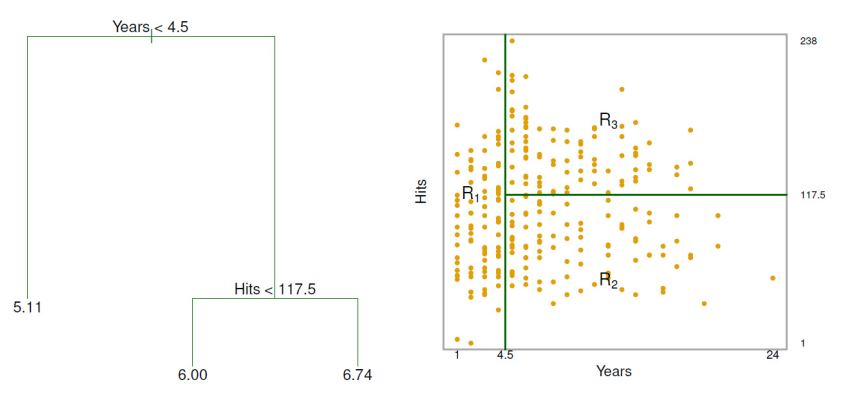


## Ventajas
* **No lineal:** Los árboles son una forma inteligente de representar las no linealidades

* **Fácil de entender y comunicar:** La salida del árbol de decisiones es muy fácil de entender. No requiere ningún conocimiento estadístico.

* **Útil en la exploración de datos:** es la forma más rápida de identificar variables significativas (las de los nodos de más arriba). Con los árboles de decisión podemos crear nuevas variables/ características que tienen mejor poder para predecir la variable objetivo.

* **El tipo de datos no es una restricción:** Puede manejar variables tanto numéricas como categóricas

## Desventajas

* **Ajuste excesivo:** El ajuste excesivo es una de las dificultades más prácticas para el modelo de árbol de decisión. Este problema se resuelve estableciendo restricciones en los parámetros del modelo.

* **Estructura lineal:** Cuando la estructura de los datos es lineal, el arbol no anda bien, porque las variables importan siempre y con cart solo algunas variables importan en cada nodo. 

* **Poco robusto:** Cambios en la base puede generar grandes cambios en el arbol resultante

## Ejercicio: Árbol de decisiones sobre datos del Titanic
En este ejercicio veremos los árboles de decisión utilizando el conjunto de datos Titanic:
1. Aprender a predecir a los sobrevivientes con árboles de decisión
2. Exploración y procesamiento de conjuntos de datos
3. Funciones relevantes para los árboles de decisión
4. Impureza de Gini
5. Encontrar la mejor profundidad de árbol con la ayuda de la validación cruzada
6. Generación y visualización del modelo final


|Variable|Definition|Key|
| --- | --- | --- |
|Survival|Survival|0 = No, 1 = Yes|
|Pclass|Ticket class|1 = 1st, 2 = 2nd, 3 = 3rd|
|Sex|Sex||
|Age|Age in years||
|Sibsp|| # of siblings / spouses aboard the Titanic	
|Parch|| # of parents / children aboard the Titanic	
|Ticket|Ticket number||
|Fare|Passenger fare||
|Cabin|Cabin number||
|Embarked|Port of Embarkation|C = Cherbourg, Q = Queenstown, S = Southampton|


Fuente: [Kaggle](https://www.kaggle.com/c/titanic/data)

### Limpieza de la base de datos del Titanic 

In [1]:
# (Si aún no instalaron alguna librería recuerden primero hacer ese paso)
import os
import numpy as np
import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.model_selection import cross_val_score

In [2]:
# Cargamos los datos 
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

# Guardamos el ID de los pasajeros del grupo a predecir 
passenger_id = test['PassengerId']

original_train = train.copy()

# Info del df
print(train.info())
#print(test.info())
# Miramos las primeras filas del df
train.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


A continuación queremos generar una función que nos extraiga el título de la persona. Por ejemplo, el título de `Braund, Mr. Owen Harris` sería `Mr`.

In [3]:
# Miramos las primeras filas del df
test.head(5)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [4]:
# Definir función para extraer los 'titles' de los nombres de los pasajeros
def get_title(name):
    '''
    input: nombres de los pasajeros, incluyendo el title
    return: title
    '''
    title_search = re.search(' ([A-Za-z]+)\.', name)
    if title_search:
        return title_search.group(1)
    return ""

La función anterior usa algo que se llaman expresiones regulares para buscar texto. El uso de expresiones regulares es algo que solía ser bastante complicado y requerir bastante estudio, pero ahora, con la ayuda de los LLMs, la cosa se hizo mucho más fácil. Por ejemplo: Si están usando VSCode usen _Generate_ de copilot con un prompt que diga algo como "create a function, called get_title, that extracts the word right before the first dot in a string".

In [5]:
# Ejemplo
get_title(train.Name[0])

'Mr'

In [6]:
train.Name[0]

'Braund, Mr. Owen Harris'

##### Tarea para la casa: 
Hacer un heatmap de NaN en train y test

A continuación vamos a crear nuevas columnas con el dataset que contengan información relevante (lo pueden ver en detalle en sus casas).

Vamos a hacer varias cosas:
* Calcular el tamaño de la familia.
* Crear una nueva columna llamada `Has_cabin` que tiene un 0 si `Cabin` es `NaN` y un 1 si no.
* Completar los _missing values_ de `Embarked` con `S` (el valor más común).
* Completar los _missing values_ de `Fare` con su mediana.
* Completar los _missing values_ de `Age` con un valor aleatorio entre la media +/- 1 SD.
* Obtener el título y reemplazar los raros (como `Countess`) por `Rare`.
* Convertir la variable `Age` en numérica.
* Generar dummies para `Title` y `Embarked`.

In [7]:
# Fijamos la semilla para que la imputación de la edad dé siempre igual
np.random.seed(0)

dummies_train_df = []
dummies_test_df = []

for dataset in [train, test]:
    # Tamaño de la familia
    dataset['Family_Size'] = dataset['SibSp'] + dataset['Parch'] + 1
    # Viaja solo?
    dataset['Alone'] = 0
    dataset.loc[dataset['Family_Size'] == 1, 'Alone'] = 1
    # Tiene cabina?
    dataset['Has_Cabin'] = dataset["Cabin"].apply(lambda x: 0 if type(x) == float else 1)
    # Reemplazamos los missings en Embarked con la opción más común #train.groupby(['Embarked']).count()
    dataset['Embarked'] = dataset['Embarked'].fillna('S')
    # Reemplazamos los missings en Fare con la mediana
    dataset['Fare'] = dataset['Fare'].fillna(train['Fare'].median())
    
    # Imputamos los nulls en la edad con valores aleatorios entre la media +- 1 SD
    age_avg = dataset['Age'].mean()
    age_std = dataset['Age'].std()
    age_null_count = dataset['Age'].isnull().sum()
    age_null_random_list = np.random.randint(age_avg - age_std, age_avg + age_std, size=age_null_count)
    dataset.loc[np.isnan(dataset['Age']), 'Age'] = age_null_random_list
    dataset['Age'] = dataset['Age'].astype(int)
    
    # Nueva columna con titles
    dataset['Title'] = dataset['Name'].apply(get_title)
    # Agrupamos los títulos menos comunes
    dataset['Title'] = dataset['Title'].replace(['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'],
                                                'Rare')
    dataset['Title'] = dataset['Title'].replace('Mlle', 'Miss')
    dataset['Title'] = dataset['Title'].replace('Mme', 'Mrs')
    dataset['Title'] = dataset['Title'].replace('Ms', 'Miss') 
   
    # Convertimos Sex en numerica
    dataset['Male'] = dataset['Sex'].map( {'female': 0, 'male': 1} ).astype(int)
    
    if dataset is train:
        # Convertimos Title en dummies  
        titles_train = pd.get_dummies(train['Title'], drop_first=True)
        dummies_train_df.append(titles_train)
        # Convertimos Embarked en dummies
        embarked_train = pd.get_dummies(train['Embarked'], drop_first=True)
        dummies_train_df.append(embarked_train)
    else:
        # Convertimos Title en dummies    
        titles_test = pd.get_dummies(test['Title'], drop_first=True)
        dummies_test_df.append(titles_test)
        # Convertimos Embarked en dummies        
        embarked_test = pd.get_dummies(test['Embarked'], drop_first=True)
        dummies_test_df.append(embarked_test)

In [8]:
dummies_train_df

[      Miss     Mr    Mrs   Rare
 0    False   True  False  False
 1    False  False   True  False
 2     True  False  False  False
 3    False  False   True  False
 4    False   True  False  False
 ..     ...    ...    ...    ...
 886  False  False  False   True
 887   True  False  False  False
 888   True  False  False  False
 889  False   True  False  False
 890  False   True  False  False
 
 [891 rows x 4 columns],
          Q      S
 0    False   True
 1    False  False
 2    False   True
 3    False   True
 4    False   True
 ..     ...    ...
 886  False   True
 887  False   True
 888  False   True
 889  False  False
 890   True  False
 
 [891 rows x 2 columns]]

Eliminamos variables irrelevantes y unimos con las tablas de dummies

In [9]:
# Eliminamos variables originales que no nos sirven y concatenamos las dummies creadas
drop_elements = ['PassengerId', 'Name', 'Sex', 'Ticket', 'Cabin', 'Parch', 'SibSp', 'Embarked', 'Title']

train = pd.concat([train, dummies_train_df[0], dummies_train_df[1]], axis=1)
train = train.drop(drop_elements, axis = 1)
train.columns = train.columns.str.lower()

test = pd.concat([test, dummies_test_df[0], dummies_test_df[1]], axis=1)
test = test.drop(drop_elements, axis = 1)
test.columns = test.columns.str.lower()

train.head(5)

,survived,pclass,age,fare,family_size,alone,has_cabin,male,miss,mr,mrs,rare,q,s
0,0,3,22,7.2500,2,0,0,1,False,True,False,False,False,True
1,1,1,38,71.2833,2,0,1,0,False,False,True,False,False,False
2,1,3,26,7.9250,1,1,0,0,True,False,False,False,False,True
3,1,1,35,53.1000,2,0,1,0,False,False,True,False,False,True
4,0,3,35,8.0500,1,1,0,1,False,True,False,False,False,True


In [10]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   age          891 non-null    int64  
 3   fare         891 non-null    float64
 4   family_size  891 non-null    int64  
 5   alone        891 non-null    int64  
 6   has_cabin    891 non-null    int64  
 7   male         891 non-null    int64  
 8   miss         891 non-null    bool   
 9   mr           891 non-null    bool   
 10  mrs          891 non-null    bool   
 11  rare         891 non-null    bool   
 12  q            891 non-null    bool   
 13  s            891 non-null    bool   
dtypes: bool(6), float64(1), int64(7)
memory usage: 61.0 KB
None


Probamos que no hayan quedado missing values:

In [11]:
# Probamos que no hayan quedado missing values:
columns_with_nan = train.columns[train.isna().any()].tolist()
print("Columns with NaN values:", columns_with_nan)
columns_with_nan = test.columns[test.isna().any()].tolist()
print("Columns with NaN values:", columns_with_nan)

Columns with NaN values: []
Columns with NaN values: []


## Visualización de la base procesada

### Heatmap
Este mapa de calor es muy útil como observación inicial porque permite hacerse una idea del valor predictivo de cada feature. El valor del mapa de calor se sitúa entre (-1,0) y (0,1). A medida que aumenta el valor (en términos absolutos), aumenta la correlación entre los atributos.

<Axes: title={'center': 'Correlacion de Pearson entre las Xs'}>

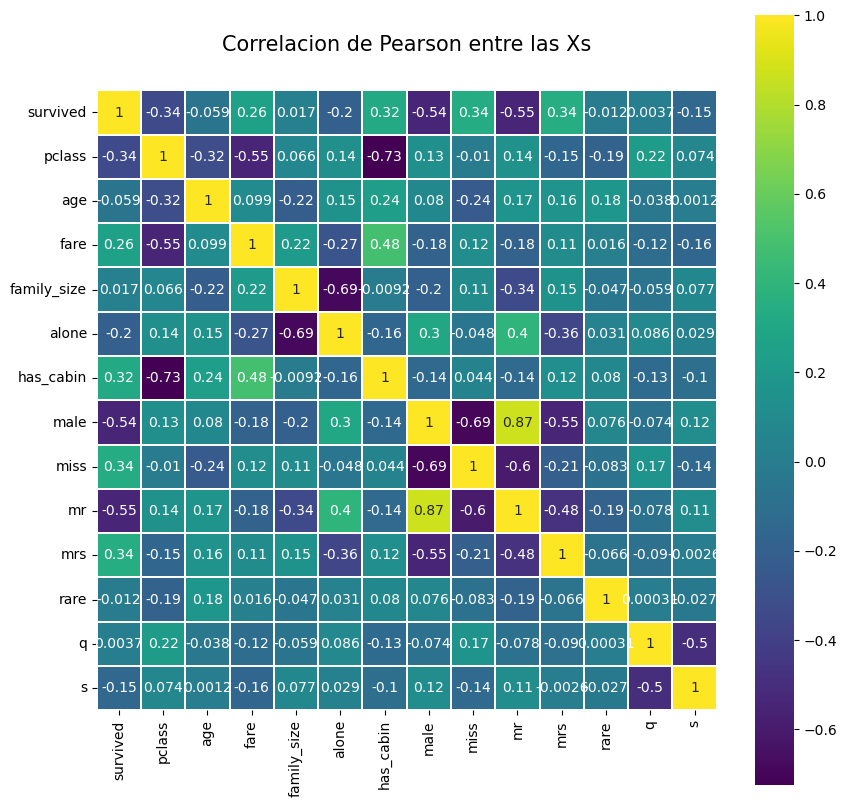

In [12]:
colormap = plt.cm.viridis
plt.figure(figsize=(10,10))
plt.title('Correlacion de Pearson entre las Xs', y=1.05, size=15)
sns.heatmap(train.astype(float).corr(),
            linewidths=0.1,
            vmax=1.0, 
            square=True, 
            cmap=colormap, 
            linecolor='white', 
            annot=True)

### ¿Cómo decide un árbol dónde dividirse?
Los árboles de decisión utilizan distintos algoritmos para decidir cómo dividir un nodo en dos o más subnodos. La creación de subnodos aumenta la homogeneidad de los subnodos resultantes. En otras palabras, podemos decir que la pureza del nodo aumenta con respecto a la variable objetivo. El árbol divide los nodos en todas las variables disponibles y luego selecciona la división que da como resultado los subnodos más homogéneos.


#### Índice de Gini
El Gini da una medida de la impureza de un nodo. Se calcula como:

$Gini =  \sum \limits _{k=1} ^{K} \hat{p}_{mk} (1-\hat{p}_{mk}) $

donde $\hat{p}_{mk}$ es la proporción de observaciones que en el dataset de entrenamiento en la región m de la clase k. 

Por la forma en la que está construido este índice, su valor será menor cuando $\hat{p}_{mk}$ se acerque a 1 o a 0 (es decir, cuando las observaciones del nodo son más parecidas). Cuanto menor sea el valor de Gini, menor será la desigualdad. Los árboles de decisión intentarán encontrar la división que reduzca más la Impureza de Gini en los dos nodos resultantes.

In [13]:
# Definimos la función de la impureza de Gini 
def get_gini_impurity(survived_count, total_count):
    survival_prob = survived_count/total_count
    not_survival_prob = (1 - survival_prob)
    random_observation_survived_prob = survival_prob
    random_observation_not_survived_prob = (1 - random_observation_survived_prob)
    mislabelling_survived_prob = not_survival_prob * random_observation_survived_prob
    mislabelling_not_survived_prob = survival_prob * random_observation_not_survived_prob
    gini_impurity = mislabelling_survived_prob + mislabelling_not_survived_prob
    return gini_impurity

In [14]:
train.survived.value_counts()

survived
0    549
1    342
Name: count, dtype: int64

In [15]:
# Gini Impurity en nodo inicial
survived = train.survived.value_counts()[1]
total = len(train)
gini_impurity_starting_node = get_gini_impurity(survived, total)
gini_impurity_starting_node.round(3)

np.float64(0.473)

A mano:

In [16]:
total = (549+342)
suma_k0 = 549/total * (1 - 549/total)
suma_k1 = 342/total * (1 - 342/total)
gini_a_mano = suma_k0 + suma_k1
print(np.round(gini_a_mano,3))

0.473


Veamos el promedio de los sobrevivientes entre hombres y mujeres:

In [17]:
original_train[['Sex', 'Survived']].groupby(['Sex'], as_index=False).agg(['mean', 'count', 'sum']).round(2)

Sex Survived           
              mean count  sum
0  female     0.74   314  233
1    male     0.19   577  109

In [18]:
# Gini Impurity si hicieramos la partición según sexo
gini_impurity_starting_node_male = get_gini_impurity(109, 577)
gini_impurity_starting_node_female = get_gini_impurity(233, 314)
print(np.round([gini_impurity_starting_node_male, gini_impurity_starting_node_female],3))

[0.306 0.383]


## Árbol de decisión de clasificación

Para estimar el modelo vamos a usar [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) de Scikit Learn


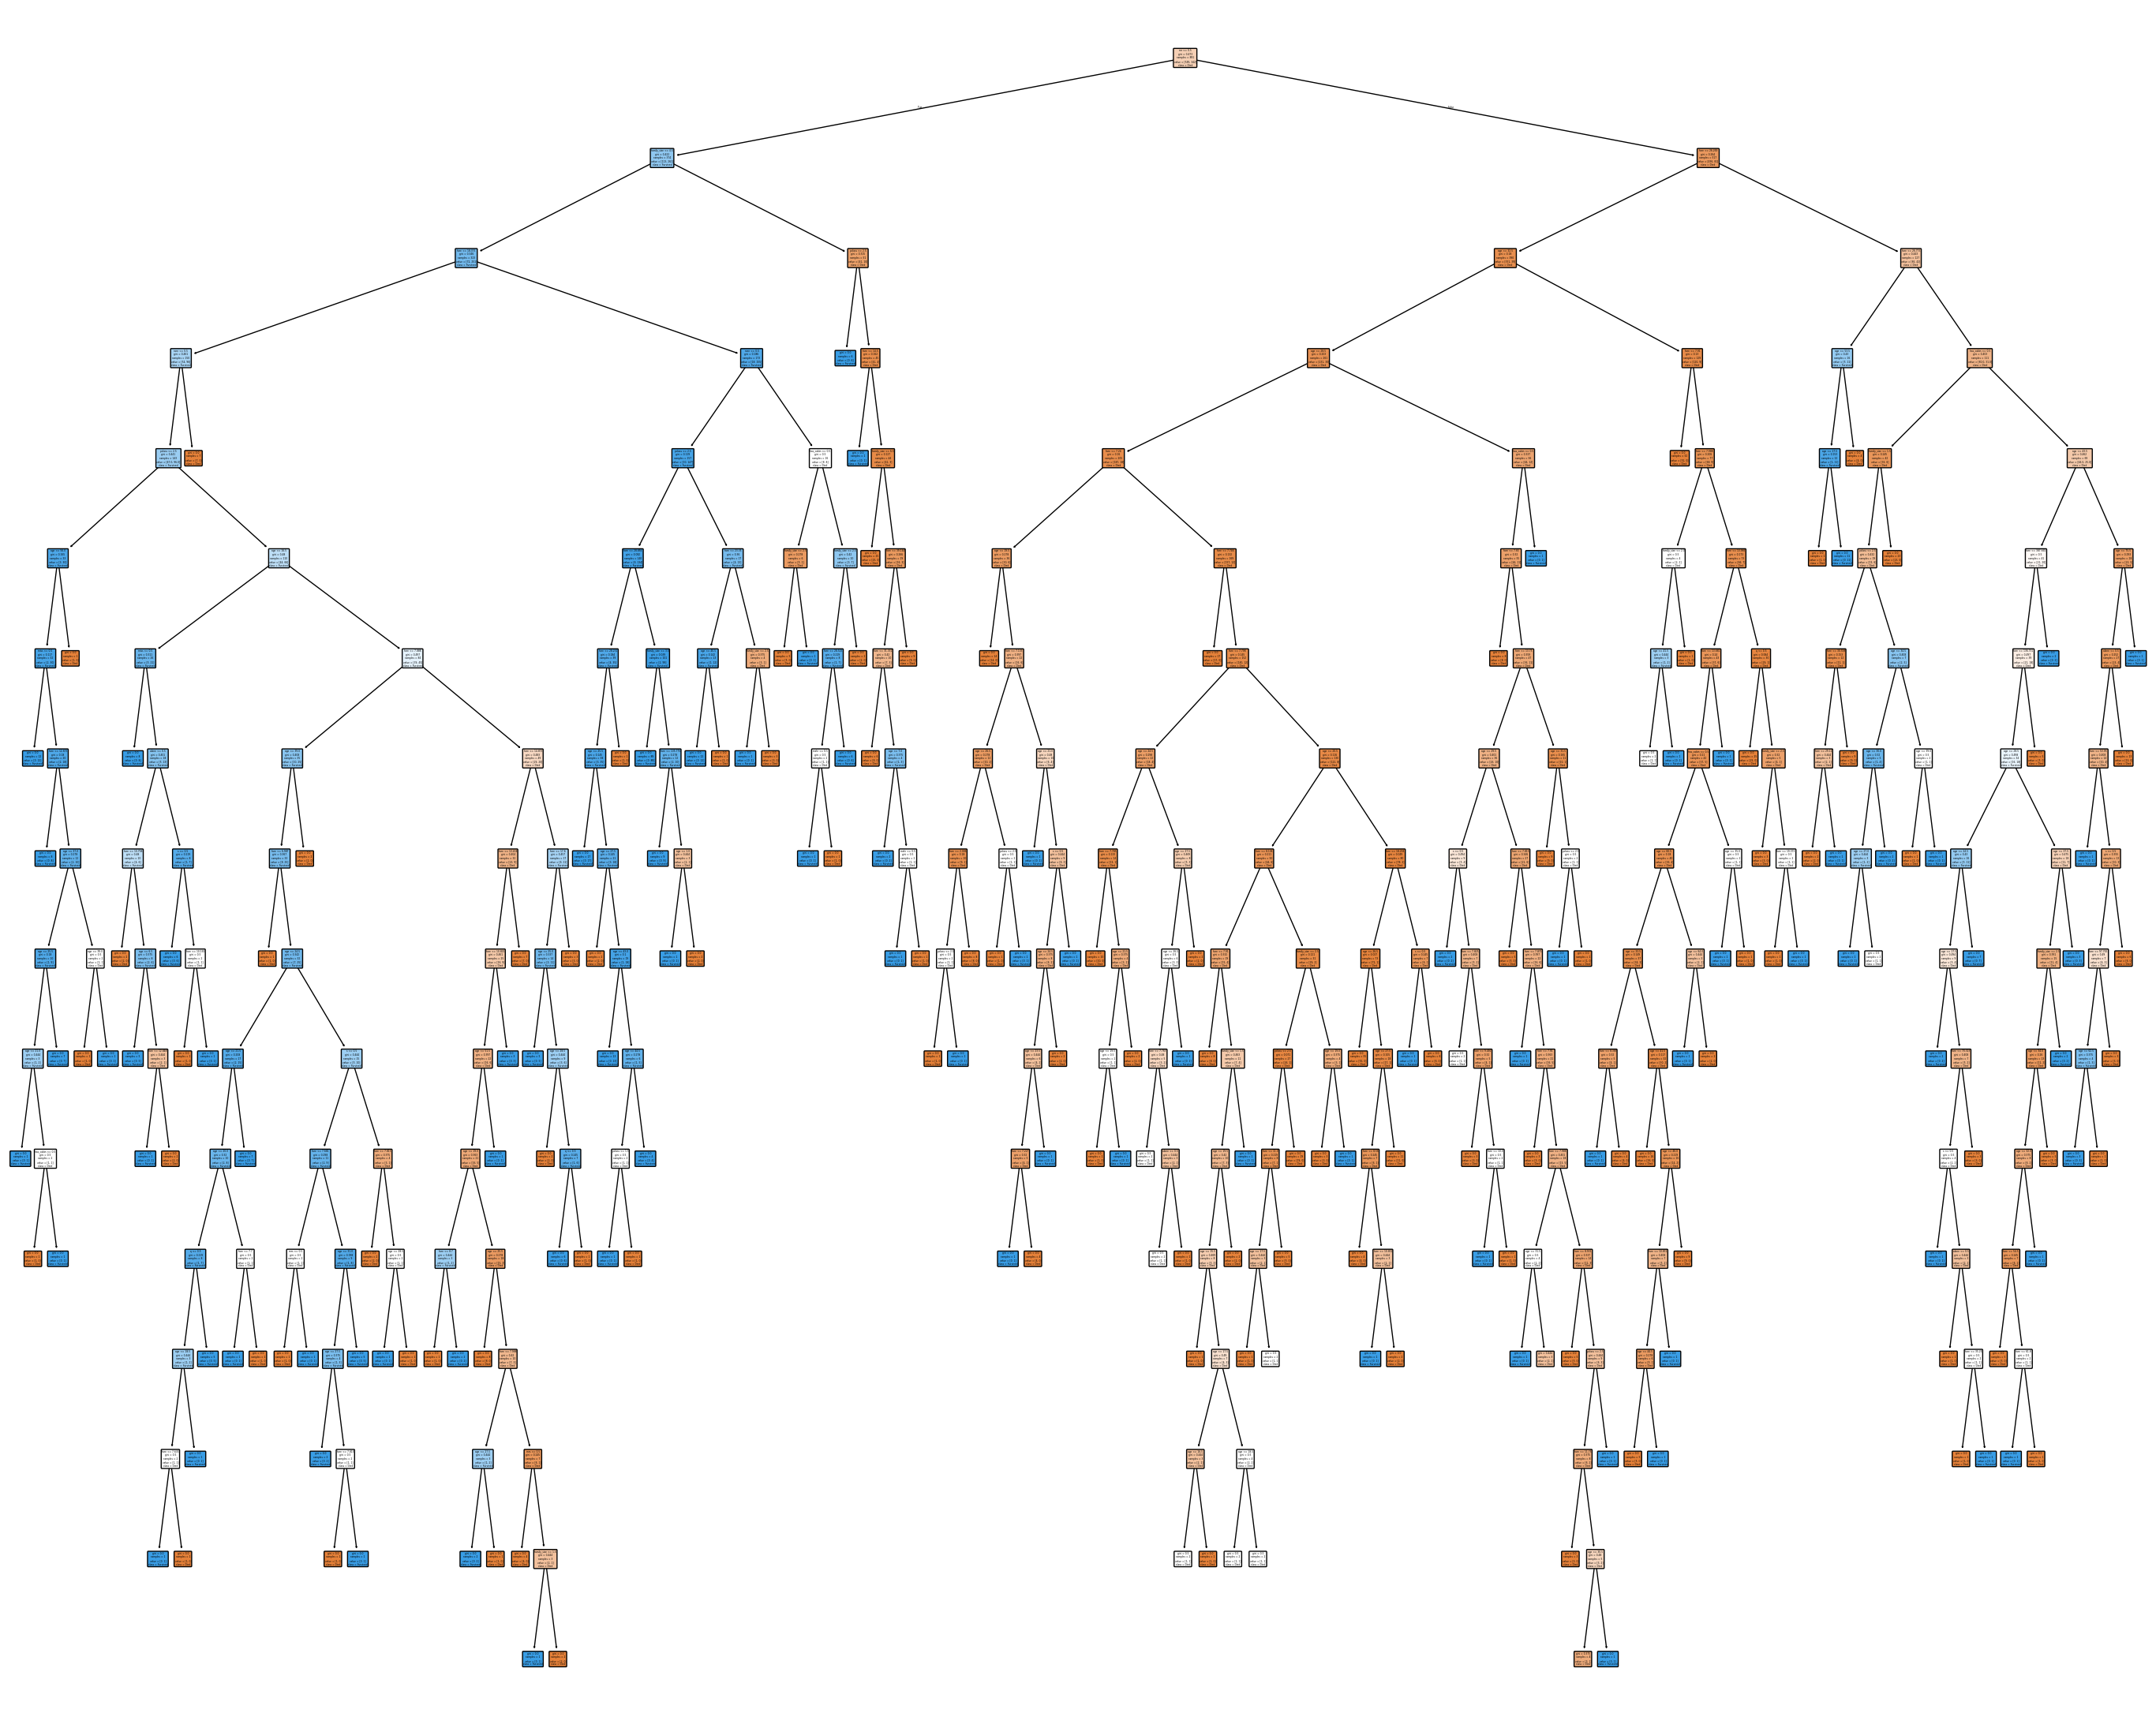

In [19]:
X = train.drop(['survived'], axis=1)
y = train["survived"]  

# Primero, probemos un arbol sin tocar ningun parametro (osea usando la configuración por default)
decision_tree = DecisionTreeClassifier().fit(X, y)

# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  impurity = True,   #mostrar impurity
                  feature_names = list(train.drop(['survived'], axis=1)),
                  class_names = ['Died', 'Survived'],
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Tree_titanic_default.pdf",bbox_inches='tight')

**Pregunta**: Cuantos nodos terminales tiene este árbol grande? 

In [20]:
decision_tree.tree_.n_leaves

np.int64(199)

Cómo luce este arbol default? es facil de interpretar?

**Interpretación de un arbol:** En cada nodo tenemos:
1. splitting condition
2. Gini impurity of the node
3. Samples: cantidad de observaciones en el nodo
4. Value: Cantidad de observaciones clasificadas como 'Died' y 'Survived'
5. Class: etiqueta de cada nodo, lo que clasificamos en c/u. 
El color representa la clase y la saturación aumenta a medida que el Gini es menor (mayor % de observaciones clasificadas igual).

Recordar: en un árbol de clasificación predecimos que una observación pertenece a la clase más recurrente dentro del nodo terminal al que pertenece (por ej., si para una observación determinada, la mayor parte de las observaciones del nodo al que pertenece son y=sobrevivió, para esa observación -y todas las de ese nodo- nuestra predicción será 'Sobrevivió')

#### 1. Opcion `max_depth`
La opcion `max_depth` nos indica cuántos niveles (o "pisos") tiene el árbol. El default es `max_depth=None`, osea no seleccionar un nivel, por lo que la complejidad/profundidad del arbol depende del numero de observaciones y el default de `min_samples_leaf=1` que pide 1 observación como mínimo en el nodo terminal (por lo que rápidamente cae en el *overfitting*).

In [21]:
train_accuracies = []

depth_range = range(1, 16)  # Esto es para probar con distintas "profundidad de un arbol"

for depth in depth_range:
    tree_model = DecisionTreeClassifier(max_depth=depth)
    tree_model.fit(X, y)
    
    train_accuracy = tree_model.score(X, y) #el atributo score nos da el mean accuracy of `self.predict(X)` w.r.t. y.
    
    train_accuracies.append(train_accuracy)
# vemos el resultado
np.round(train_accuracies,3)

array([0.782, 0.817, 0.831, 0.844, 0.851, 0.865, 0.884, 0.903, 0.927,
       0.946, 0.954, 0.969, 0.976, 0.981, 0.984])

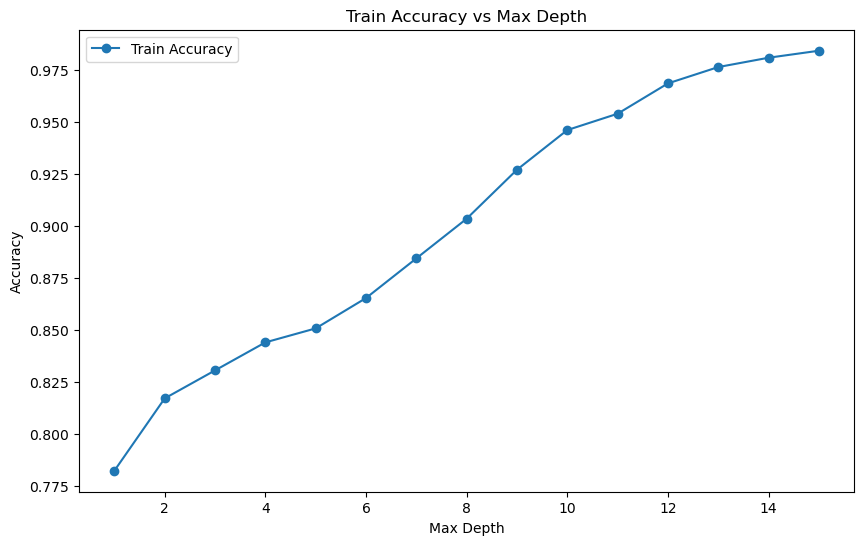

In [22]:
# Visualizamos el desempeño para cada tamaño del árbol
plt.figure(figsize=(10, 6))
plt.plot(depth_range, train_accuracies, label='Train Accuracy', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Train Accuracy vs Max Depth')
plt.legend()
plt.show()

Todo parece indicar que cuanto más profundidad tiene el árbol mejor. Miremos el árbol más grande que ajustamos:

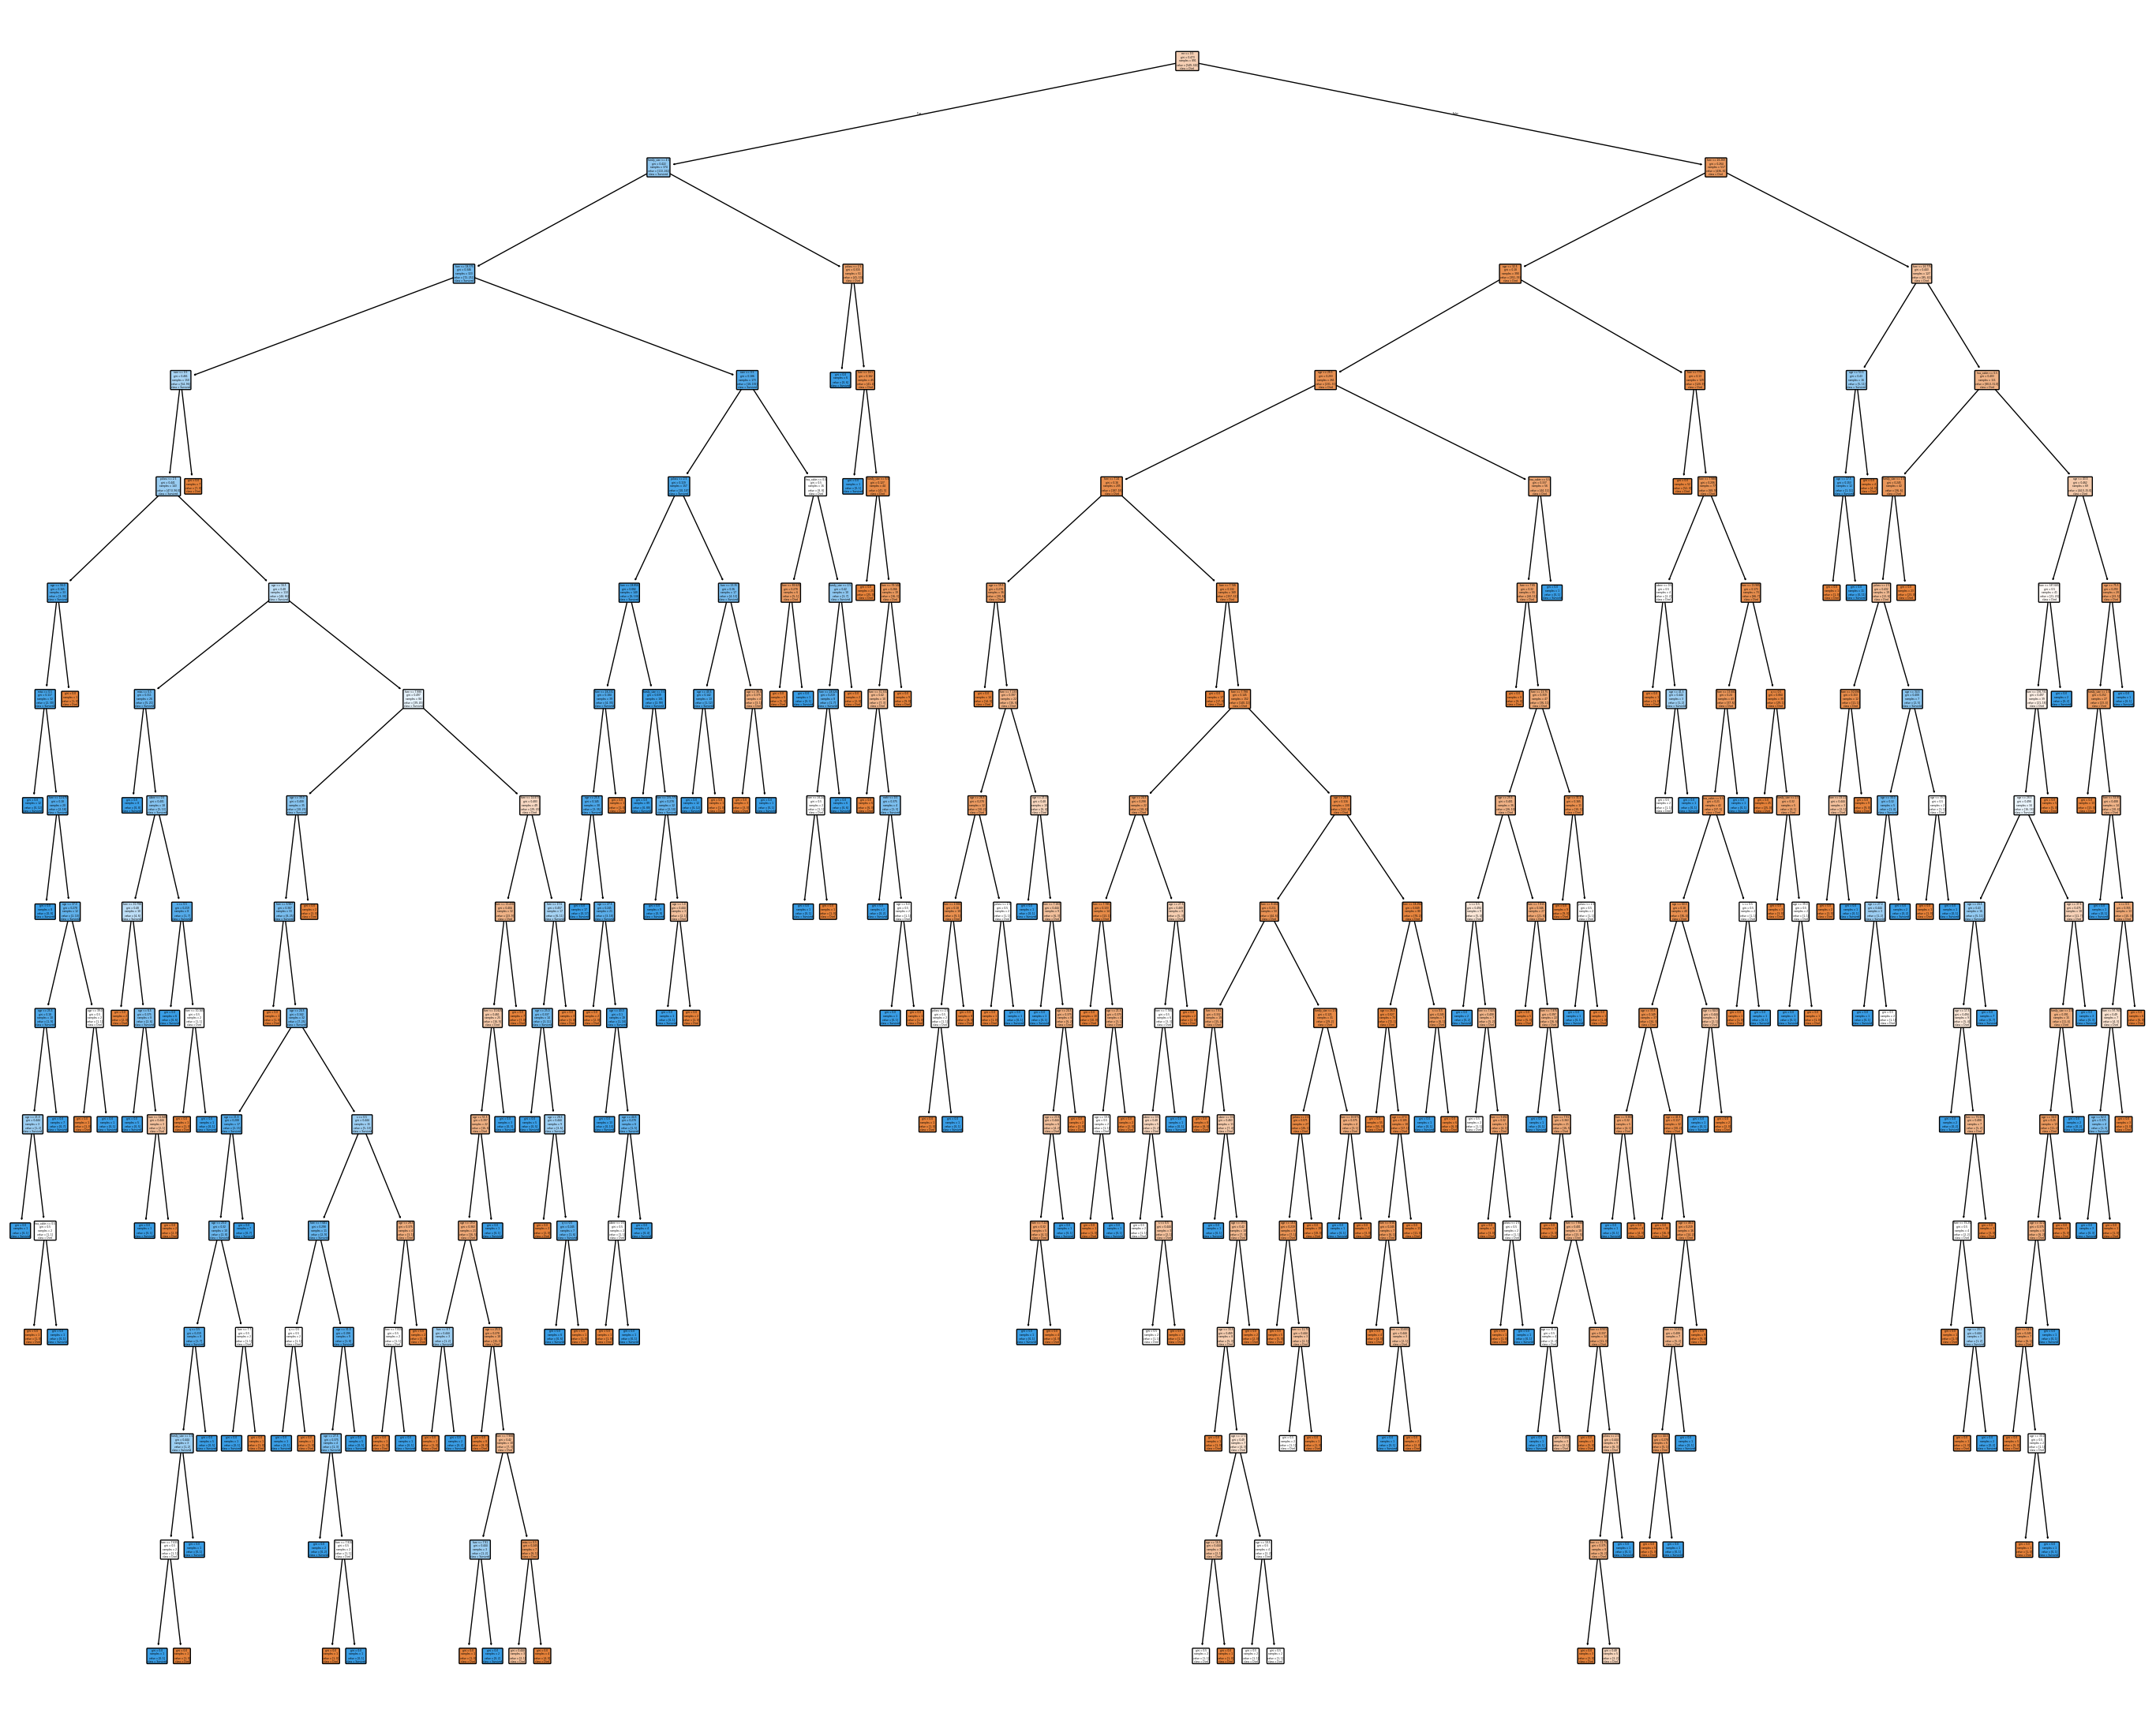

In [23]:
# Creamos un arbol con max_depth = 15
decision_tree = DecisionTreeClassifier(max_depth = 15).fit(X, y)

# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  max_depth = 15,
                  impurity = True,   #mostrar impurity
                  feature_names = list(train.drop(['survived'], axis=1)),
                  class_names = ['Died', 'Survived'],
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Tree_titanic_15.pdf",bbox_inches='tight')

¿Qué creen que puede estar pasando?

Pues sí, estamos sobreajustando.

Para sacarnos de encima este problema usaremos CV para elegir el hiperparámetro de la profundidad del árbol (`max_depth`). Este hiperparámetro determina el número máximo de niveles (cortes sucesivos) que considera el árbol para cada predicción (una misma característica X puede usarse en más de un nivel, así que el máximo no es la cantidad de características Xs disponibles en el dataset).

In [24]:
X = train.drop(['survived'], axis=1)
y = train["survived"]       

Hagamos k-fold cross-validation para encontrar el valor del hiperparámetro `max_depth`. Hagamos un loop sobre los _splits_ a mano:

In [25]:
cv = KFold(n_splits=5, shuffle = True, random_state=1)            
accuracies = []
max_attributes = len(test.columns)
depth_range = range(1, max_attributes + 1) # Recuerdan por qué +1?

for depth in depth_range:
    fold_accuracy = []
    tree_model = DecisionTreeClassifier(max_depth = depth)
    
    for i, (train_index, valid_index) in enumerate(cv.split(X)):   
        x_train, x_valid = X.loc[train_index], X.loc[valid_index] 
        y_train, y_valid = y.loc[train_index], y.loc[valid_index] 
    
        model = tree_model.fit(x_train, y_train) 
        valid_acc = model.score(x_valid, y_valid)
        fold_accuracy.append(valid_acc)

    avg = sum(fold_accuracy)/len(fold_accuracy)
    accuracies.append(avg)
    
df = pd.DataFrame({"Max Depth": depth_range, "Average Accuracy": accuracies})
df = df[["Max Depth", "Average Accuracy"]]
print(df.to_string(index=False))

 Max Depth  Average Accuracy
         1          0.769952
         2          0.769958
         3          0.820444
         4          0.807055
         5          0.802542
         6          0.802517
         7          0.798016
         8          0.793535
         9          0.784552
        10          0.777804
        11          0.772211
        12          0.772211
        13          0.773335


In [26]:
max_index = np.argmax(df['Average Accuracy'])
print("La mayor accuracy de cross validation es para max_depth " + str(max_index + 1) + ", y vale " + str(df['Average Accuracy'][max_index]))

La mayor accuracy de cross validation es para max_depth 3, y vale 0.8204444165463561


Podemos concluir que el hiperparámetro óptimo es `max_depth=3`

Hagamos el mismo gridsearch pero con `GridSearchCV`:

In [27]:
tree_para = {'max_depth':depth_range, 'criterion':['gini']}
tree_cv = GridSearchCV(DecisionTreeClassifier(), tree_para, cv=5, scoring='accuracy')
tree_cv.fit(X, y)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini'], 'max_depth': range(1, 14)},
             scoring='accuracy')

In [28]:
print("Best Parameters:", tree_cv.best_params_)
print("Best Accuracy Score:", tree_cv.best_score_.round(2))

Best Parameters: {'criterion': 'gini', 'max_depth': 3}
Best Accuracy Score: 0.82


Da diferente el valor de _accuracy_ de CV. Podemos cambiar el valor de `random_state` más arriba y ver cómo cambia justamente el valor de la _accuracy_.

Este tipo de selección del hiperparámetro que hace un árbol más chico puede considerarse una técnica de pre-prunning (diferente al *prunning* tradicional que que veremos en la **Opcion 3**).

Ahora que ya tenemos el valor del hiperparámetro ajustemos un árbol con todos los datos de _train_.

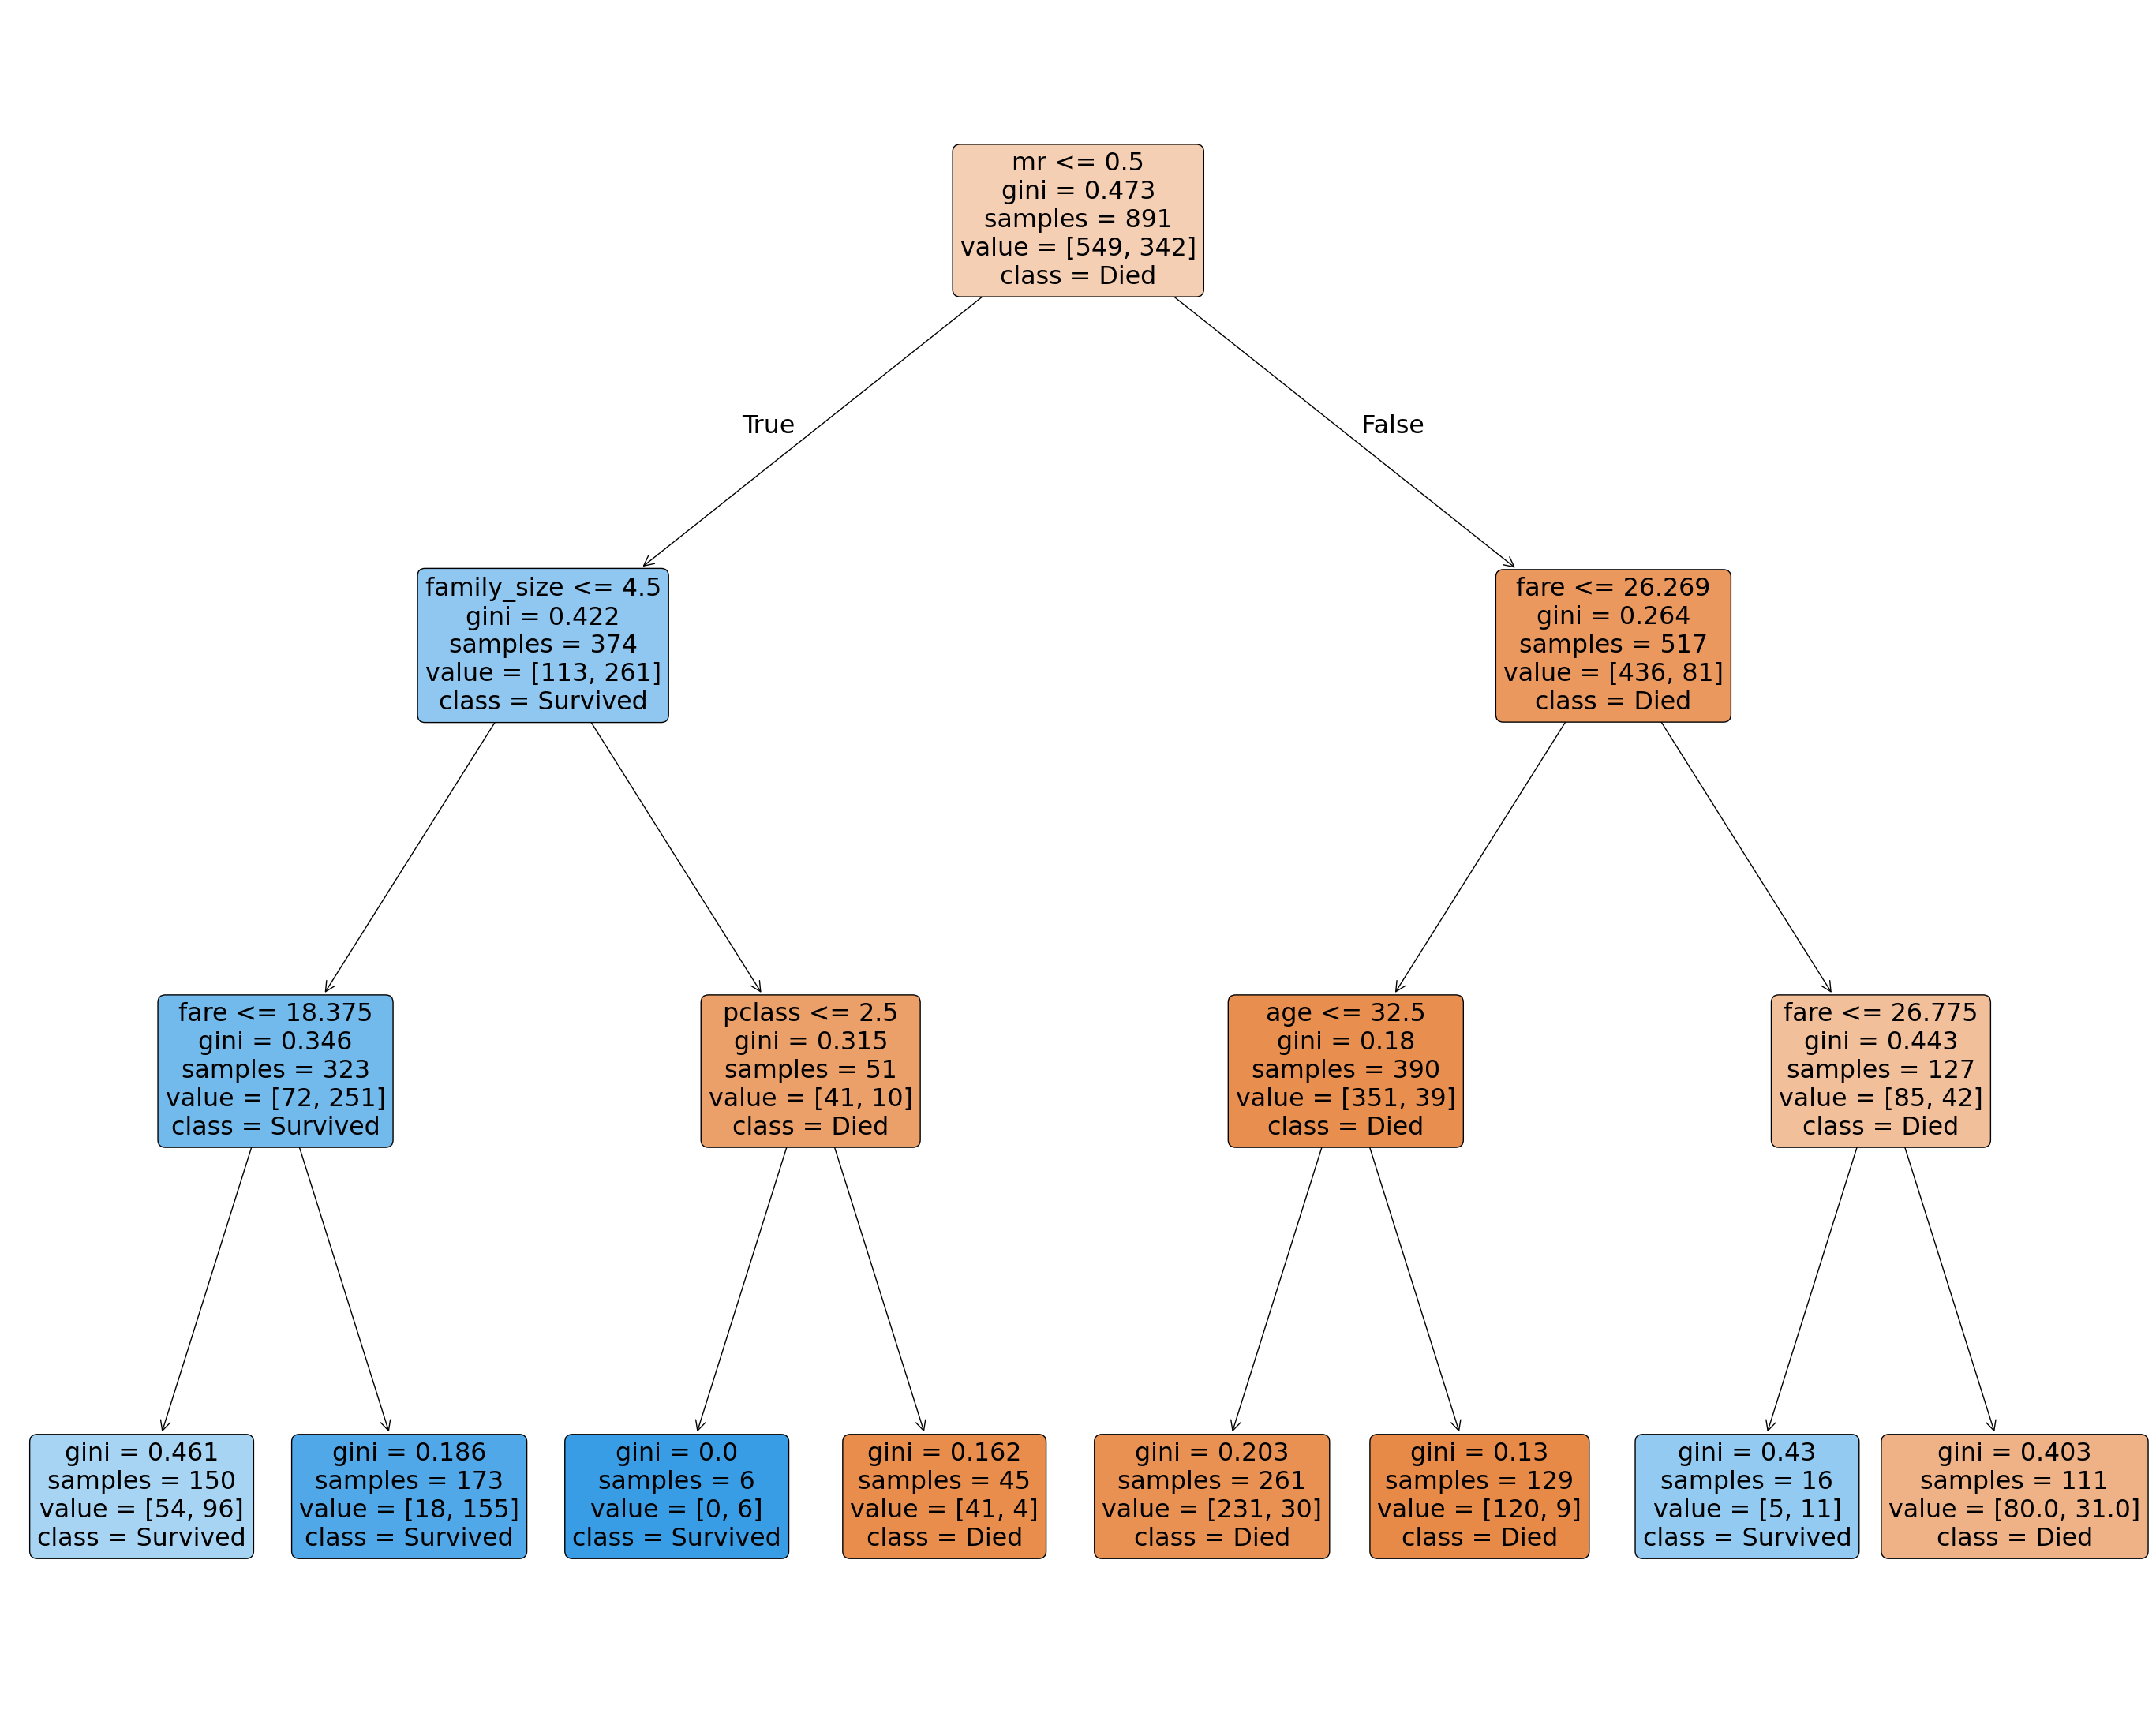

In [29]:
# Creamos un arbol con max_depth = 3
decision_tree = DecisionTreeClassifier(max_depth = 3 ).fit(X, y)

# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  max_depth = 3,
                  impurity = True,   #mostrar impurity
                  feature_names = list(train.drop(['survived'], axis=1)),
                  class_names = ['Died', 'Survived'],
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Tree_titanic_cv_max_depth.pdf",bbox_inches='tight')


#### 2. Opcion `min_samples_leaf`
La opcion `min_samples_leaf` nos indica cuántas observaciones quedan como mínimo en el nodo terminal y es otra forma de controlar el tamaño de un arbol.


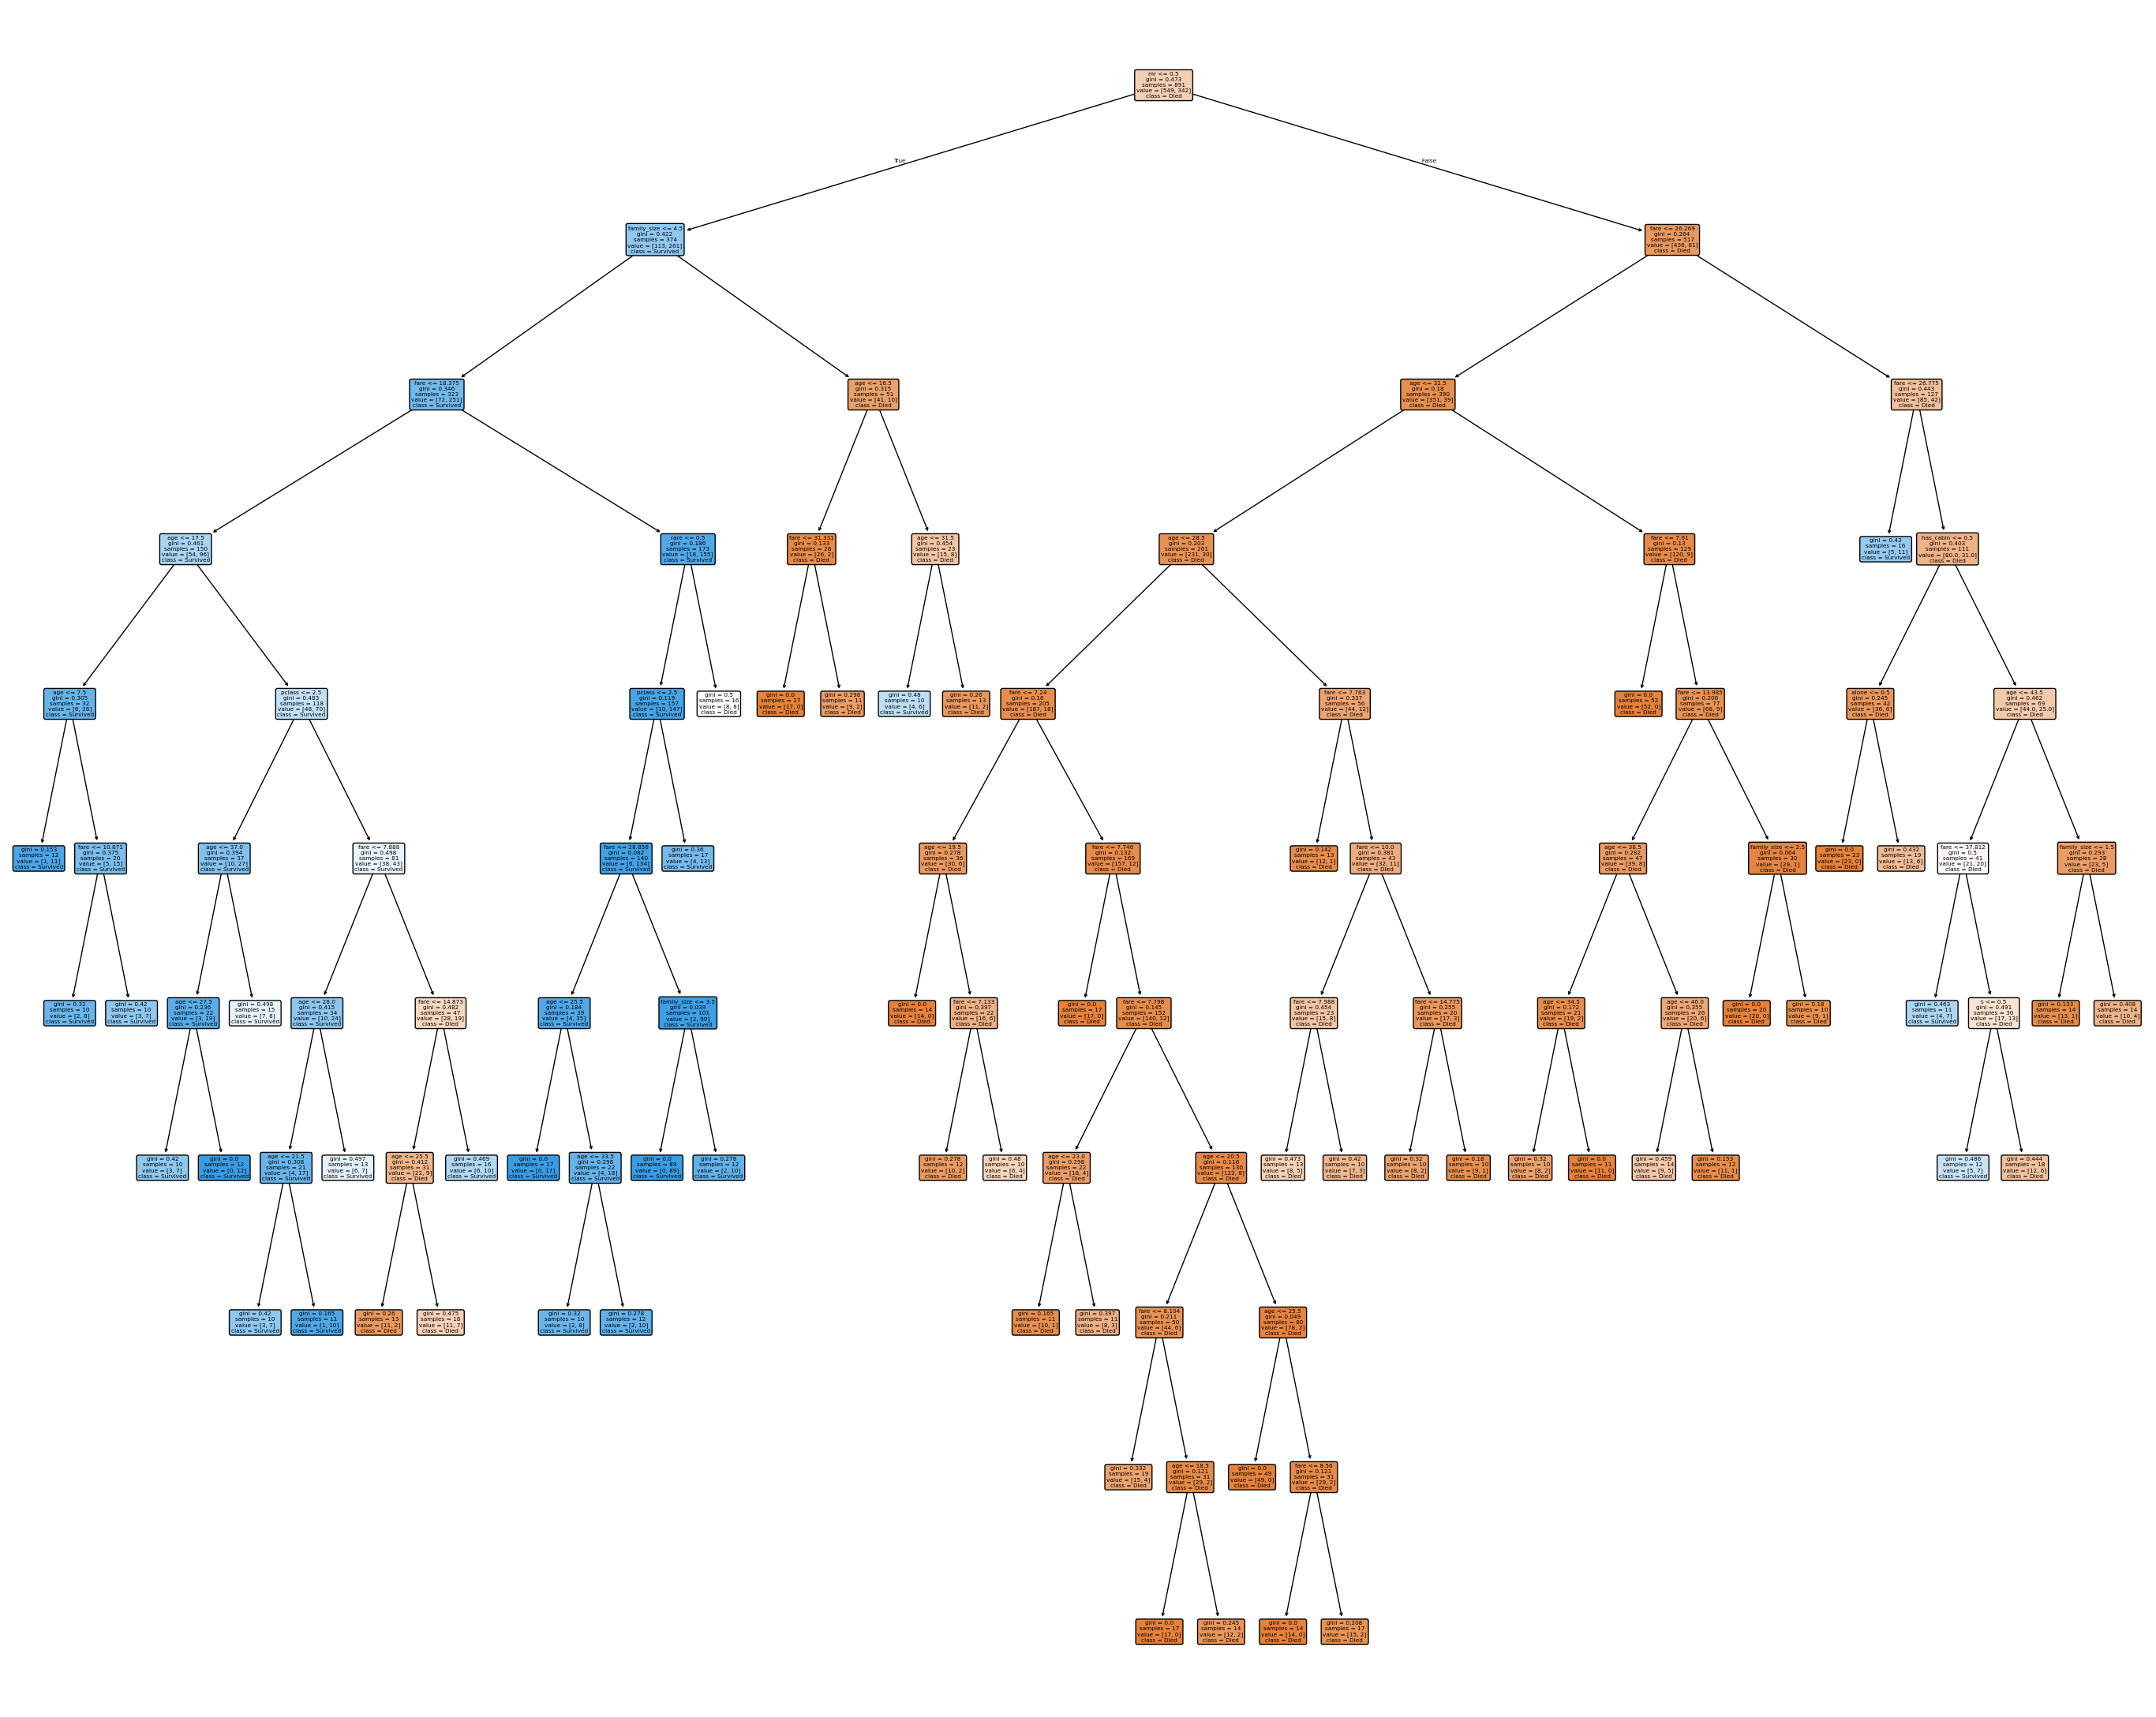

In [30]:
# Ahora, probemos un arbol con 10 observaciones en los nodos terminales como minimo
decision_tree = DecisionTreeClassifier(min_samples_leaf=10).fit(X, y)

# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  impurity = True,   #mostrar impurity
                  feature_names = list(train.drop(['survived'], axis=1)),
                  class_names = ['Died', 'Survived'],
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Tree_titanic_10obs.pdf",bbox_inches='tight')

In [31]:
#repetimos la busqueda por Cross Validation del tamaño del arbol usando min_samples_leaf

depth_range = [5, 10, 20, 30, 40, 50]

tree_para = {'min_samples_leaf':depth_range, 'criterion':['gini']}
tree_cv = GridSearchCV(DecisionTreeClassifier(), tree_para, cv=5, scoring='accuracy')
tree_cv.fit(X, y)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini'],
                         'min_samples_leaf': [5, 10, 20, 30, 40, 50]},
             scoring='accuracy')

In [32]:
print("Best Parameters:", tree_cv.best_params_)
print("Best Accuracy Score:", tree_cv.best_score_)

Best Parameters: {'criterion': 'gini', 'min_samples_leaf': 40}
Best Accuracy Score: 0.8159312033142928


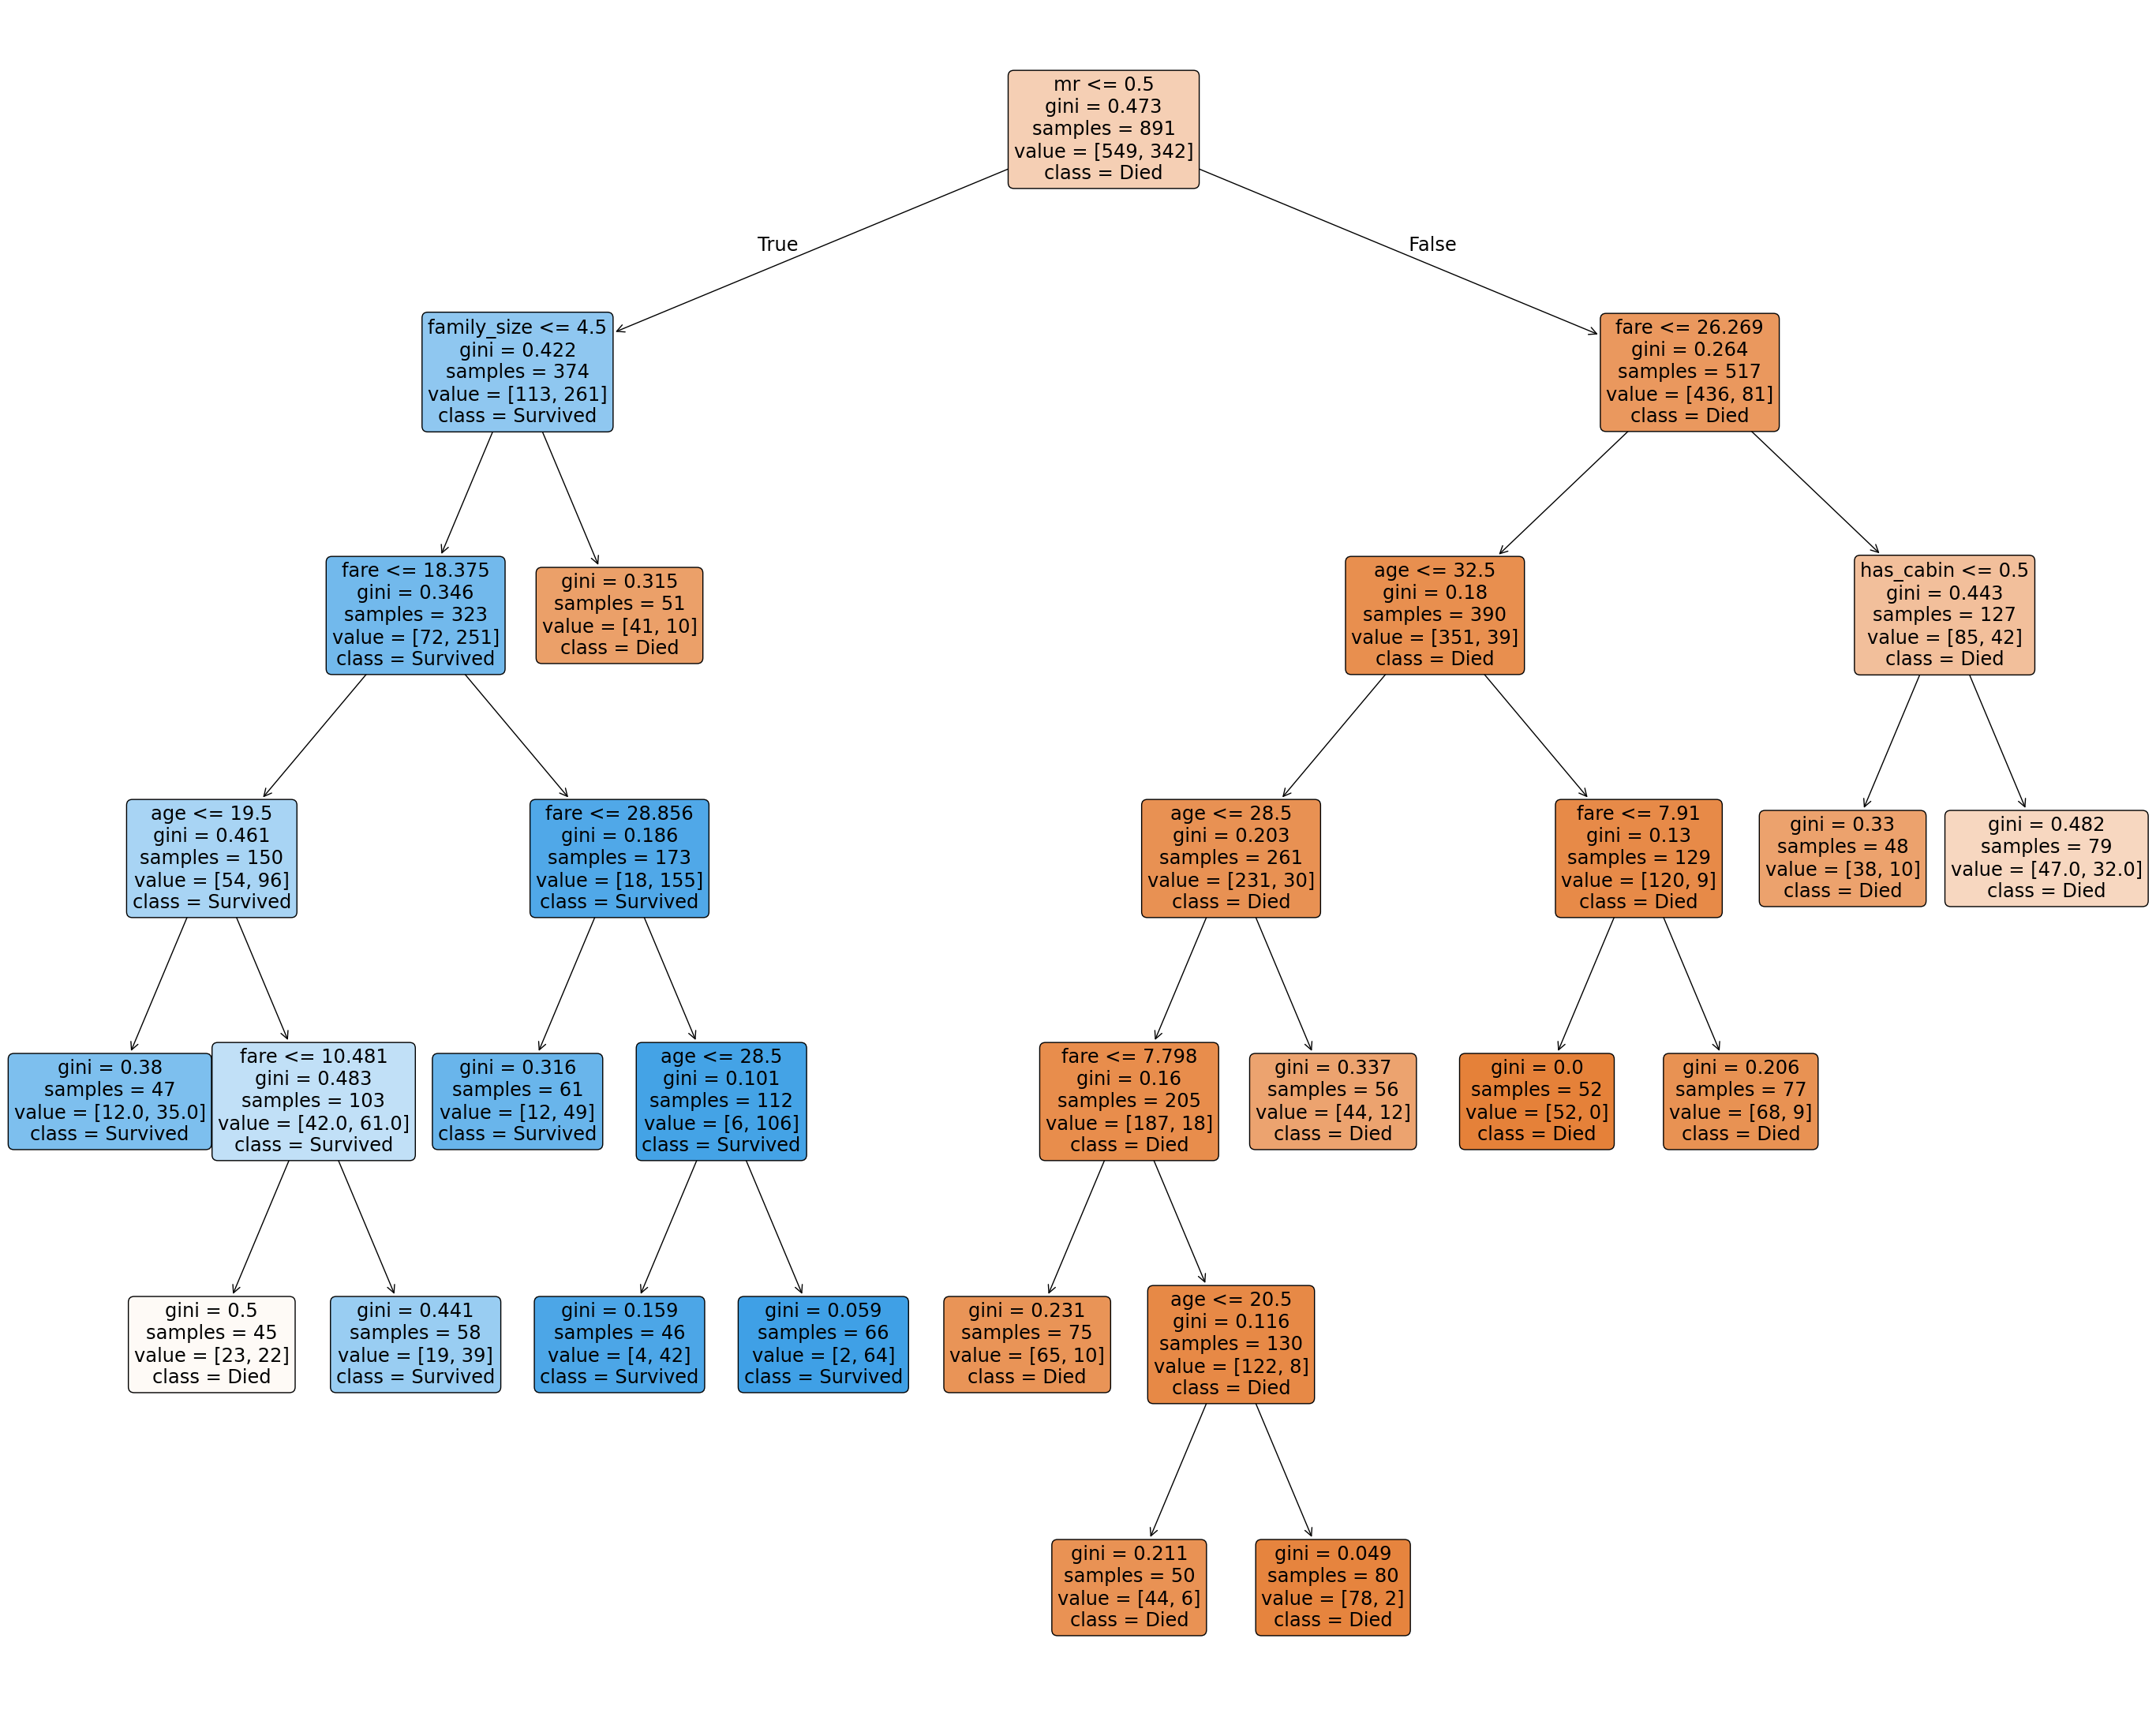

In [33]:
# Creamos un arbol con 'min_samples_leaf': 40
decision_tree = DecisionTreeClassifier(min_samples_leaf = 40).fit(X, y)

# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  impurity = True,   #mostrar impurity
                  feature_names = list(train.drop(['survived'], axis=1)),
                  class_names = ['Died', 'Survived'],
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Tree_titanic_min_obs_cv_20.pdf",bbox_inches='tight')


#### 3. Opción `ccp_aplha`: Podar un árbol con una función de costo de complejidad
Como vimos en clase, podemos elegir "podar un árbol" usando una penalidad por tener muchos nodos terminales (es decir, por un árbol muy profundo) para evitar caer en el *overfitting*.

En las funciones de `DecisionTreeClassifier()` y `DecisionTreeRegression()` (que veremos más abajo), se define el costo de complejidad $R_{\alpha}(T)$ de un árbol inicial $T$ como:

$$
R_{\alpha}(T) = R(T) +\alpha |\tilde{T}|
$$

Donde $|\tilde{T}|$ es el número de nodos terminales $T$ y $R(T)$ se define como el total de impureza (Gini) en los nodos terminales.


In [34]:
# Ahora, probemos un alpha=0.01
decision_tree = DecisionTreeClassifier(ccp_alpha=0.01).fit(X, y)

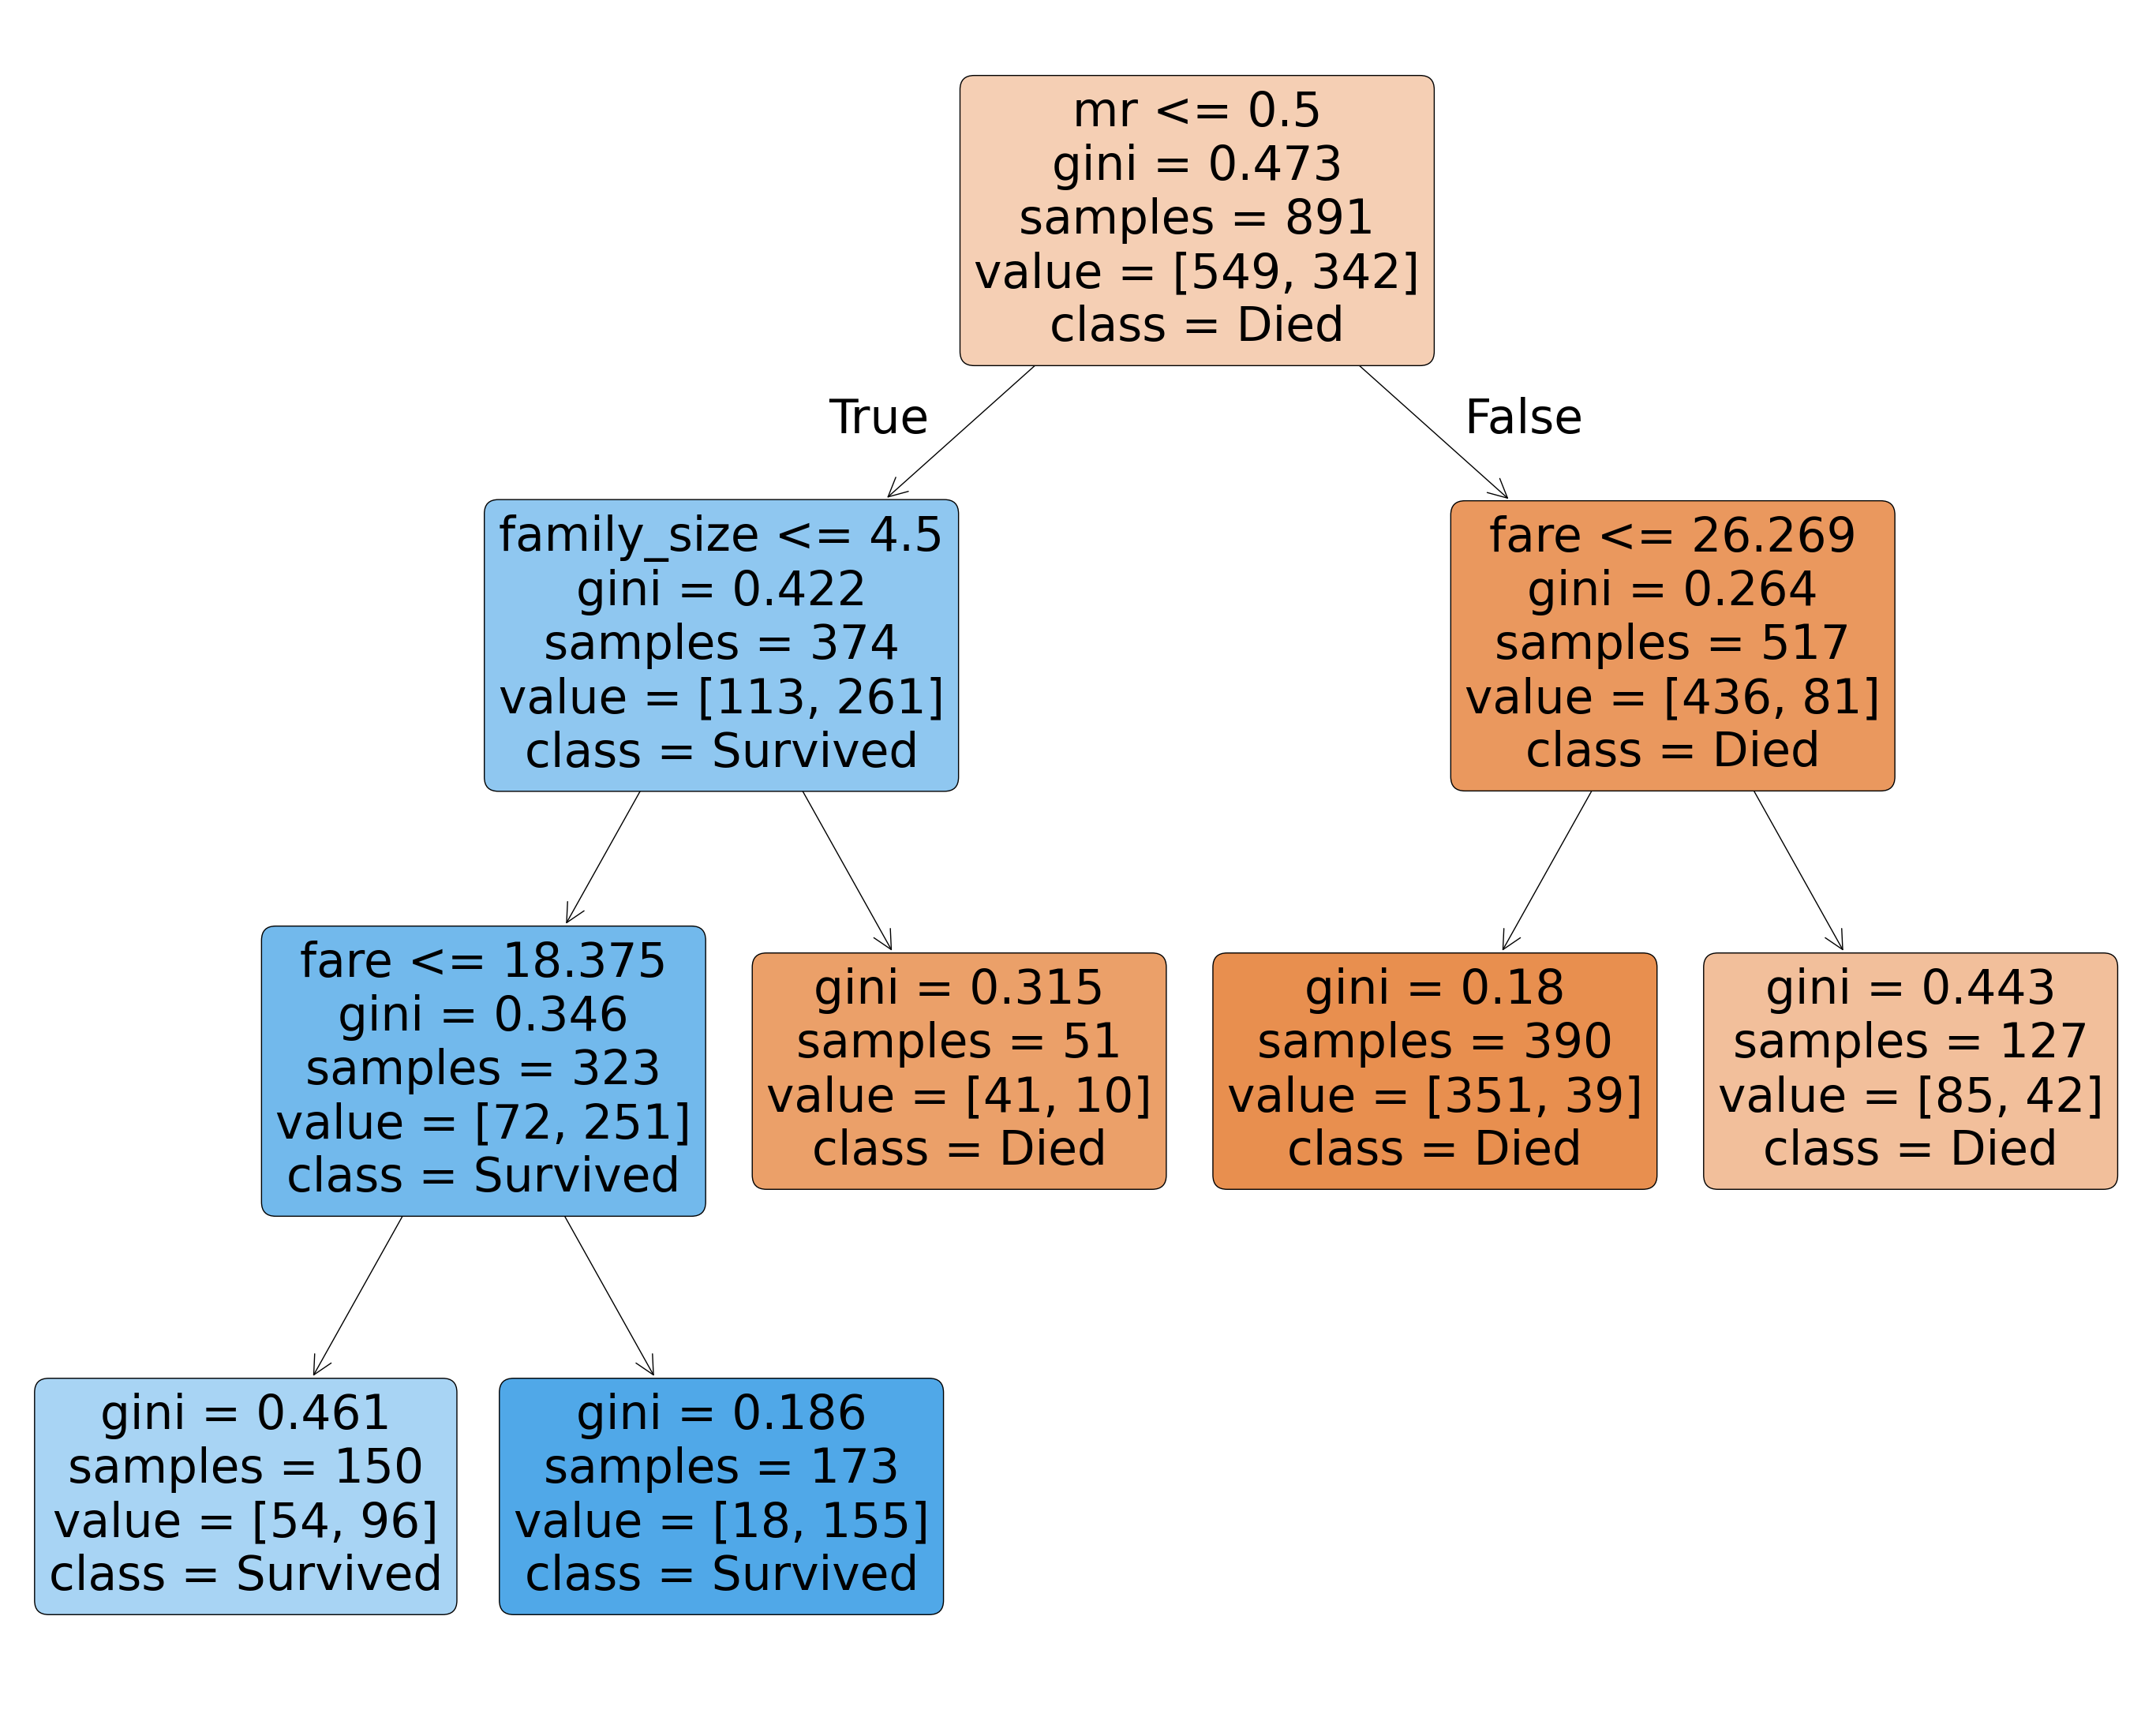

In [35]:
# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  impurity = True,   #mostrar impurity
                  feature_names = list(train.drop(['survived'], axis=1)),
                  class_names = ['Died', 'Survived'],
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Tree_titanic_ccp_aplha_01.pdf",bbox_inches='tight')

**Pregunta:** Cómo cambia el número de nodos terminales $T$ con mayor costo de complejidad $\alpha$?

[0.0001 0.0007 0.0013 0.0019 0.0025 0.0031 0.0037 0.0043 0.0049 0.0055]


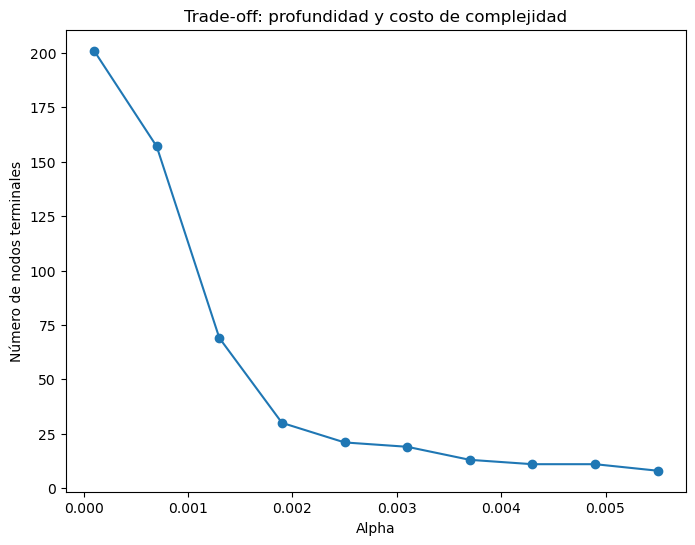

In [36]:
# Definimos la grilla de valores de alpha
import numpy as np

alpha_values = np.linspace(0.0001, 0.0055, 10)
print(alpha_values)

# Estimamos los árboles de decisión y contar el número de nodos terminales
n_leaves = []
for a in alpha_values:
    decision_tree = DecisionTreeClassifier(ccp_alpha=a).fit(X, y)
    n_leaves.append(decision_tree.tree_.n_leaves)

# Creamos el gráfico
plt.figure(figsize=(8, 6))
plt.plot(alpha_values, n_leaves, marker='o')
plt.xlabel('Alpha')
plt.ylabel('Número de nodos terminales')
plt.title('Trade-off: profundidad y costo de complejidad')
plt.show()

##### Costo de complejidad por Cross-Validation
Como siempre, elegimos este parámetro de tunning por cross-validation

In [37]:
tree_para = {'ccp_alpha':alpha_values, 'criterion':['gini']}
tree_cv = GridSearchCV(DecisionTreeClassifier(), tree_para, cv=5, scoring='accuracy')
tree_cv.fit(X, y)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'ccp_alpha': array([0.0001, 0.0007, 0.0013, 0.0019, 0.0025, 0.0031, 0.0037, 0.0043,
       0.0049, 0.0055]),
                         'criterion': ['gini']},
             scoring='accuracy')

In [38]:
print("Best Parameters:", tree_cv.best_params_)
print("Best Accuracy Score:", tree_cv.best_score_.round(2))

Best Parameters: {'ccp_alpha': np.float64(0.0019), 'criterion': 'gini'}
Best Accuracy Score: 0.82


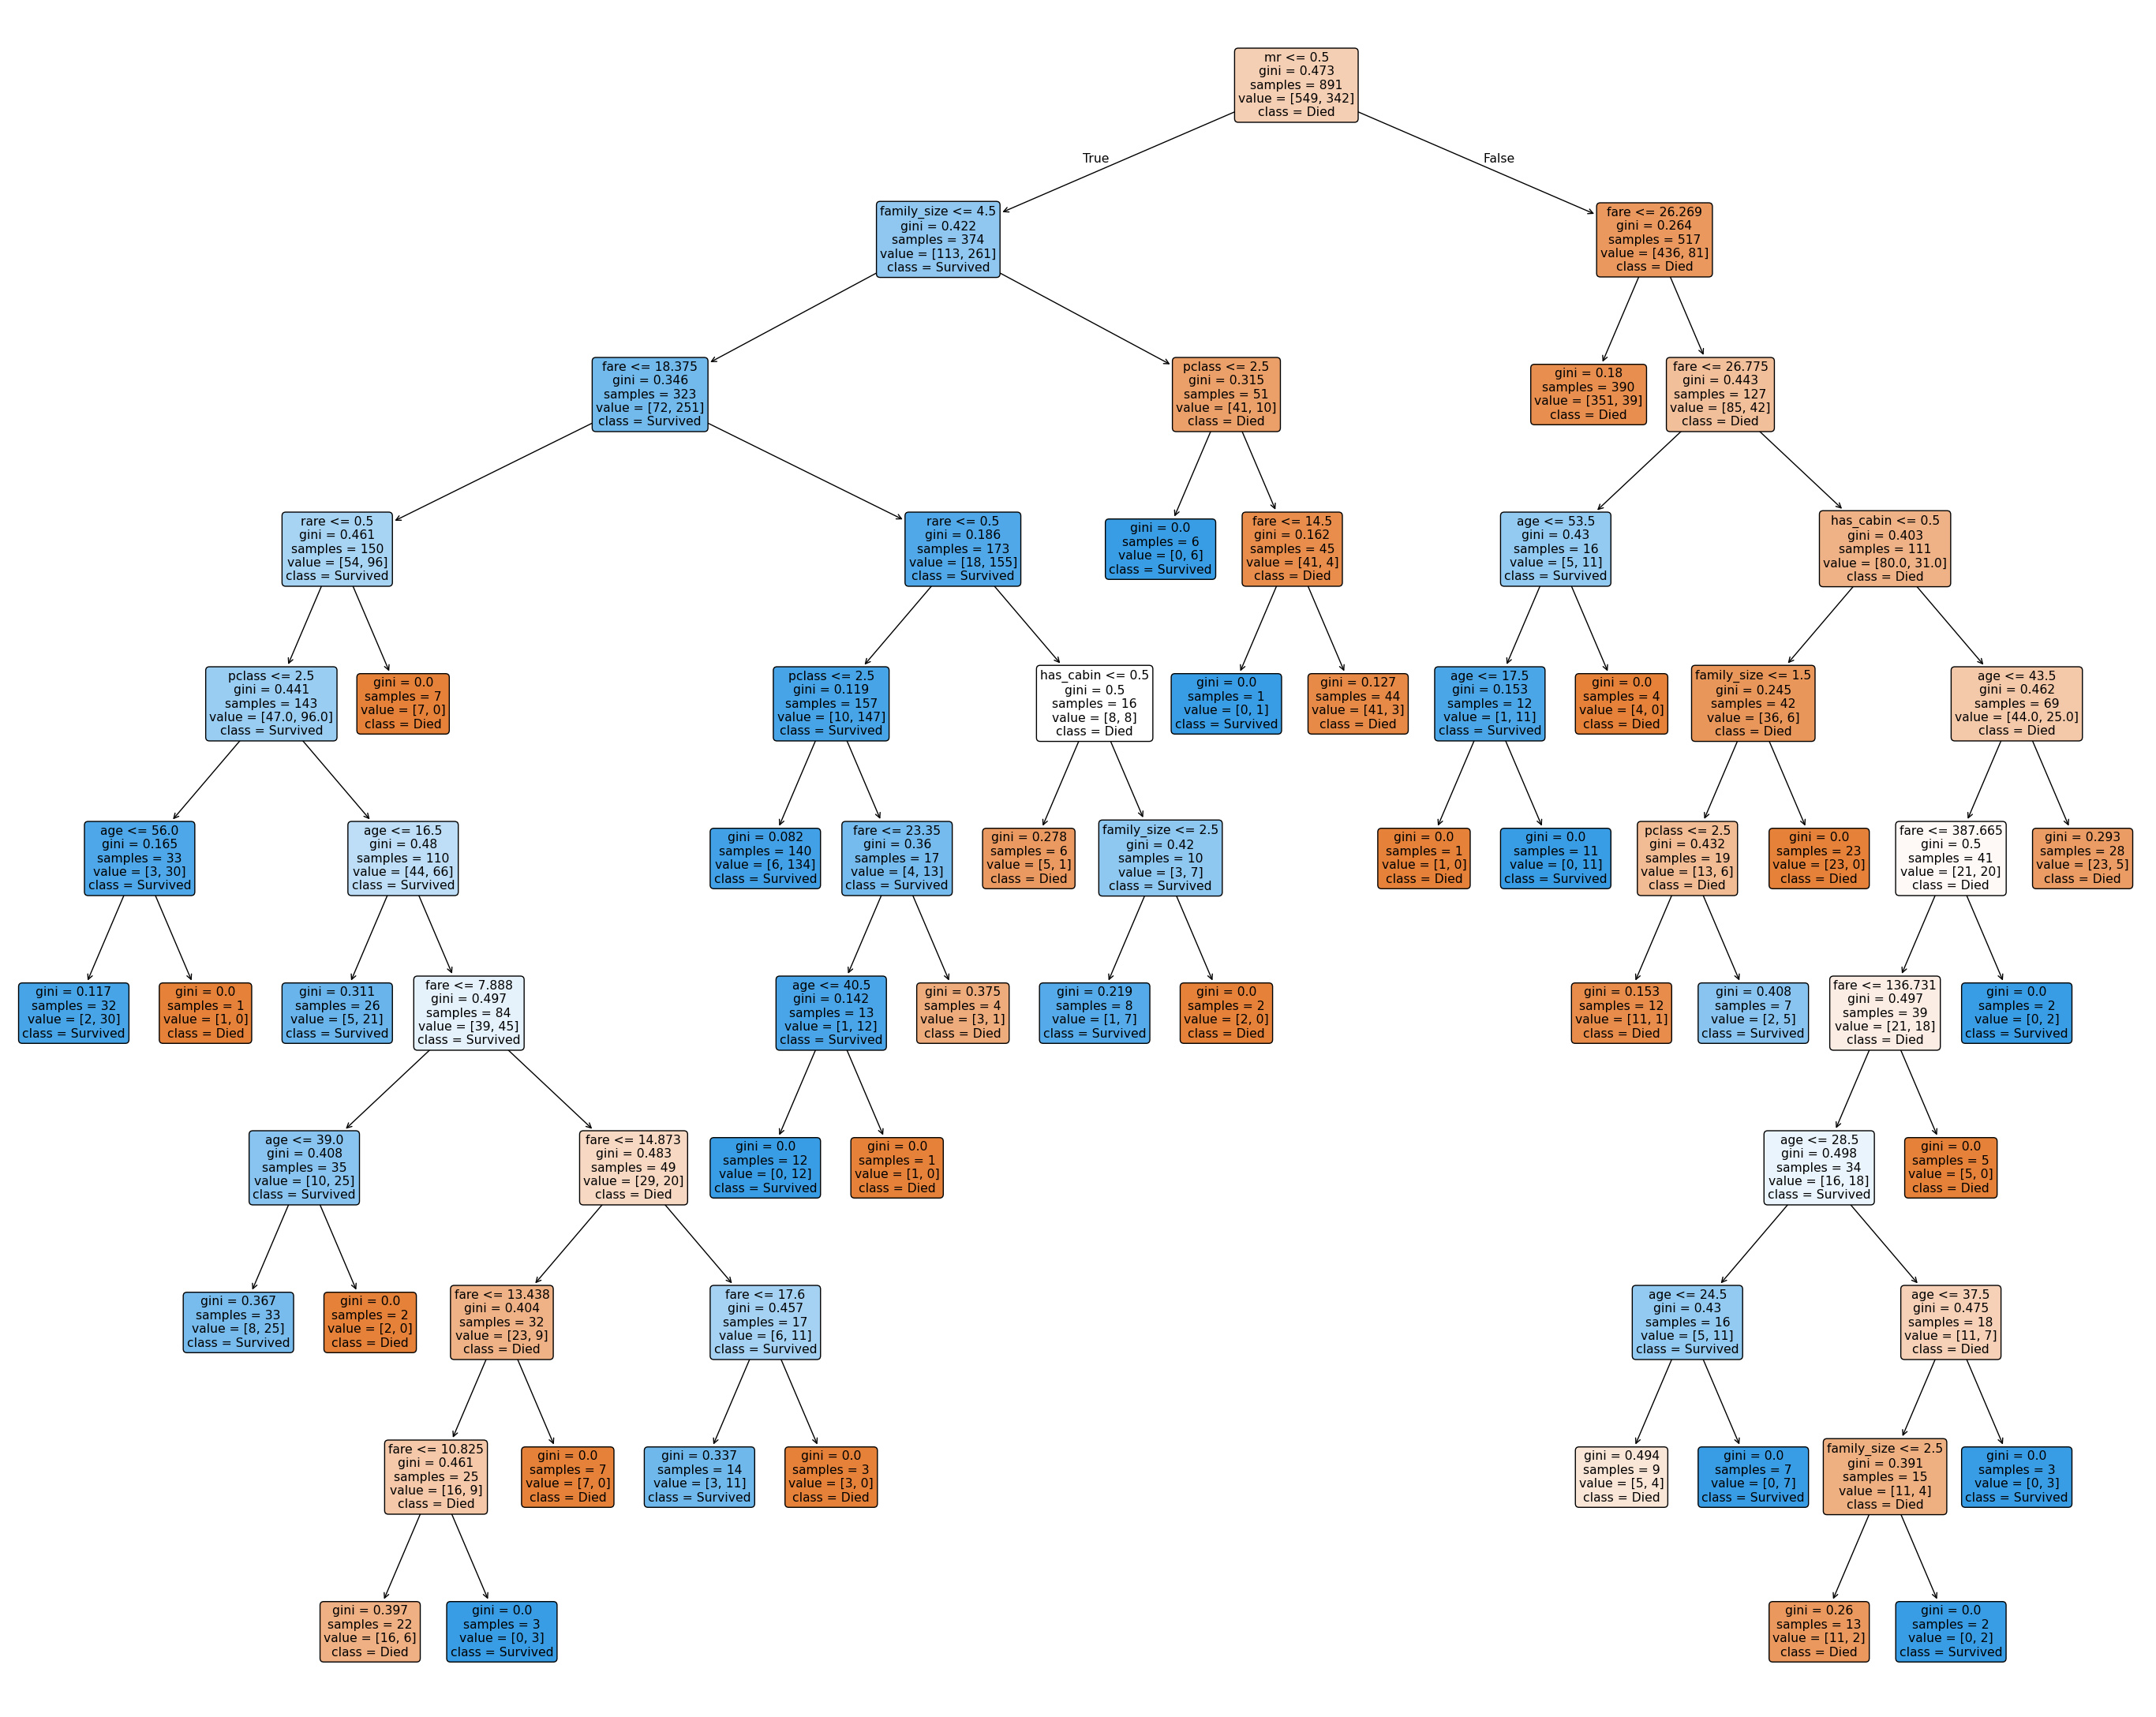

In [39]:
# Creamos un arbol con 'ccp_alpha': 0.0019
decision_tree = DecisionTreeClassifier(ccp_alpha = 0.0019).fit(X, y)

# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  impurity = True,   #mostrar impurity
                  feature_names = list(train.drop(['survived'], axis=1)),
                  class_names = ['Died', 'Survived'],
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Tree_titanic_cv_prunned.pdf",bbox_inches='tight')

### Performance del modelo *dentro de la muestra*

Recordemos que no es lo mismo el accuracy *dentro* versus *afuera de la muestra*. Acá *deberíamos* calcular la precisión del modelo final con la base de test (afuera de la muestra). Pero como estamos trabajando con la base de datos de la competencia, la **$y_{test}$ no la hicieron pública**. 

El **resultado final** a entregar en la competencia era la predicción de sobrevivientes sobre los ID de los pasajeros. 

In [40]:
acc_decision_tree = decision_tree.score(X, y)
print("Accuracy train",np.round(acc_decision_tree,3))

Accuracy train 0.9


In [41]:
# Tarea para la casa: armar la curva ROC para el best_tree 

#### Vamos a hacer la predicción sobre los datos de *testeo*. 
Esto es lo que hay que "entregar" en la competencia. La predicción final con "el mejor modelo posible" que tenga menor tasa de error de prediccion *afuera de la muestra*.

In [42]:
# Datos de test
test = test.dropna()  
X_test = test

# Predicción sobre los datos de test
y_pred = decision_tree.predict(X_test)
submission = pd.DataFrame({"passengerId": passenger_id, "survived_hat": y_pred})
submission.head()

,passengerId,survived_hat
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


### Árboles de regresión

En este caso vamos a usar un árbol de regresión para predecir el salario de los jugadores de la MLB utilizando la, ya conocida, base de datos `Hitters`.

En este caso no se minimiza el Gini sino en MSE pesado. Es decir, si definimos MSE como:


$\text{MSE}(N) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \bar{y})^2$

Cuando se propone una división, se calcula el MSE ponderado de los nodos izquierdo y derecho resultantes, con el objetivo de minimizar este MSE ponderado. La fórmula para el MSE ponderado de una división es:

$\text{MSE}_{\text{split}} = \frac{n_L}{n} \cdot \text{MSE}(N_L) + \frac{n_R}{n} \cdot \text{MSE}(N_R)$

Donde $\text{MSE}(N_L)$ y $\text{MSE}(N_L)$ son los valores MSE de los nodos  izquierdo y derecho, calculados de forma similar al MSE de un único nodo. $n=n_L+n_R$ es la cantidad de observaciones del nodo padre que se divide en un nodo de $n_L$ observaciones y uno de $n_R$ observaciones.

Carguemos los datos y las librerías necesarias.


In [43]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

from ISLP import load_data
from sklearn.preprocessing import StandardScaler

In [44]:
Hitters = load_data('Hitters')
Hitters

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,497,127,7,65,48,37,5,2703,806,32,379,311,138,N,E,325,9,3,700.0,N
318,492,136,5,76,50,94,12,5511,1511,39,897,451,875,A,E,313,381,20,875.0,A
319,475,126,3,61,43,52,6,1700,433,7,217,93,146,A,W,37,113,7,385.0,A
320,573,144,9,85,60,78,8,3198,857,97,470,420,332,A,E,1314,131,12,960.0,A


In [45]:
print('Dimensión de la base:', Hitters.shape, '\n')
#Vemos los missing values en Y
print('\nMissings en variable dependiente:', np.isnan(Hitters['Salary']).sum())


Dimensión de la base: (322, 20) 


Missings en variable dependiente: 59


Cargamos los datos, los acomodamos y estandarizamos (recuerden hay valores expremos como un 'Messi' del baisball)

In [46]:
# Nos sacamos de encima los missings values
Hitters = Hitters.dropna() 
print('\n Nueva dimensión de la base:', Hitters.shape)

# Separamos en X e y
y = Hitters['Salary']

# Creamos variables dummies para las variables string
dummies = pd.get_dummies(Hitters[['League', 'Division', 'NewLeague']], drop_first=True)

#reseteamos el index 
dummies = dummies.reset_index(drop=True)

# Eliminamos salarios (porque es nuestra y) y las columnas de strings
X_num = Hitters.drop(['Salary', 'League', 'Division', 'NewLeague'], axis=1).astype('float64')

#reseteamos el index 
X_num = X_num.reset_index(drop=True) # index original es descartado

#___ Estandarizamos las observaciones_______#

# Iniciamos el Standard Scaler
sc = StandardScaler()
X_transformed = pd.DataFrame(sc.fit_transform(X_num),index=X_num.index, columns=X_num.columns)

# Ahora sumamos las dummies como 1s y 0s
X = pd.concat([X_transformed, dummies[['League_N', 'Division_W', 'NewLeague_N']].astype(float)], axis=1)

# Chequeamos la matriz de predictores final que usaremos
X.describe().T.round(2)



 Nueva dimensión de la base: (263, 20)


,count,mean,std,min,25%,50%,75%,max
AtBat,263.0,0.00,1.0,-2.62,-0.82,0.06,0.83,1.93
Hits,263.0,0.00,1.0,-2.37,-0.81,-0.11,0.75,2.89
HmRun,263.0,0.00,1.0,-1.33,-0.76,-0.30,0.73,3.25
Runs,263.0,-0.00,1.0,-2.15,-0.83,-0.11,0.72,2.95
RBI,263.0,0.00,1.0,-1.99,-0.83,-0.17,0.76,2.69
Walks,263.0,0.00,1.0,-1.90,-0.84,-0.19,0.73,2.95
Years,263.0,-0.00,1.0,-1.32,-0.69,-0.27,0.56,3.49
CAtBat,263.0,0.00,1.0,-1.16,-0.80,-0.32,0.54,4.99
CHits,263.0,0.00,1.0,-1.11,-0.79,-0.32,0.51,5.46
CHmRun,263.0,0.00,1.0,-0.84,-0.66,-0.36,0.28,5.84


<Axes: title={'center': 'Correlacion de Pearson entre las Xs'}>

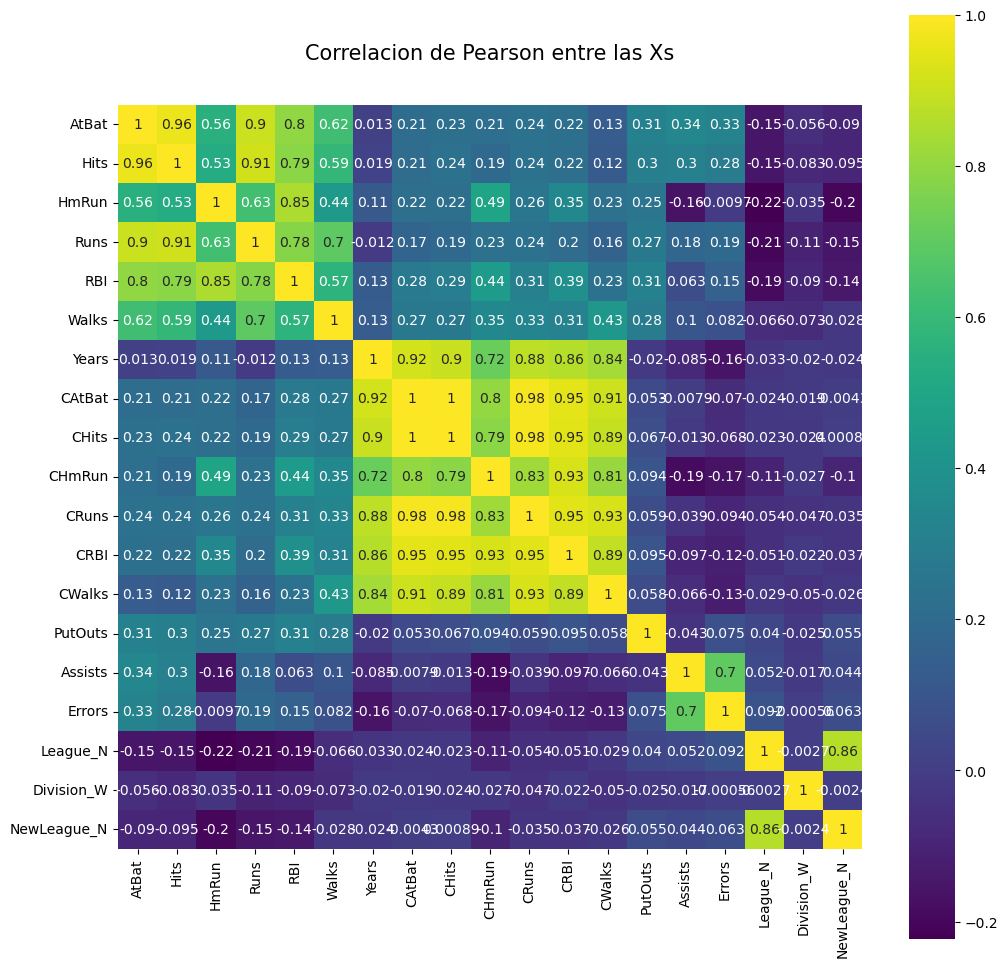

In [47]:
# Visualizamos la correlaciones dentro de la base de entrenamiento
colormap = plt.cm.viridis
plt.figure(figsize=(12,12))
plt.title('Correlacion de Pearson entre las Xs', y=1.05, size=15)
sns.heatmap(X.astype(float).corr(),
            square=True, 
            cmap=colormap, 
            linecolor='white', 
            annot=True)

In [48]:
# No olvidemos mirar la estadistica descriptiva de nuestra variable dependiente: los Salarios
y.describe().round(2)

count     263.00
mean      535.93
std       451.12
min        67.50
25%       190.00
50%       425.00
75%       750.00
max      2460.00
Name: Salary, dtype: float64

**Pregunta:** Cuáles variables muestran alta correlacion lineal?

#### Dividimos la base en observaciones para entrenamiento y testeo

In [49]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100)

# Revisamos cuantas observaciones quedaron para Test y cuantas para Entrenamiento.
print(f'El conjunto de entrenamiento tiene {len(X_train)} observaciones.')
print(f'El conjunto de test tiene {len(X_test)} observaciones.')

El conjunto de entrenamiento tiene 184 observaciones.
El conjunto de test tiene 79 observaciones.


### Ahora inicializamos el árbol de regresión con el default:

In [50]:
tree_regressor = DecisionTreeRegressor(random_state=42)

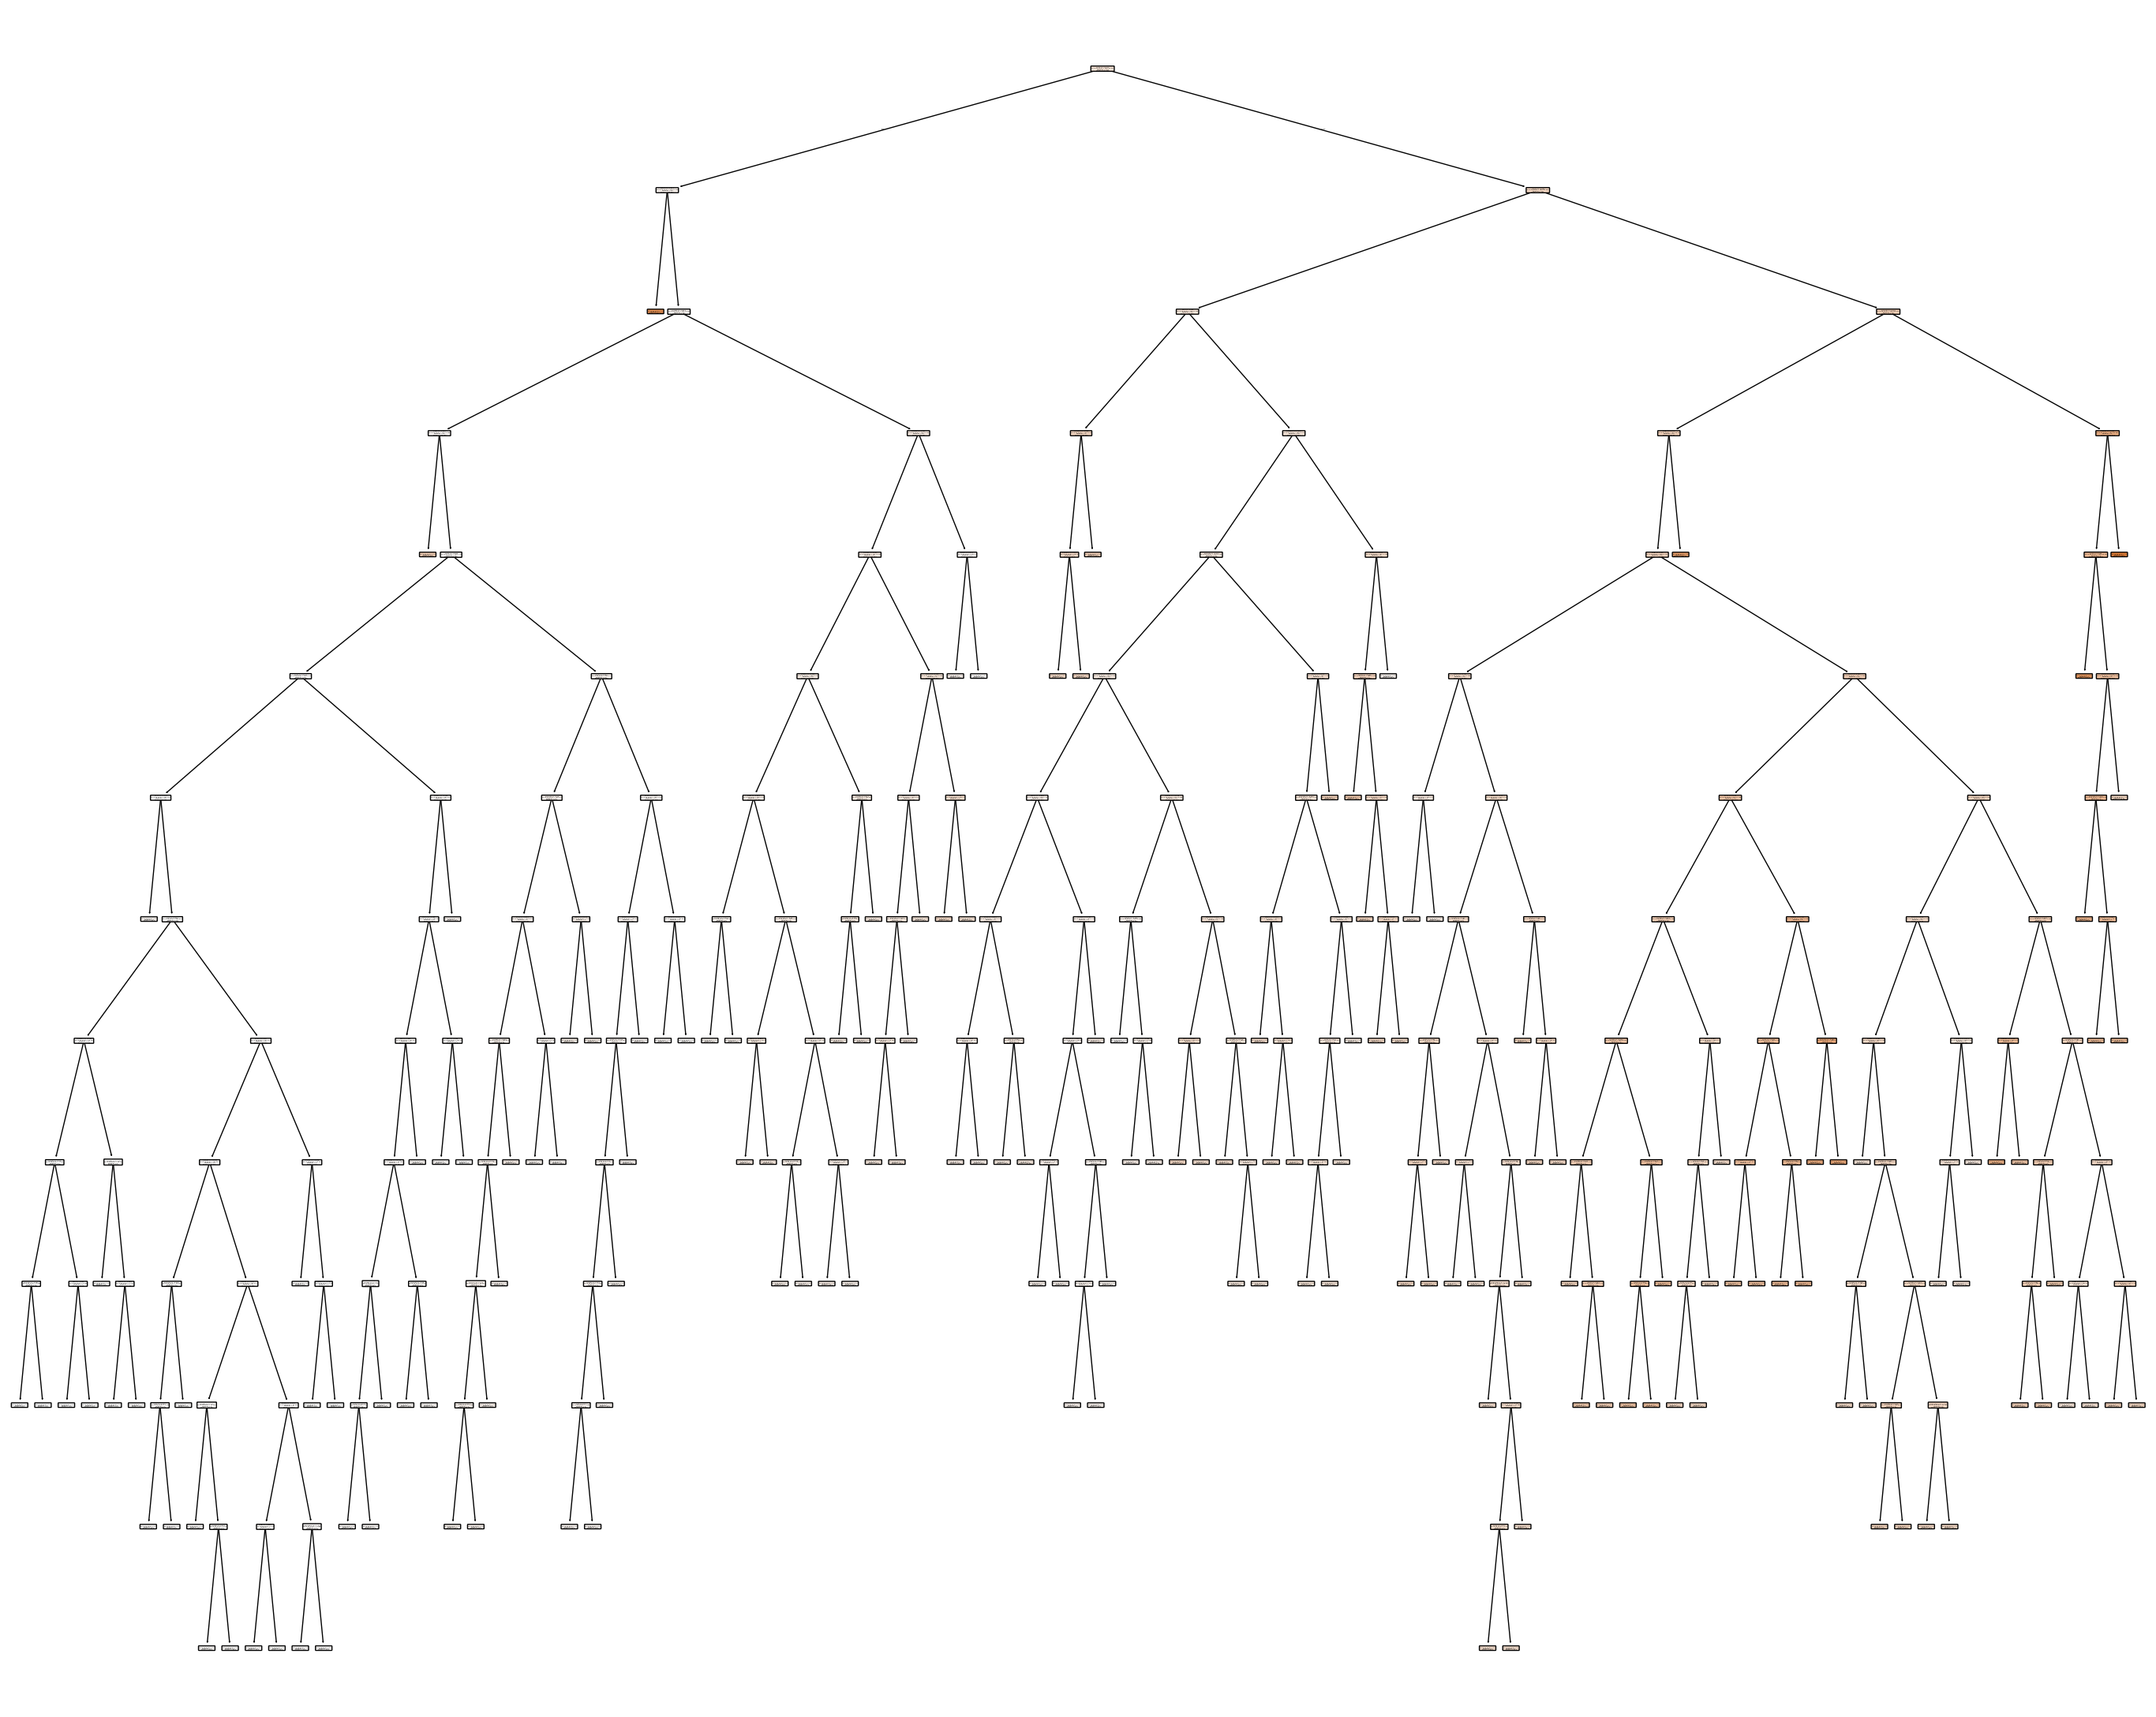

In [51]:
# Primero, probemos un arbol sin tocar ningun parametro (osea usando la configuración por default)
decision_tree = tree_regressor.fit(X_train, y_train)

# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(decision_tree,
                  feature_names = list(X_train),
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Hitters_default.pdf",bbox_inches='tight')

#### 1. Opción `max_depth`
Hagamos algo parecido a lo que hicimos antes pero con el **RMSE**. Veamos cómo varían los errores de train y test a medida que aumentamos la complejidad del modelo.

In [52]:
#distinguimos la performance adentro y afuera de la muestra
train_RMSE = []
test_RMSE = []

depth_range = range(1, 21)  # You can adjust the range as needed

for depth in depth_range:
    tree_model = DecisionTreeRegressor(max_depth=depth)
    tree_model.fit(X_train, y_train)
    
    y_pred_train = tree_model.predict(X_train)
    y_pred_test = tree_model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    
    train_RMSE.append(train_rmse)
    test_RMSE.append(test_rmse)
    

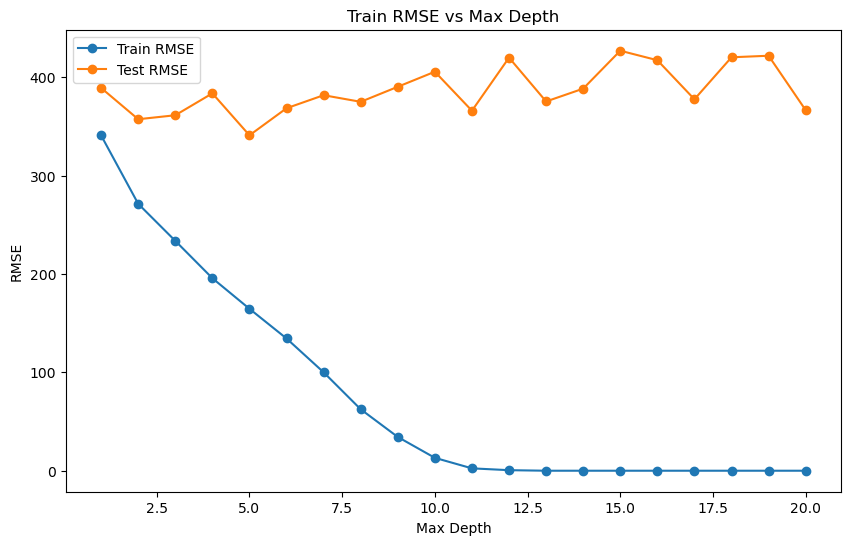

In [53]:
# Plotting the accuracies
plt.figure(figsize=(10, 6))
plt.plot(depth_range, train_RMSE, label='Train RMSE', marker='o')
plt.plot(depth_range, test_RMSE, label='Test RMSE', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('RMSE')
plt.title('Train RMSE vs Max Depth')
plt.legend()
plt.show()

#### Complejidad del árbol de regresión por cross-validation

En este caso además de buscar el mejor valor de `max_depth`, vamos a hacer una grilla de búsqueda para otros hiperparámetros: 
- `min_samples_split`: minimo numero de observaciones que necesita un nodo para poder dividirse (split) 
- `min_samples_leaf`: mínimo numero de observaciones en cada nodo terminal (hojas/leaf) 
- `ccp_alpha`: costo minimo de complejidad para podar un arbol (en las slides 25 el $\alpha$)

In [54]:
# Definimos un rango de valores para los hiperparámetros
param_grid = {
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [ 5, 10, 20],
    'ccp_alpha': [0.0, 0.01, 0.1, 0.5, 1.0]  # Cost Complexity Pruning parameter for post-pruning
}

# Usamos GridSearchCV para encontrar el mejor modelo
grid_search = GridSearchCV(tree_regressor, param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)



GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'ccp_alpha': [0.0, 0.01, 0.1, 0.5, 1.0],
                         'max_depth': [None, 5, 10, 15],
                         'min_samples_leaf': [5, 10, 20],
                         'min_samples_split': [2, 10, 20]},
             scoring='neg_mean_squared_error')

In [55]:
# Extraemos el mejor modelo
best_tree = grid_search.best_estimator_
best_tree

DecisionTreeRegressor(min_samples_leaf=20, random_state=42)

In [56]:
# Hacemos predicciones para evaluar el modelo
y_pred_train = best_tree.predict(X_train)
y_pred_test = best_tree.predict(X_test)

train_mse = mean_squared_error(y_train, y_pred_train)
test_mse = mean_squared_error(y_test, y_pred_test)

print(f"Mejores parámetros para el árbol de regresión: {grid_search.best_params_}")
print(f"MSE de train: {train_mse:.4f}")
print(f"MSE de test: {test_mse:.4f}")

Mejores parámetros para el árbol de regresión: {'ccp_alpha': 0.0, 'max_depth': None, 'min_samples_leaf': 20, 'min_samples_split': 2}
MSE de train: 80030.1994
MSE de test: 114318.1778


Tal vez les parezca un modelo simple, pero tengan en cuenta que con Ridge-CV el MSE de test era **115,974.76** y con Lasso-CV **112,091.67**.

Veamos cómo se ve este árbol de regresión con complejidad optima por CV:

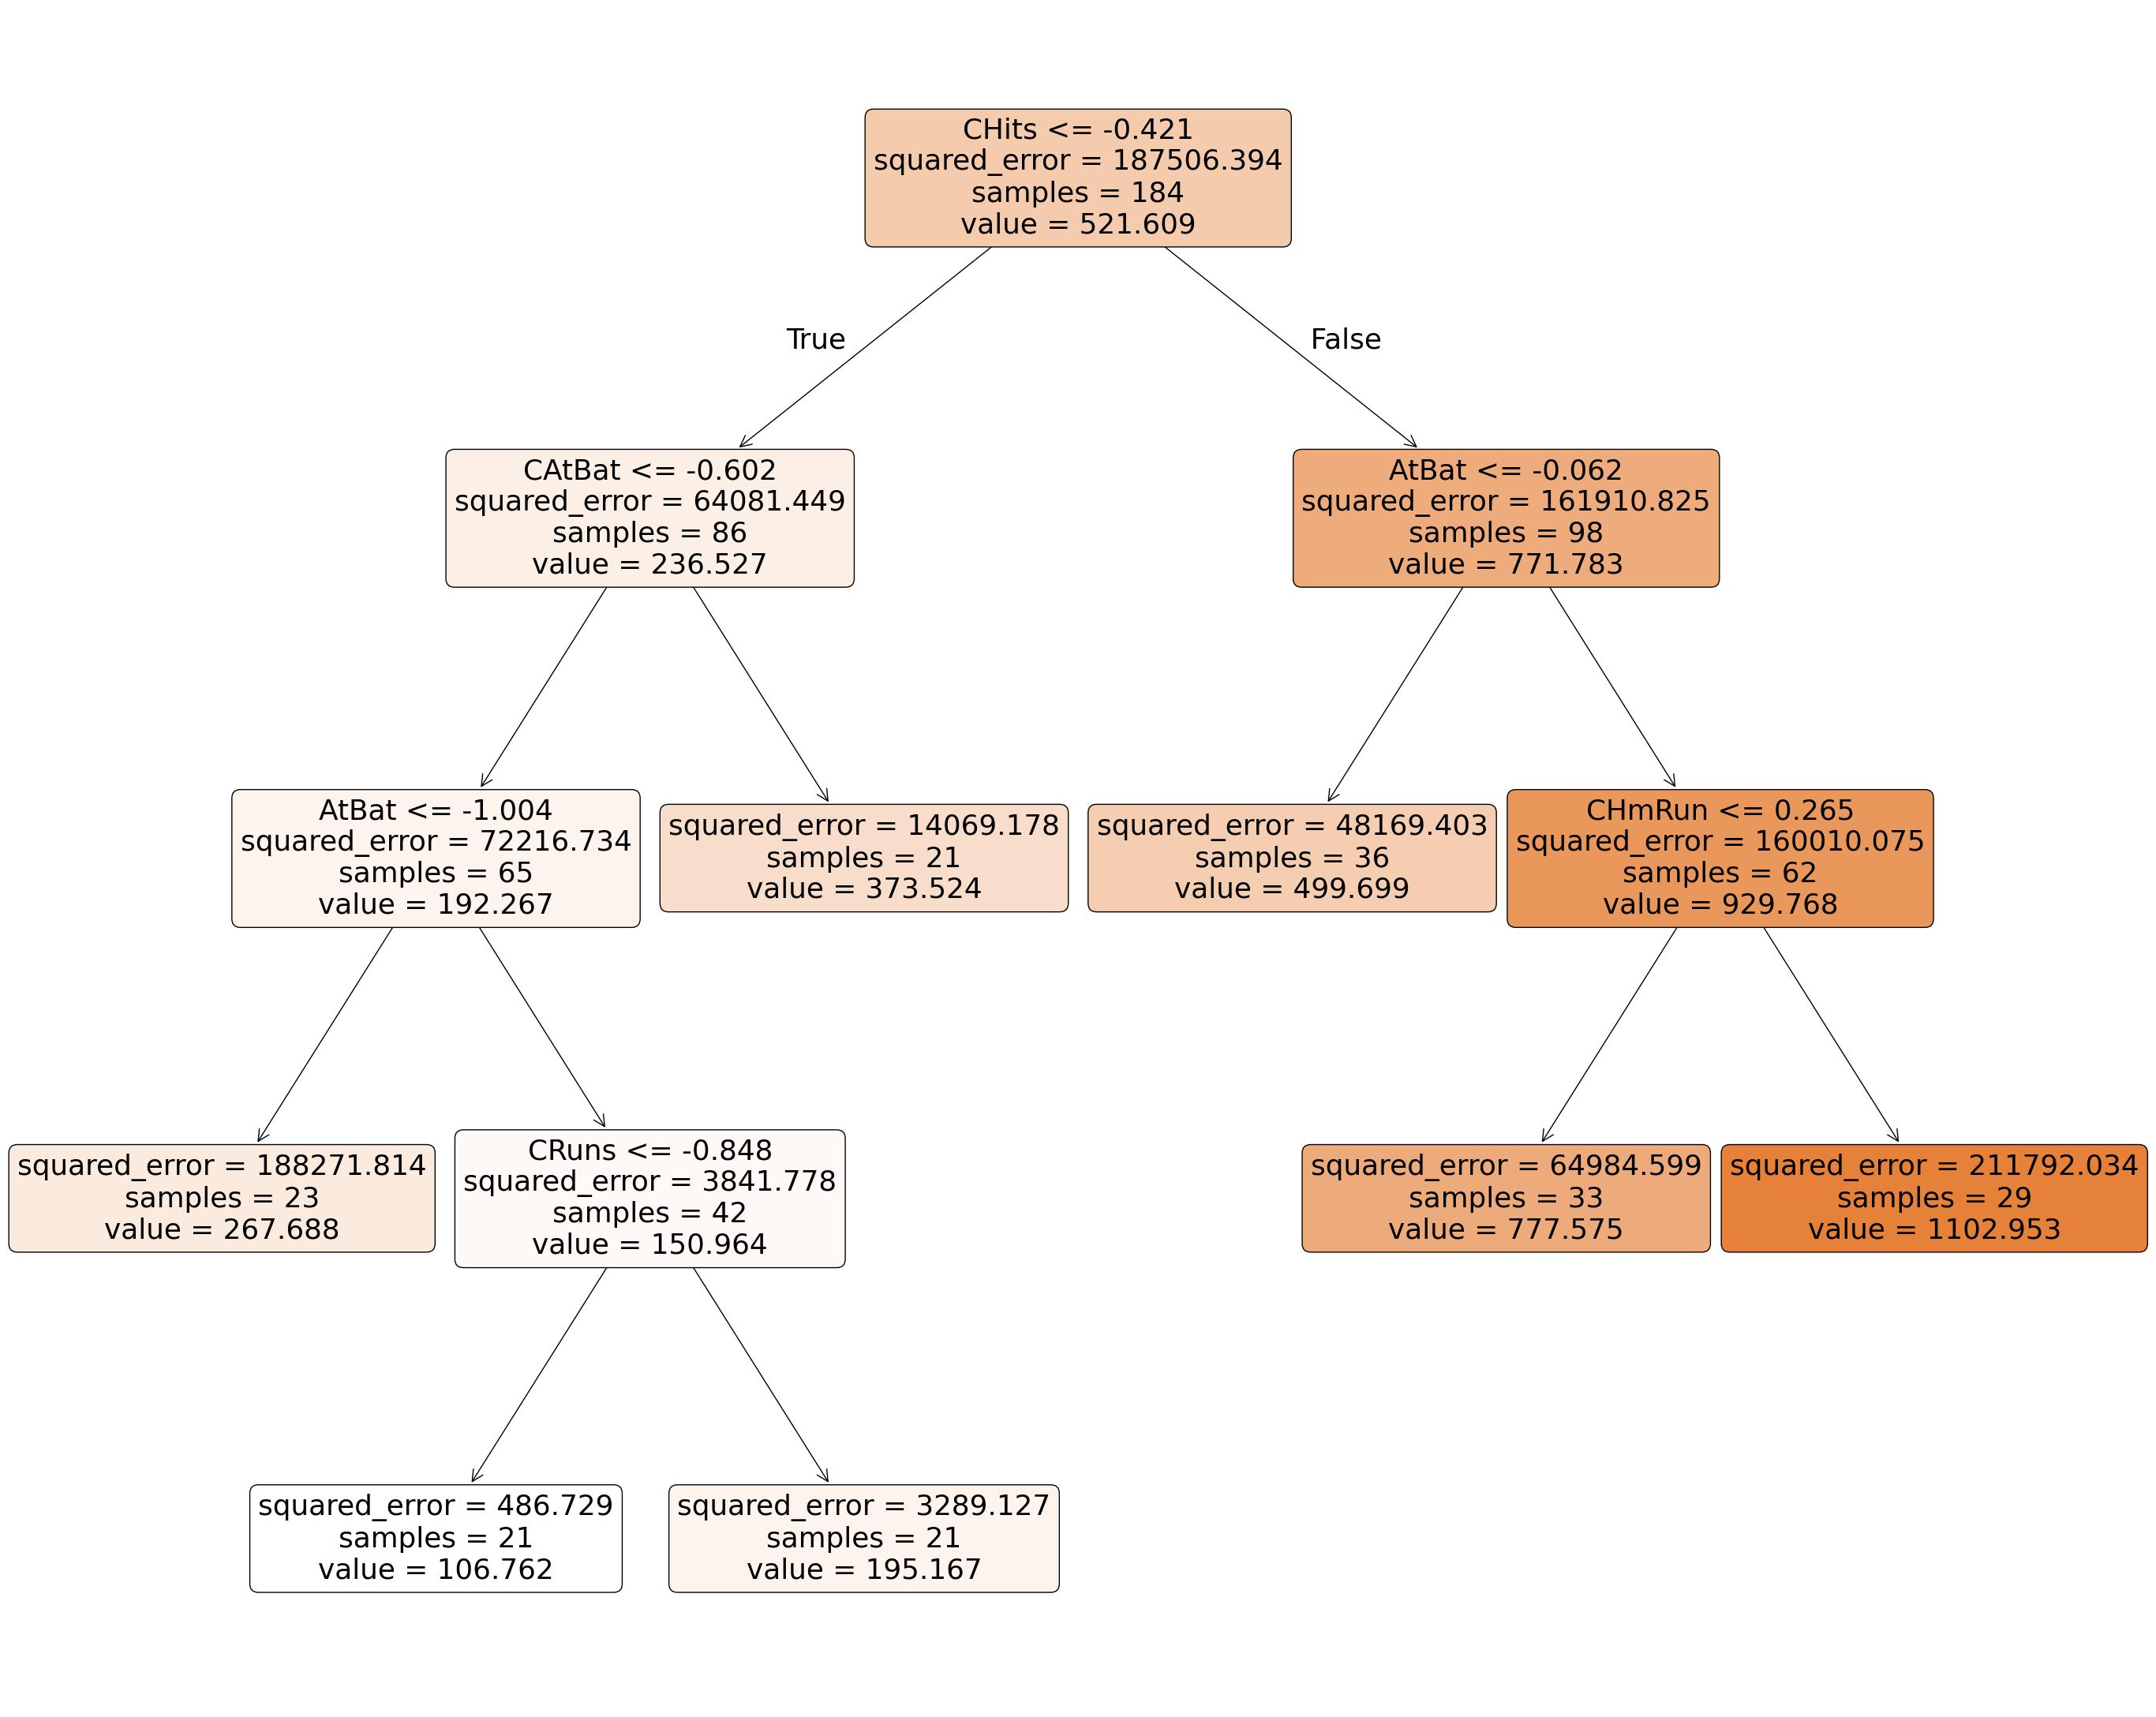

In [57]:
# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(best_tree,
                  feature_names = list(X_train),
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("Hitters_best_tree.pdf",bbox_inches='tight')

In [58]:
#Tarea para la casa: probar hacer la prediccion para la variable log(salarios) -> chequear si es similar al libro


La siguiente parte vamos a ver cómo mejorar notablemente la performance de con los **Métodos de Ensamble**.

## Tutorial 6 - Parte 2. Bagging & Random Forest

**Objetivo:** 
Que se familiaricen con los ensambles en la teoría y en la práctica con scikitlearn

### Temario:
- Bootstrapping: ilustración con la media muestral $\bar{X}$
- Ensemble Learning
- Bagging
- Random Forest

*Notebook basado en el oficial de la cátedra (`C08_UBA_Ensamble1.ipynb`).*


In [59]:
import pandas as pd 
import numpy as np 
import seaborn as sns
from ISLP import load_data
import matplotlib.pyplot as plt

from sklearn import metrics 
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split 
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor 

### 1. Técnica de Remuestreo Muestreo: Bootstrap

En **estadística**, dicho remuestreo con reposición genera que se cumpla el supuesto de *i.i.d.* para estimar un intervalo de confianza al nivel de significancia $\alpha$ y hacer test de hipótesis. Supongamos que tenemos una muestra de "n" valores (x) y nos gustaría obtener una estimación de la media de la muestra. Para hacerlo con *Bootstrapping* el procedimiento sería:

1. Crear muchas submuestras aleatorias (por ejemplo, 1000) del conjunto de datos con reemplazo (lo que significa que podemos seleccionar el mismo valor varias veces).
2. Calcular la media de cada submuestra. 
3. Calcular el promedio de todas nuestras medias recopiladas, y utilizar la fórmula de la varianza muestral para construir un intervalo de confianza.

En **Machine Learning**, el método *bootstrap* se refiere al muestreo aleatorio con reemplazo y se denomina *remuestreo*. La técnica permite que el modelo o algoritmo obtenga una mejor comprensión de los diversos sesgos, variaciones y características que existen en la muestra. Tomar una muestra de los datos permite que la nueva muestra contenga características diferentes de las que podría haber contenido en su totalidad. 


#### Ejercicio práctico con la base de Boston Housing 

En este ejemplo vamos a usar la base de datos de [Boston](https://islp.readthedocs.io/en/latest/datasets/Boston.html) con datos de casas.

**Variables in database:**
- CRIM:     per capita crime rate by town
- ZN:    proportion of residential land zoned for lots over 25,000 sq.ft.
- INDUS:   proportion of non-retail business acres per town
- CHAS:  Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
- NOX: nitric oxides concentration (parts per 10 million)
- RM: average number of rooms per dwelling
- AGE:      proportion of owner-occupied units built prior to 1940
- DIS:      weighted distances to five Boston employment centres
- RAD:      index of accessibility to radial highways
- TAX:      full-value property-tax rate per USD10,000
- PTRATIO:  pupil-teacher ratio by town
- LSTAT:    % lower status of the population
- MEDV:     Median value of owner-occupied homes in USD1000's

In [60]:
dataset = load_data('Boston')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  lstat    506 non-null    float64
 12  medv     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [61]:
print(dataset.shape)
dataset.head() 

(506, 13)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [62]:
dataset.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crim,506.0,3.61,8.60,0.01,0.08,0.26,3.68,88.98
zn,506.0,11.36,23.32,0.00,0.00,0.00,12.50,100.00
indus,506.0,11.14,6.86,0.46,5.19,9.69,18.10,27.74
chas,506.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
nox,506.0,0.55,0.12,0.38,0.45,0.54,0.62,0.87
rm,506.0,6.28,0.70,3.56,5.89,6.21,6.62,8.78
age,506.0,68.57,28.15,2.90,45.02,77.50,94.07,100.00
dis,506.0,3.80,2.11,1.13,2.10,3.21,5.19,12.13
rad,506.0,9.55,8.71,1.00,4.00,5.00,24.00,24.00
tax,506.0,408.24,168.54,187.00,279.00,330.00,666.00,711.00


In [63]:
# Vamos a predecir medv: median value of owner-occupied homes in $1000s.
y = dataset['medv']
print(y)
dataset['medv'].describe().round(2)

print("Para el total de la muestra la media es: ", round(y.mean(), 2), "\ny la desviación estandar es: ", round(np.std(y), 2))


0      24.0
1      21.6
2      34.7
3      33.4
4      36.2
       ... 
501    22.4
502    20.6
503    23.9
504    22.0
505    11.9
Name: medv, Length: 506, dtype: float64
Para el total de la muestra la media es:  22.53 
y la desviación estandar es:  9.19


In [64]:
all_means = []
all_std = []

#Boostrapping de promedios y desvío estandard 
for sample in range(0,100): # B muestras bootstrappeadas
    boot = resample(y, replace = True, n_samples = 100) #tenemos 506 obs pero hacemos muestras de 100 (una submuestra<n)
    mean = boot.mean() # calculamos la media en la muestra b-émesima 
    std = np.std(boot) # calculamos el desvío standar en la muestra b-émesima 
    all_means.append(mean)
    all_std.append(std)


In [65]:
print("\nPara las submuestras la media es: ", round(np.mean(all_means), 2), "\n la desviación estandar de las medias es: ", round(np.std(all_means), 2), "\n\ny el promedio de las desviaciones estándar de las submuestras es: ", round(np.mean(all_std), 2))


Para las submuestras la media es:  22.61 
 la desviación estandar de las medias es:  0.91 

y el promedio de las desviaciones estándar de las submuestras es:  9.16


Alcanzamos una media muy similar pero una desviación estándar mucho menor.
Esta idea de Boostrap la vamos a usar en el ejemplo a continuación para predecir los precios de las viviendas.


### Motivación: ¿Por qué usar métodos de Ensamble?
Vimos el método de Árboles para clasificación o regresión, que se basaba en partir el espacio de atributos en 'rectángulos' o regiones.

Si bien este método tenía algunas ventajas como que es fácil de ilustrar y explicar, suele tener menos capacidad predictiva que otros métodos y suele ser poco robusto.

Entonces...

#### ¿Qué son los métodos de Ensamble?
Son métodos que tienen como objetivo mejorar el rendimiento predictivo de un modelo dado. El principio general de los métodos de ensamble es construir una combinación lineal de otros modelos, en lugar de utilizar un único modelo que por si solo tenga bajo poder predictivo (a estos se le llama *weak learners*). Por ejemplo, hay ensambles que combinan varios árboles de decisión para producir una mejor predicción que un solo árbol de decisión. El ensemble ayuda a reducir la varianza y/o el sesgo.

#### [Ensambles](https://scikit-learn.org/stable/modules/ensemble.html) 
El objetivo de los algoritmos de *ensemble* es combinar las predicciones de varios estimadores base construidos con un algoritmo de aprendizaje dado para mejorar la generalización / robustez sobre un solo estimador.

##### Hay dos familias de métodos de ensamble que generalmente se distinguen:

**Métodos de promedio:** el principio impulsor es construir varios estimadores de forma independiente y luego promediar sus predicciones. En promedio, el estimador combinado suele ser mejor que cualquiera de los estimadores de base única porque su varianza es menor y ayuda a evitar el sobreajuste. **Ejemplos:** *Bootstrap Aggregation (Bagging)*, *Random Forest*.

**Métodos de Boosting:** los estimadores base se construyen secuencialmente y se intenta reducir el sesgo del estimador combinado. Esto puede causar sobreajuste. Para evitarlo, el ajuste de parámetros juega un papel importante en la mejora de estos algoritmos. La motivación es combinar varios modelos débiles para producir un modelo más robusto. 
**Ejemplos:** *AdaBoost*, *Gradient Tree Boosting*, *GBM*, *XGBM*.

#### Ventajas del ensamble
- Los ensambles mejoran la precisión del modelo y funcionan en la mayoría de los casos.
- Los ensambles hacen que el modelo sea más robusto y estable, lo que garantiza un rendimiento decente en los casos de prueba en la mayoría de los escenarios.
- Los ensambles se pueden utilizar para capturar relaciones lineales, simples y complejas, así como no lineales en los datos. Esto se puede hacer usando dos modelos diferentes y formando un ensamble con ellos.

#### Desventajas del ensamble
- Los ensambles reducen la interpretabilidad del modelo y hacen que sea difícil comunicar los resultados.
- Llevan más tiempo y, por lo tanto, podría no ser la mejor idea para aplicaciones en tiempo real.
- La selección de modelos para crear un ensamble es un arte realmente difícil de dominar.

#### Técnicas básicas de ensambles
- *Majority Vote*: es una de las formas más simples de combinar predicciones de múltiples algoritmos de aprendizaje automático. Cada modelo base hace una predicción y vota para cada muestra. Para cada una de las observaciones, la clase con más votos se considera la clase predictiva final. Se utiliza principalmente para problemas de clasificación.
- *Promedio*: el promedio generalmente se usa para problemas de regresión (pero se puede utilizar al estimar las probabilidades en las tareas de clasificación). Las predicciones se extraen de varios modelos y se utiliza un promedio de las predicciones para hacer la predicción final.
- *Promedio ponderado*: al igual que el promedio, el promedio ponderado también se usa para tareas de regresión. Alternativamente, se puede utilizar al estimar probabilidades en problemas de clasificación. A los modelos de base se les asignan diferentes ponderaciones, que representan la importancia de cada modelo en la predicción.


### Preparación de datos para entrenamiento

En primer lugar, dividiremos los datos en conjuntos de "atributos" (X) y "etiquetas" (y). El resultado luego se dividirá en conjuntos de entrenamiento y prueba.

En segundo lugar, notarán que los valores de la base de datos no están muy bien escalados. El campo TAX tiene valores en el rango de las centenas, mientras que RAD por ejemplo tiene valores en el rango de unidades. Usaremos la clase StandardScaler de Scikit-Learn para hacerlo.

In [66]:
# Definimos la Matriz `X` y vector `y` a predecir
X = dataset.iloc[:, 0:12]
y = dataset.iloc[:, 12].values
X.head()


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33


In [67]:
X.shape

(506, 12)

In [68]:
# Enfoque de validacion
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [69]:
# Escalamos los predictores
sc = StandardScaler() 
X_train = sc.fit_transform(X_train) 
X_test = sc.transform(X_test)

In [70]:
# Chequeamos la transformación de nuestros predictores en entrenamiento y testeo
print("X_train:")
print("Media:", X_train.mean(axis=0).round(2))
print("Desviación estándar:", X_train.std(axis=0).round(2))
print("Obs x cols:", X_train.shape)

print("\nX_test:")
print("Media:", X_test.mean(axis=0).round(2))
print("Desviación estándar:", X_test.std(axis=0).round(2))
print("Obs x cols:", X_test.shape)

X_train:
Media: [-0.  0. -0.  0. -0.  0. -0. -0. -0.  0.  0.  0.]
Desviación estándar: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Obs x cols: (404, 12)

X_test:
Media: [ 0.14 -0.09  0.01 -0.   -0.05 -0.12 -0.08  0.06  0.08  0.16 -0.02 -0.04]
Desviación estándar: [1.25 0.93 0.9  1.   1.03 1.05 1.01 1.06 1.02 0.92 0.93 0.89]
Obs x cols: (102, 12)


### 0. CART: repaso!
Para utilizar Arboles de regresión y clasificación con Scikit-Learn tenemos [DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) y [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html?highlight=decisiontreeclassifier#sklearn.tree.DecisionTreeClassifier). En este caso usaremos DecisionTreeRegressor dado que queremos predecir el valor de las viviendas.

In [71]:
cv = KFold(n_splits=10, shuffle = True, random_state = 10)            
mses = list()
max_attributes = X_train.shape[1]
depth_range = range(1, max_attributes + 1)

for depth in depth_range:
    fold_mse = []
    tree_model = DecisionTreeRegressor(max_depth = depth, random_state = 10) # Aqui ajusta los hiperparametros a la grilla 
    
    for train_index, valida_index in cv.split(X_train):   
        x_train, x_valida = X_train[train_index], X_train[valida_index] 
        y_train, y_valida = Y_train[train_index], Y_train[valida_index] 
    
        model = tree_model.fit(x_train, y_train) # estima el modelo en el fold k-ésimo
        y_pred = model.predict(x_valida)
        mse = mean_squared_error(y_pred, y_valida)
        fold_mse.append(mse)
        
    avg = sum(fold_mse)/len(fold_mse)
    mses.append(avg)
    
df = pd.DataFrame({"Max Depth": depth_range, "Average MSE": mses})
df = df[["Max Depth", "Average MSE"]].round(2)
print(df.to_string(index=False))


 Max Depth  Average MSE
         1        54.55
         2        29.36
         3        19.69
         4        16.00
         5        16.36
         6        14.70
         7        16.87
         8        12.95
         9        14.54
        10        14.28
        11        15.69
        12        13.41


In [72]:
# Loop para seleccionar max_depth por cross-validation
min_mse = np.inf
depth = None
for index, row in df.iterrows():
    if row['Average MSE'] < min_mse:
        min_mse = row['Average MSE']
        depth_cv = row['Max Depth']
print('El mínimo error es', round(min_mse, 2), 'y se da con nivel de profundidad', depth_cv)


El mínimo error es 12.95 y se da con nivel de profundidad 8.0


In [73]:
# Arbol de regresion con profundidad elegida por CV
tree_model_cv = DecisionTreeRegressor(max_depth = 8)
tree_model_cv.fit(X_train, Y_train) 
# y_pred = tree_model.predict(X_test)  # tree_model es el último árbol del loop de CV (max_depth=12), no el elegido
y_pred = tree_model_cv.predict(X_test)  # árbol con la profundidad elegida por CV

In [74]:
from sklearn.tree import  plot_tree

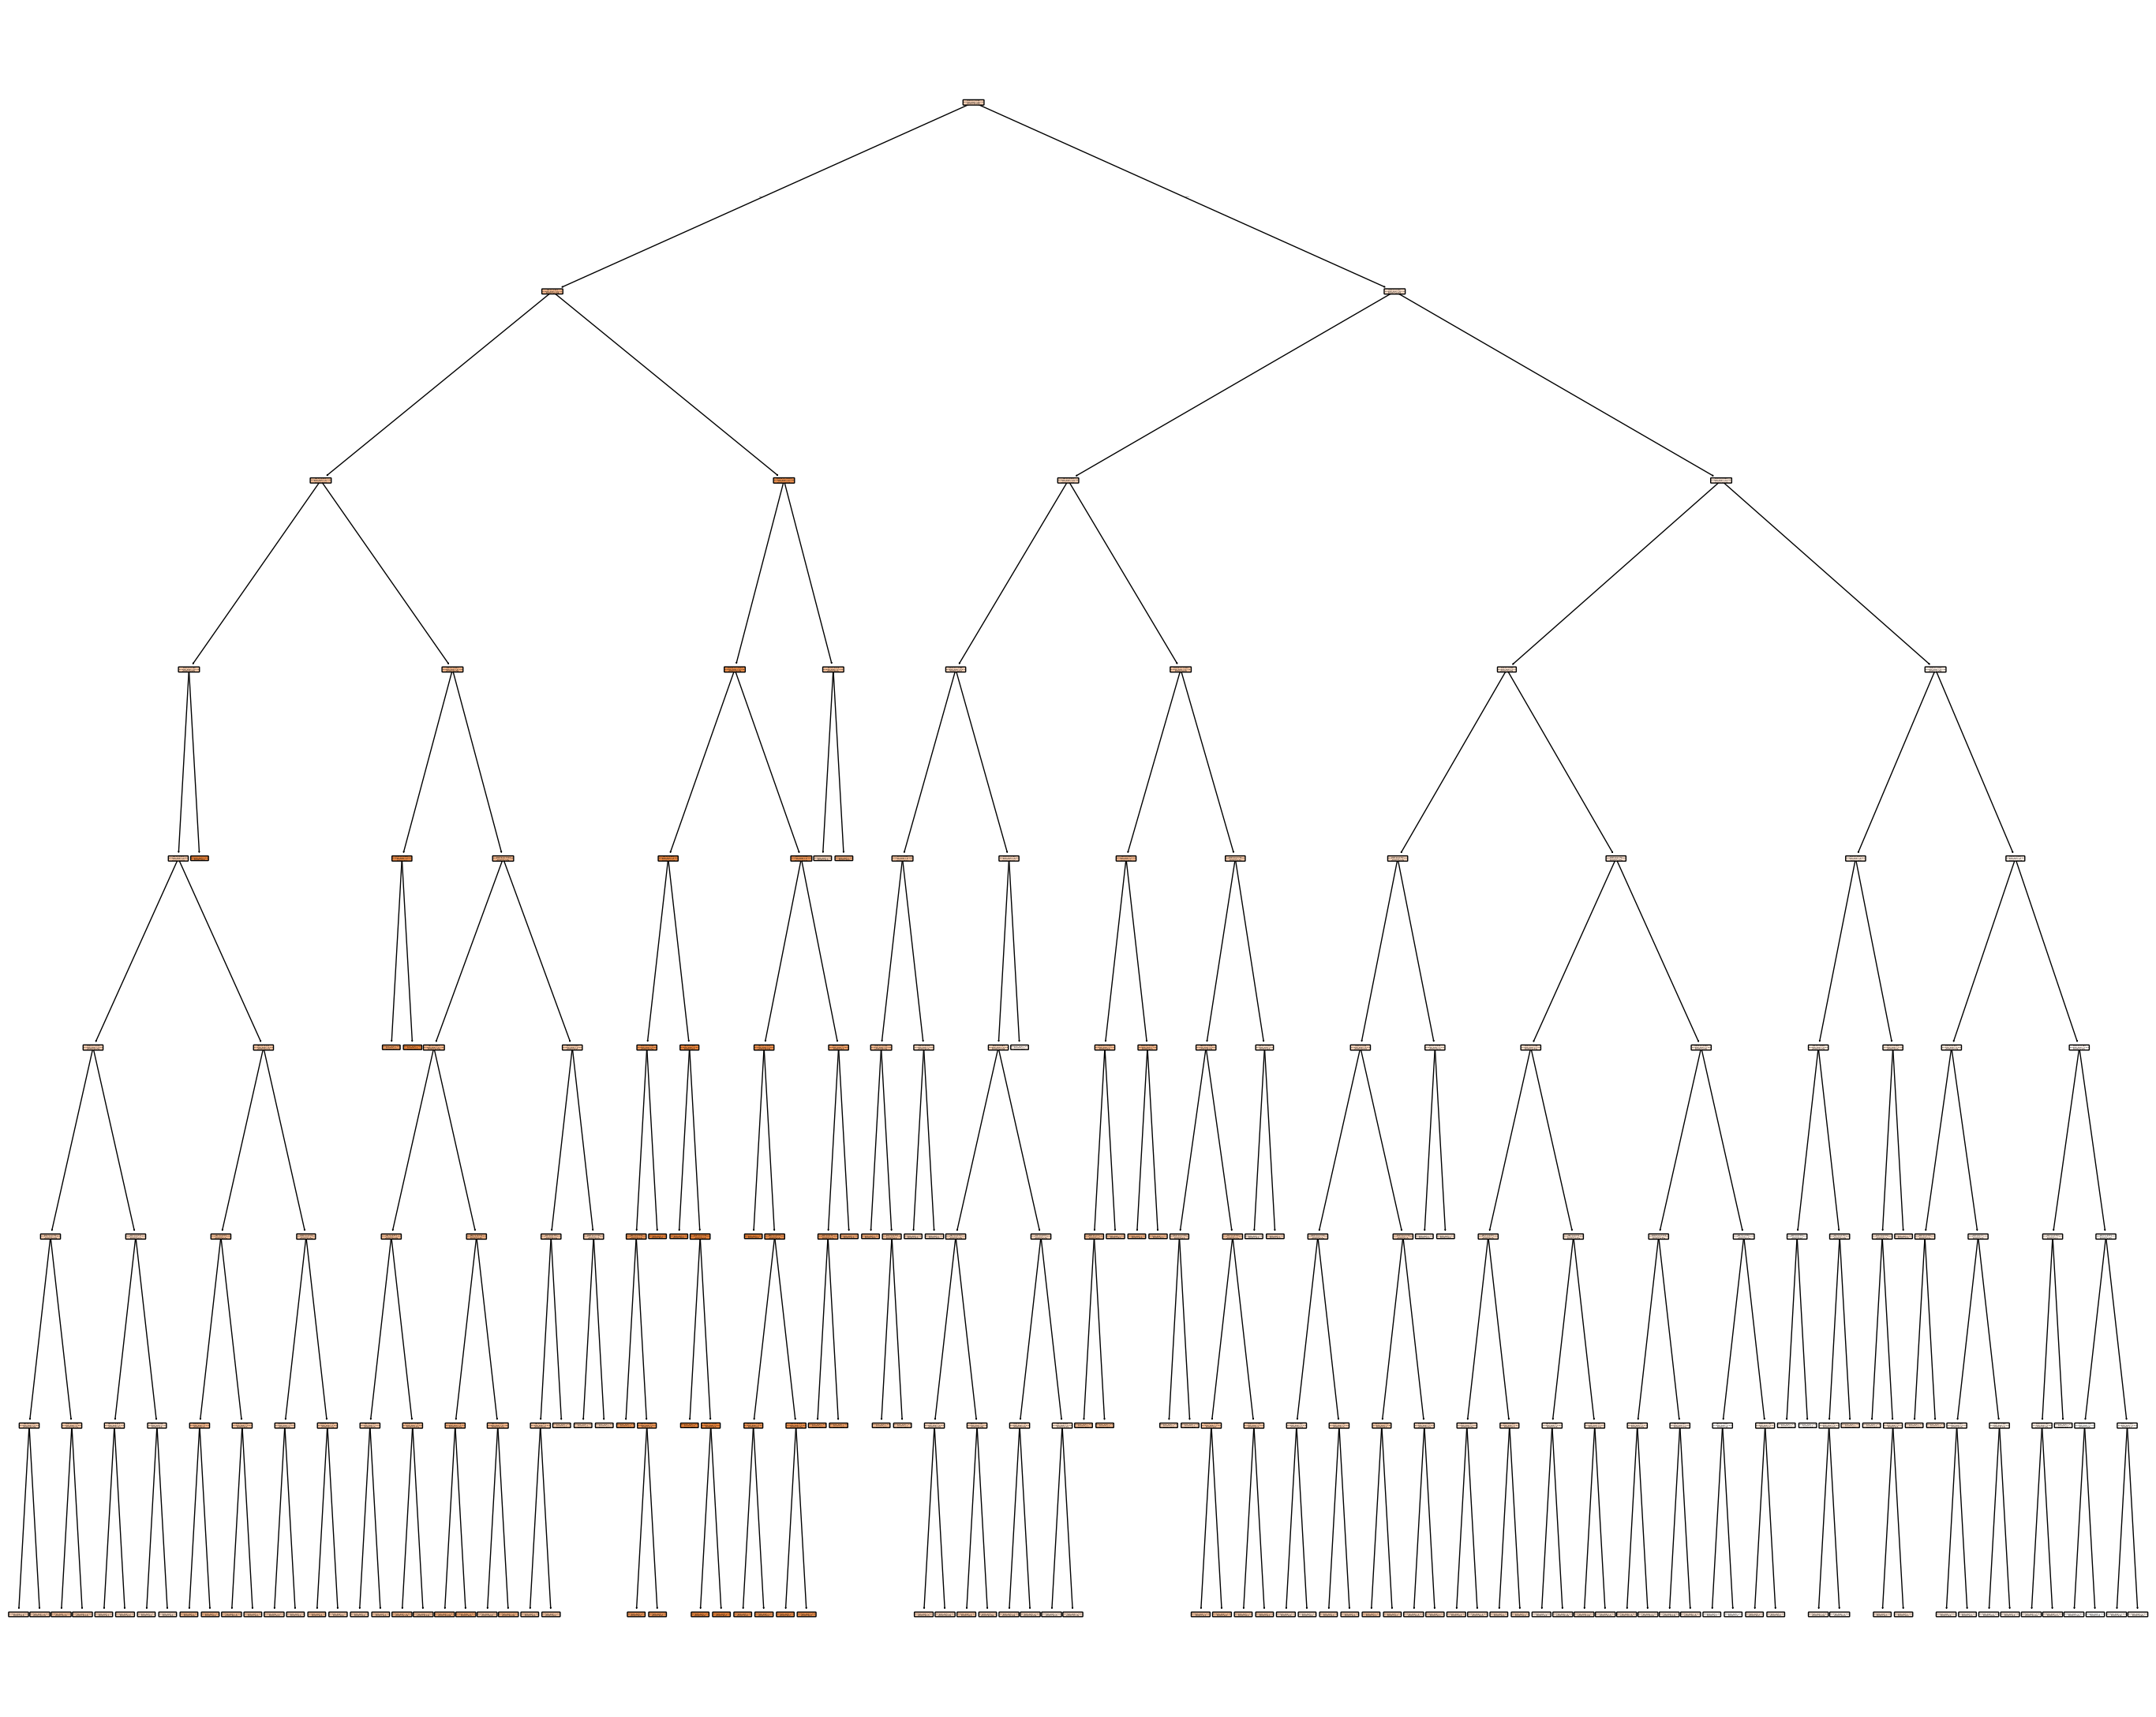

In [75]:
# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(tree_model_cv,
                  feature_names = list(X.columns),
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )

Hacemos lo mismo con `GridSearchCV`

In [76]:
tree_model = DecisionTreeRegressor(random_state=10)
depth_range = range(1, max_attributes + 1)
tree_para = {'max_depth':depth_range}
grid_search = GridSearchCV(tree_model, tree_para, cv=10, scoring='neg_median_absolute_error')
grid_search.fit(X_train, Y_train)

GridSearchCV(cv=10, estimator=DecisionTreeRegressor(random_state=10),
             param_grid={'max_depth': range(1, 13)},
             scoring='neg_median_absolute_error')

In [77]:
# Extraemos el mejor modelo
best_tree = grid_search.best_estimator_
y_pred = best_tree.predict(X_test)
best_tree

DecisionTreeRegressor(max_depth=9, random_state=10)

#### Evaluación del algoritmo
Evaluemos el desempeño del algoritmo observando el error cuadrático medio.

In [78]:
mse_cart = metrics.mean_squared_error(Y_test, y_pred)
print('MSE test:', mse_cart) 

MSE test: 28.613770457804826


#### Importancia de las variables en la predicción de CART

Un atributo de los arboles de decision es el calculo de la *importancia relativa de las variables*. Intuitivamente, se mide el nivel de impureza en cada nodo (en regresion con MSE, en clasificacion con Gini, como vimos en la clase anterior), y se compara **entre predictores** quién logra una mayor caída del nivel de impureza dentro del nodo (osea que las observaciones son mas parecidad en caracteristica y por lo tanto nuestro error de predicción menor).

Formalmente, la importancia de una característica se calcula como:
1. Para cada nodo $i$ en el árbol, calcula la reducción de la impureza $\Delta i$ cuando se divide el nodo utilizando el predictor $j$
2. Calcula la proporción de muestras $w_i$ que llegan al nodo $i$
3. La importancia del predictor $j$ se calcula como

$$
FeatureImportances_j= \frac{\Sigma (\Delta i \times w_i)}{\Sigma (\Delta i \times w_i)\text{sobre todos los nodos i}}
$$


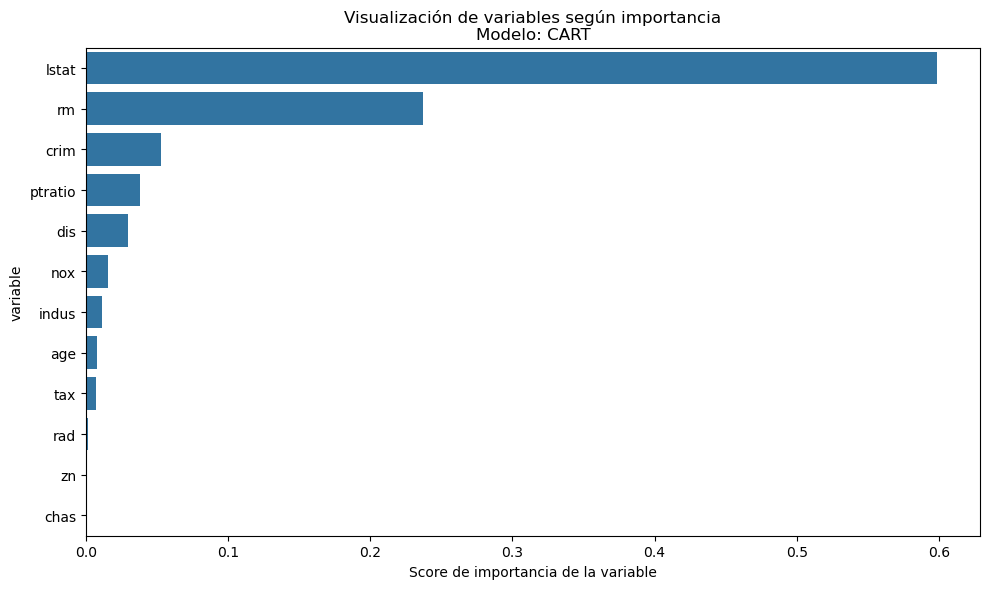

In [79]:
feature_imp = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Score de importancia de la variable')
plt.ylabel('variable')
plt.title("Visualización de variables según importancia\nModelo: CART")
plt.tight_layout()

## 1. Bagging (Bootstrap Aggregation)
Es un poderoso método de ensamble para evitar el sobreajuste. El concepto detrás del *bagging* es combinar las predicciones de varios modelos básicos para crear un resultado más preciso. *Bagging* es la aplicación del procedimiento Bootstrap a un algoritmo de aprendizaje automático de alta varianza, por ejemplo, los árboles de decisión. El rendimiento de los algoritmos de aprendizaje automático de alta varianza, como los árboles de decisión sin podar, se puede mejorar entrenando muchos árboles y tomando el promedio de sus predicciones. Los resultados suelen ser mejores que un solo árbol de decisiones.

Procedimiento:

0. Suponiendo que hay N observaciones y p características 
1. Se seleccionan B muestras de las observaciones al azar con reemplazo (Bootstrapping).
2. Se entrena el modelo en cada uno de los B datasets. 
3. Finalmente, la predicción se basa en la **agregación** de predicciones de todos los modelos (votación para los clasificadores o el promedio para las regresiones). Cada hipótesis tiene el mismo peso que todas las demás. 


Para utilizar Bagging con Scikit-Learn tenemos [BaggingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingRegressor.html#sklearn.ensemble.BaggingRegressor) y [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html#sklearn.ensemble.BaggingClassifier). En este caso usaremos BaggingRegressor dado que queremos predecir el valor de las viviendas (variable continua).

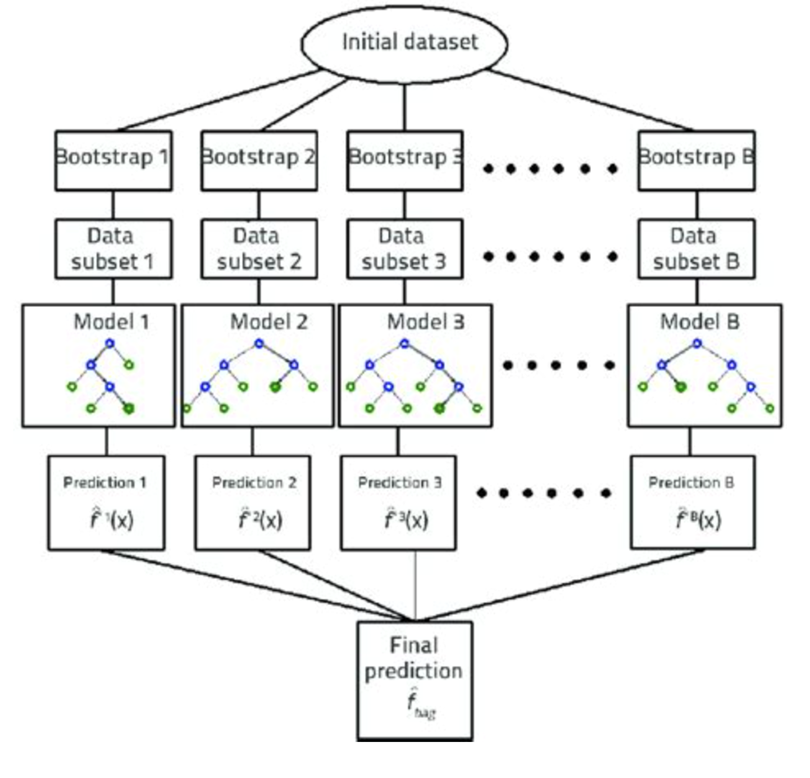

In [80]:
regressor = BaggingRegressor(n_estimators=25, max_samples=200, random_state=1) 
# estimator (Es None por default, y cuando eso ocurre el estimador es DecisionTreeRegressor.)
# n_estimators: cuántos modelos se corren/ cuantas muestras boostrappeadas
# max_samples: cuántas observaciones se consideran para cada modelo
# bootstrap: Si las muestras se obtienen con reemplazo (por default es True)
regressor.fit(X_train, Y_train) 
y_predB = regressor.predict(X_test)

In [81]:
mse_bagg = metrics.mean_squared_error(Y_test, y_predB)
print('MSE test (B=25):', mse_bagg) 

MSE test (B=25): 20.97551325490195


##### Probamos con distintas muestras boostrappeadas `n_estimators`

In [82]:
regressor2 = BaggingRegressor(n_estimators=100, max_samples=200, random_state=1) 

regressor2.fit(X_train, Y_train) 
y_predB2 = regressor2.predict(X_test)

In [83]:
mse_bagg2 = metrics.mean_squared_error(Y_test, y_predB2)
print('MSE test (B=100):', mse_bagg2) 

MSE test (B=100): 22.29408184313726


In [84]:
regressor3 = BaggingRegressor(n_estimators=10, max_samples=200, random_state=1) 

regressor3.fit(X_train, Y_train) 
y_predB3 = regressor3.predict(X_test)

mse_bagg3 = metrics.mean_squared_error(Y_test, y_predB3)


In [85]:
print('MSE test (CART, B=1):', mse_cart) 
print('MSE test (B=10):', mse_bagg3) 
print('MSE test (B=25):', mse_bagg) 
print('MSE test (B=100):', mse_bagg2) 

MSE test (CART, B=1): 28.613770457804826
MSE test (B=10): 26.742589215686266
MSE test (B=25): 20.97551325490195
MSE test (B=100): 22.29408184313726


#### Encontramos el parametro de tunning por Cross-Validation


In [86]:
# Set simple de Bagging
bagg_model = BaggingRegressor(max_samples=200, random_state=1) 
# Cantidad de muestras boostrapeadas (y por lo tanto arboles estimados que se promedian)
Bsamples = [1, 5, 10, 100, 200, 500]
bagg_para = {'n_estimators':Bsamples}

# Estimacion para la grilla de parametro de tunning
grid_search = GridSearchCV(bagg_model, bagg_para, cv=10, scoring='neg_median_absolute_error')
grid_search.fit(X_train, Y_train)

GridSearchCV(cv=10, estimator=BaggingRegressor(max_samples=200, random_state=1),
             param_grid={'n_estimators': [1, 5, 10, 100, 200, 500]},
             scoring='neg_median_absolute_error')

In [87]:
# Extraemos el mejor modelo
best_bagg = grid_search.best_estimator_
y_pred = best_bagg.predict(X_test)
best_bagg

BaggingRegressor(max_samples=200, n_estimators=200, random_state=1)

#### Evaluación de Bagging con `B` elegido por cross-validation

In [88]:
mse_bagg = metrics.mean_squared_error(Y_test, y_pred)
print('MSE test:', mse_bagg) 

MSE test: 22.564375600490184


## 2. Random Forest Regressor
El Random Forest, como Bagging, construye árboles de decisión con muestras obtenidas por bootstrapping y promedia los resultados de cada árbol para obtener la predicción final. 
Por qué "random"?
 - Muestreo aleatorio de datos de entrenamiento al construir árboles
 - Al dividir nodos, considera subconjuntos aleatorios de características para hacer la división (en lugar todos los predictores disponibles).
 
Así, los árboles obtenidos en el proceso estarán menos correlacionados y al promediarlos, la reducción en la varianza será mayor que la que se obtendría al promediar árboles más correlacionados.

Para utilizar Random Forest con Scikit-Learn tenemos [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html?highlight=randomforestregressor#sklearn.ensemble.RandomForestRegressor) y [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html?highlight=randomforestclassifier#sklearn.ensemble.RandomForestClassifier). En este caso usaremos RandomForestRegressor dado que queremos predecir el valor de las viviendas. 

In [89]:
regressor = RandomForestRegressor(n_estimators=200, max_samples=200, max_features=1, random_state=1) 
# max_features: es el subconjunto de predictores m (en slides) a considerar. El default es  max_features=1.0 (todos los predictores, m=p)
regressor.fit(X_train, Y_train) 
y_pred = regressor.predict(X_test)
mse_test_rf1 = metrics.mean_squared_error(Y_test, y_pred)
print('MSE testeo (m=1):', mse_test_rf1)

MSE testeo (m=1): 32.74085607352938


##### Probamos con distinto numero de predictores disponibles `max_features` 
($m$ en las slides de clase)

In [90]:
regressor2 = RandomForestRegressor(n_estimators=200, max_samples=200, max_features=5, random_state=1) 


regressor2.fit(X_train, Y_train) 
y_pred2 = regressor2.predict(X_test)
mse_test_rf2 = metrics.mean_squared_error(Y_test, y_pred2)
print('MSE testeo (m=5):', mse_test_rf2)

MSE testeo (m=5): 26.298276053921548


Recordemos que en caso de regresion, el *numero sugerido* es $m=\sqrt{p}$ con $p$ numero de predictores

In [91]:
import math

num_columnas = X_train.shape[1]
m_sugerido = math.sqrt(num_columnas)
print(round(m_sugerido,0))

3.0


In [92]:
regressor3 = RandomForestRegressor(n_estimators=200, max_samples=200, max_features=3, random_state=1) 


regressor3.fit(X_train, Y_train) 
y_pred3 = regressor3.predict(X_test)
mse_test_rf3 = metrics.mean_squared_error(Y_test, y_pred3)


In [93]:
print('MSE testeo (m=1):', mse_test_rf1)
print('MSE testeo (m=3, sugerido):', mse_test_rf3)
print('MSE testeo (m=5):', mse_test_rf2)

MSE testeo (m=1): 32.74085607352938
MSE testeo (m=3, sugerido): 27.776605061274473
MSE testeo (m=5): 26.298276053921548


#### Encontramos el parametro de tunning por Cross-Validation¶

In [94]:
# Set simple de Ranfom Forest
rf_model = RandomForestRegressor(max_samples=200, random_state=1) 

# Cantidad de predictures posibles a usar 
max_attributes = X_train.shape[1]
m_range = range(1, max_attributes + 1)
rf_para = {'max_features':m_range}

# Estimacion para la grilla de parametro de tunning
grid_search = GridSearchCV(rf_model, rf_para, cv=10, scoring='neg_median_absolute_error')
grid_search.fit(X_train, Y_train)

GridSearchCV(cv=10,
             estimator=RandomForestRegressor(max_samples=200, random_state=1),
             param_grid={'max_features': range(1, 13)},
             scoring='neg_median_absolute_error')

In [95]:
# Extraemos el mejor modelo
best_rf = grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
best_rf

RandomForestRegressor(max_features=11, max_samples=200, random_state=1)

#### Evaluacion de Random Forest con $m$ features elegido por cross-validation

In [96]:
mse_rf = metrics.mean_squared_error(Y_test, y_pred_rf)
print('MSE test:', mse_rf) 

MSE test: 21.450520343137267


#### Importancia relativa para Random Forest

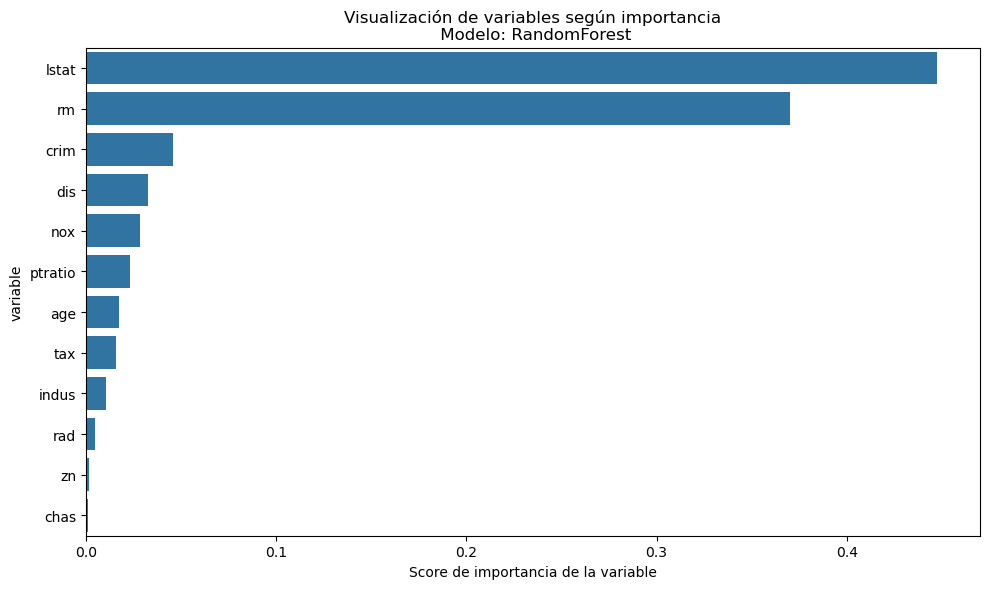

In [97]:
feature_imprf = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=feature_imprf, y=feature_imprf.index)
plt.xlabel('Score de importancia de la variable')
plt.ylabel('variable')
plt.title("Visualización de variables según importancia\n Modelo: RandomForest")
plt.tight_layout()

### Comparacion final entre modelos

In [98]:
print('MSE test CART:', mse_cart) 
print('MSE test Bagging:', mse_bagg) 
print('MSE test Random Forest:', mse_rf) 


MSE test CART: 28.613770457804826
MSE test Bagging: 22.564375600490184
MSE test Random Forest: 21.450520343137267


## Tutorial 6 - Parte 3. Boosting: AdaBoost

**Objetivo:**
Que se familiaricen con la familia de métodos de *boosting* en la teoría y en la práctica con `scikit-learn`.

### Temario:
- Repaso de ensambles (Bagging y Random Forest)
- AdaBoost
- Comparación final de modelos

*Notebook basado en el oficial de la cátedra (`C08_UBA_Ensamble2.ipynb`).*


### Motivación
Vimos el método de Árboles para clasificación o regresión, que se basaba en partir el espacio de atributos en 'rectángulos' o regiones.

Si bien este método tenía algunas ventajas como que es fácil de ilustrar y explicar, suele tener menos capacidad predictiva que otros métodos y suele ser poco robusto.

Entonces...

### ¿Qué son los métodos de Ensamble?
Son métodos que tienen como objetivo mejorar el rendimiento predictivo de un modelo dado. El principio general de los métodos de ensamble es construir una combinación lineal de otros modelos, en lugar de utilizar un único modelo que por si solo tenga bajo poder predictivo (a estos se le llama *weak learners*). Por ejemplo, hay ensambles que combinan varios árboles de decisión para producir una mejor predicción que un solo árbol de decisión. El ensemble ayuda a reducir la varianza y/o el sesgo.

### [Ensambles](https://scikit-learn.org/stable/modules/ensemble.html) 
El objetivo de los algoritmos de *ensemble* es combinar las predicciones de varios estimadores base construidos con un algoritmo de aprendizaje dado para mejorar la generalización / robustez sobre un solo estimador.

#### Hay dos familias de métodos de ensamble que generalmente se distinguen:

**Métodos de promedio:** el principio impulsor es construir varios estimadores de forma independiente y luego promediar sus predicciones. En promedio, el estimador combinado suele ser mejor que cualquiera de los estimadores de base única porque su varianza es menor y ayuda a evitar el sobreajuste. **Ejemplos:** *Bootstrap Aggregation (Bagging)*, *Random Forest*.

**Métodos de Boosting:** los estimadores base se construyen secuencialmente y se intenta reducir el sesgo del estimador combinado. Esto puede causar sobreajuste. Para evitarlo, el ajuste de parámetros juega un papel importante en la mejora de estos algoritmos. La motivación es combinar varios modelos débiles para producir un modelo más robusto. 
**Ejemplos:** *AdaBoost*, *Gradient Tree Boosting*, *GBM*, *XGBM*.

#### Ventajas del ensamble
- Los ensambles mejoran la precisión del modelo y funcionan en la mayoría de los casos.
- Los ensambles hacen que el modelo sea más robusto y estable, lo que garantiza un rendimiento decente en los casos de prueba en la mayoría de los escenarios.
- Los ensambles se pueden utilizar para capturar relaciones lineales, simples y complejas, así como no lineales en los datos. Esto se puede hacer usando dos modelos diferentes y formando un ensamble con ellos.

#### Desventajas del ensamble
- Los ensambles reducen la interpretabilidad del modelo y hacen que sea difícil comunicar los resultados.
- Llevan más tiempo y, por lo tanto, podría no ser la mejor idea para aplicaciones en tiempo real.
- La selección de modelos para crear un ensamble es un arte realmente difícil de dominar.

#### Técnicas básicas de ensambles
- *Majority Vote*: es una de las formas más simples de combinar predicciones de múltiples algoritmos de aprendizaje automático. Cada modelo base hace una predicción y vota para cada muestra. Para cada una de las observaciones, la clase con más votos se considera la clase predictiva final. Se utiliza principalmente para problemas de clasificación.
- *Promedio*: el promedio generalmente se usa para problemas de regresión (pero se puede utilizar al estimar las probabilidades en las tareas de clasificación). Las predicciones se extraen de varios modelos y se utiliza un promedio de las predicciones para hacer la predicción final.
- *Promedio ponderado*: al igual que el promedio, el promedio ponderado también se usa para tareas de regresión. Alternativamente, se puede utilizar al estimar probabilidades en problemas de clasificación. A los modelos de base se les asignan diferentes ponderaciones, que representan la importancia de cada modelo en la predicción.


In [99]:
import pandas as pd 
import numpy as np 
import seaborn as sns
from ISLP import load_data
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error

from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split 
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor 


### Continuamos con la base de Boston para predecir precio de casas 

En este ejemplo vamos a usar la base de datos de [Boston](https://islp.readthedocs.io/en/latest/datasets/Boston.html) con datos de casas.

**Variables in database:**
- CRIM:     per capita crime rate by town
- ZN:    proportion of residential land zoned for lots over 25,000 sq.ft.
- INDUS:   proportion of non-retail business acres per town
- CHAS:  Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
- NOX: nitric oxides concentration (parts per 10 million)
- RM: average number of rooms per dwelling
- AGE:      proportion of owner-occupied units built prior to 1940
- DIS:      weighted distances to five Boston employment centres
- RAD:      index of accessibility to radial highways
- TAX:      full-value property-tax rate per USD10,000
- PTRATIO:  pupil-teacher ratio by town
- LSTAT:    % lower status of the population
- MEDV:     Median value of owner-occupied homes in USD1000's

In [100]:
dataset = load_data('Boston')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  lstat    506 non-null    float64
 12  medv     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [101]:
print(dataset.shape)
dataset.head() 

(506, 13)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [102]:
dataset.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crim,506.0,3.61,8.60,0.01,0.08,0.26,3.68,88.98
zn,506.0,11.36,23.32,0.00,0.00,0.00,12.50,100.00
indus,506.0,11.14,6.86,0.46,5.19,9.69,18.10,27.74
chas,506.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
nox,506.0,0.55,0.12,0.38,0.45,0.54,0.62,0.87
rm,506.0,6.28,0.70,3.56,5.89,6.21,6.62,8.78
age,506.0,68.57,28.15,2.90,45.02,77.50,94.07,100.00
dis,506.0,3.80,2.11,1.13,2.10,3.21,5.19,12.13
rad,506.0,9.55,8.71,1.00,4.00,5.00,24.00,24.00
tax,506.0,408.24,168.54,187.00,279.00,330.00,666.00,711.00


#### Preparación de datos para entrenamiento

En primer lugar, dividiremos los datos en conjuntos de "atributos" (X) y "etiquetas" (y). El resultado luego se dividirá en conjuntos de entrenamiento y prueba.

En segundo lugar, notarán que los valores de la base de datos no están muy bien escalados. El campo TAX tiene valores en el rango de las centenas, mientras que RAD por ejemplo tiene valores en el rango de unidades. Será mejor si escalamos los datos. Usaremos la clase StandardScaler de Scikit-Learn para hacerlo.

In [103]:
# Separamos en X e y
X = dataset.drop(['medv'], axis=1)
y = dataset['medv']

# Transformamos las X
sc = StandardScaler() 

# Estandarizamos las observaciones de entrenamiento
X_transformed = pd.DataFrame(sc.fit_transform(X),index=X.index, columns=X.columns)


In [104]:
X_transformed.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crim,506.0,-0.0,1.0,-0.42,-0.41,-0.39,0.01,9.93
zn,506.0,0.0,1.0,-0.49,-0.49,-0.49,0.05,3.80
indus,506.0,0.0,1.0,-1.56,-0.87,-0.21,1.02,2.42
chas,506.0,-0.0,1.0,-0.27,-0.27,-0.27,-0.27,3.67
nox,506.0,-0.0,1.0,-1.47,-0.91,-0.14,0.60,2.73
rm,506.0,-0.0,1.0,-3.88,-0.57,-0.11,0.48,3.56
age,506.0,-0.0,1.0,-2.34,-0.84,0.32,0.91,1.12
dis,506.0,-0.0,1.0,-1.27,-0.81,-0.28,0.66,3.96
rad,506.0,-0.0,1.0,-0.98,-0.64,-0.52,1.66,1.66
tax,506.0,0.0,1.0,-1.31,-0.77,-0.46,1.53,1.80


In [105]:
X_train, X_test, Y_train, Y_test = train_test_split(X_transformed, y, test_size=0.2, random_state=0)

In [106]:
X_train.head(5)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat
220,-0.378845,-0.487722,-0.720322,3.668398,-0.412006,0.949344,0.708548,-0.443682,-0.178120,-0.601276,-0.488039,-0.412540
71,-0.402042,-0.487722,-0.047680,-0.272599,-1.224009,-0.461069,-1.816253,0.709373,-0.637962,-0.613155,0.344213,-0.388711
240,-0.407333,0.799865,-0.905627,-0.272599,-1.094434,0.872412,-0.507624,1.207940,-0.408041,-0.642851,-0.857929,-0.178450
6,-0.410243,0.048772,-0.476654,-0.272599,-0.265154,-0.388411,-0.070229,0.839244,-0.523001,-0.577519,-1.505237,-0.031268
417,2.598274,-0.487722,1.015999,-0.272599,1.073787,-1.397069,0.729884,-1.020876,1.661245,1.530926,0.806576,1.960602


### Base de comparación para la predicción de precios
Vamos a hacer una estimación de precios por MCO y CART como medidas de base de comparación de MSE test de modelo lineal y no lineal

##### Modelo lineal

In [107]:
lineal = LinearRegression().fit(X_train, Y_train)

In [108]:
# El intercepto
intercepto = lineal.intercept_
print('\nIntercepto:', intercepto.round(2))

# La pendiente
pendiente = lineal.coef_
print('\nPendiente:', pendiente.round(2))


Intercepto: 22.5

Pendiente: [-1.03  1.06  0.    0.64 -1.98  2.49  0.03 -2.96  1.93 -1.87 -2.22 -3.77]


In [109]:
# Estima y predicho
y_mco = lineal.predict(X_test)

# MSE test
mse0 = mean_squared_error(Y_test, y_mco)
print('\nMSE test (MCO):',mse0)


MSE test (MCO): 34.395063464646675


#### Modelo No lineal: CART podado

In [110]:
# Set simple de Ranfom Forest
tree_model = DecisionTreeRegressor(random_state=1) 

# grilla de costo de penalidad
alpha_range = [0.0, 0.01, 0.1, 0.5, 0.75, 1.0]
tre_para = {'ccp_alpha':alpha_range}

# Estimacion para la grilla de parametro de tunning
grid_search = GridSearchCV(tree_model, tre_para, cv=5, scoring='neg_median_absolute_error')
grid_search.fit(X_train, Y_train)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=1),
             param_grid={'ccp_alpha': [0.0, 0.01, 0.1, 0.5, 0.75, 1.0]},
             scoring='neg_median_absolute_error')

In [111]:
# Extraemos el mejor modelo
best_tree = grid_search.best_estimator_
best_tree

DecisionTreeRegressor(ccp_alpha=0.1, random_state=1)

In [112]:
# Hacemos predicciones para evaluar el modelo
y_cart = best_tree.predict(X_test)

mse_cart = mean_squared_error(Y_test, y_cart)

print(f"Mejores parámetros para el árbol de regresión: {grid_search.best_params_}")
print(f"MSE test (CART a=0.1): {mse_cart:.2f}")

Mejores parámetros para el árbol de regresión: {'ccp_alpha': 0.1}
MSE test (CART a=0.1): 29.58


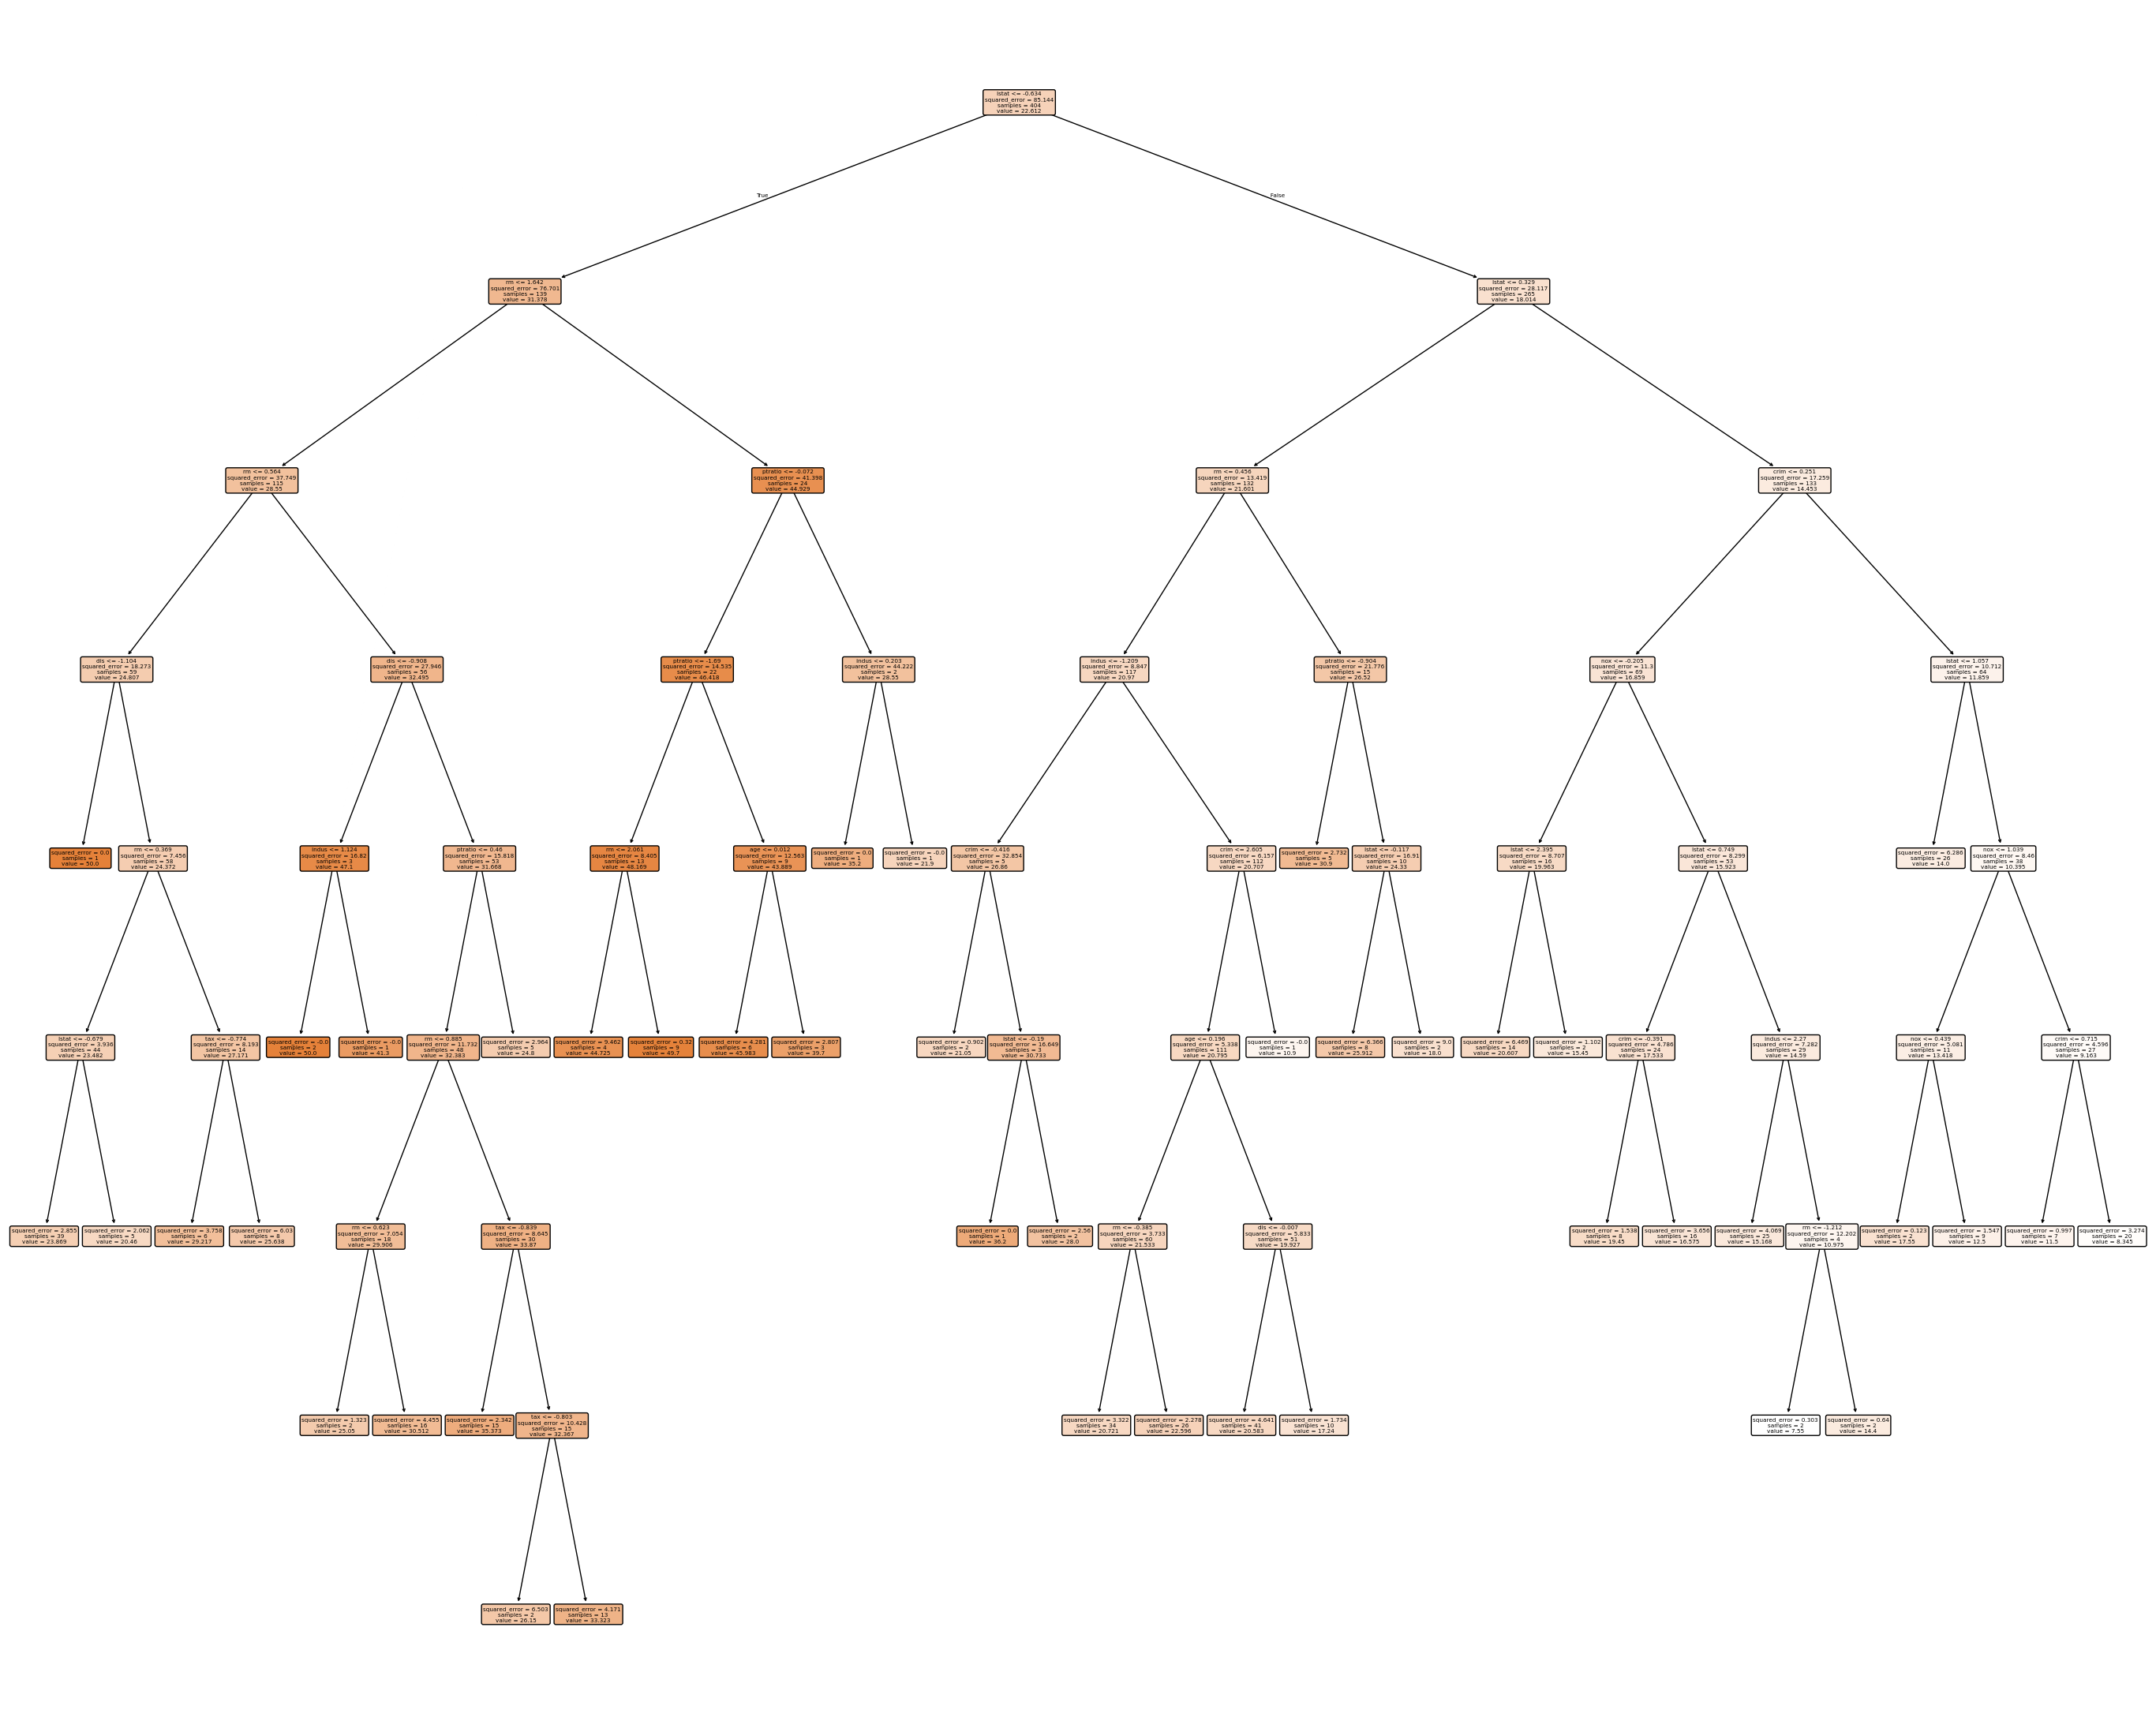

In [113]:
# Gráfico
fig = plt.figure(figsize=(35,28))
graph = plot_tree(best_tree,
                  feature_names = list(X_train),
                  rounded = True, 
                  filled = True   #colorear los nodos p/ indicar la clase mayoritaria (p/ clasif.)
                 )
fig.savefig("housing_cart.pdf",bbox_inches='tight')

##### Metodos de Ensamble 1: Bagging y Random Forest

In [114]:
# Set simple de Bagging
bagg_model = BaggingRegressor(max_samples=200, random_state=1) 
# Cantidad de muestras boostrapeadas (y por lo tanto arboles estimados que se promedian)
Bsamples = [1, 5, 10, 100, 200, 500]
bagg_para = {'n_estimators':Bsamples}

# Estimacion para la grilla de parametro de tunning
grid_search = GridSearchCV(bagg_model, bagg_para, cv=5, scoring='neg_median_absolute_error')
grid_search.fit(X_train, Y_train)

GridSearchCV(cv=5, estimator=BaggingRegressor(max_samples=200, random_state=1),
             param_grid={'n_estimators': [1, 5, 10, 100, 200, 500]},
             scoring='neg_median_absolute_error')

In [115]:
# Extraemos el mejor modelo
best_bagg = grid_search.best_estimator_
y_pred_bagg = best_bagg.predict(X_test)
best_bagg

# Evaluamos el modelo
mse_bagg = mean_squared_error(Y_test, y_pred_bagg)


In [116]:
# Set simple de Ranfom Forest
rf_model = RandomForestRegressor( random_state=1) 

# Definimos un rango de valores para los hiperparámetros
param_grid = {
    'n_estimators': [1, 5, 10, 100, 200, 500],
    'max_features': [2, 5, 10, 11],
}


# Estimacion para la grilla de parametro de tunning
grid_search = GridSearchCV(rf_model, param_grid, cv=5, scoring='neg_median_absolute_error')
grid_search.fit(X_train, Y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=1),
             param_grid={'max_features': [2, 5, 10, 11],
                         'n_estimators': [1, 5, 10, 100, 200, 500]},
             scoring='neg_median_absolute_error')

In [117]:
# Extraemos el mejor modelo
best_rf = grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
best_rf

# Evaluamos el modelo
mse_rf = mean_squared_error(Y_test, y_pred_rf)

In [118]:
best_rf

RandomForestRegressor(max_features=10, random_state=1)

#### Comparamos rapidamente todos los modelos

In [119]:
print('MSE test MCO:', mse0) 
print('MSE test CART:', mse_cart) 
print('MSE test Bagging:', mse_bagg) 
print('MSE test Random Forest:', mse_rf) 

MSE test MCO: 34.395063464646675
MSE test CART: 29.579355626698074
MSE test Bagging: 22.56755930882352
MSE test Random Forest: 21.880574852941187


## 1. AdaBoost
Un regresor AdaBoost es un metaestimador que comienza ajustando un regresor en el conjunto de datos original y luego ajusta copias adicionales del regresor en el mismo conjunto de datos, pero donde los pesos de las instancias se ajustan según el error de la predicción actual. Como tal, los regresores posteriores se enfocan más en casos difíciles.

Para utilizar AdaBoost Regressor con Scikit-Learn tenemos [AdaBoostRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostRegressor.html?highlight=adaboost#sklearn.ensemble.AdaBoostRegressor) y [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html?highlight=adaboost#sklearn.ensemble.AdaBoostClassifier). En este caso usaremos AdaBoostRegressor dado que queremos predecir el valor de las viviendas


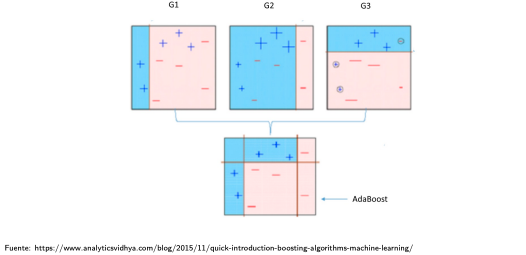

In [120]:
regressor = AdaBoostRegressor(random_state=1)
# estimator=None    DecisionTreeRegressor initialized with max_depth=3.
regressor.fit(X_train, Y_train) 
y_ada = regressor.predict(X_test)
mse_test_adaBoo = mean_squared_error(Y_test, y_ada)
print('MSE testeo (AdaBoost default):', mse_test_adaBoo)

MSE testeo (AdaBoost default): 28.429022938741657


#### Ajustando el parametro de penalidad $\lambda$

In [121]:
regressor = AdaBoostRegressor(learning_rate=0.001, random_state=1)
# learning_rate penalizacion de ajuste (lambda en las slides). Default es 1
regressor.fit(X_train, Y_train) 
y_ada1 = regressor.predict(X_test)
mse_test_adaBoo1 = mean_squared_error(Y_test, y_ada1)

In [122]:
regressor = AdaBoostRegressor(learning_rate=0.01, random_state=1)
regressor.fit(X_train, Y_train) 
y_ada2 = regressor.predict(X_test)
mse_test_adaBoo2 = mean_squared_error(Y_test, y_ada2)

In [123]:
regressor = AdaBoostRegressor(learning_rate=5, random_state=1)
regressor.fit(X_train, Y_train) 
y_ada3 = regressor.predict(X_test)
mse_test_adaBoo3 = mean_squared_error(Y_test, y_ada3)

In [124]:
print('MSE test de:', 
      '\n lambda=1 (default) :', mse_test_adaBoo,
      '\n lambda=0.001 :', mse_test_adaBoo1, 
      '\n lambda=0.01 :', mse_test_adaBoo2,
      '\n lambda=5 :', mse_test_adaBoo3)

MSE test de: 
 lambda=1 (default) : 28.429022938741657 
 lambda=0.001 : 26.870164555329904 
 lambda=0.01 : 27.30177525686195 
 lambda=5 : 694.7847058823526


learning_rate muy chico (0.001)  → aprende lerdo, acá igual dio un MSE de test menor que el default (26,9 contra 28,4)

learning_rate medio (0.1 - 1)    → zona habitual, la CV eligió 1.5 

learning_rate muy grande (5)     → pasos enormes → inestable → MSE explota 


El learning_rate es cuánto le cree el modelo a cada árbol. Chico = aprende despacio pero seguro (mejor generalización); grande = aprende rápido pero se arriesga a sobreajustar. A cambio, learning_rate chico necesita más árboles.

#### Usando cross-validation para elegir los hiperparámetros en AdaBoosting

In [125]:
params_grid_ab = {
    'n_estimators': [25, 50, 75, 100], # n_estimators=50 es el valor default de numero de árboles secuenciales (B en las slides)
    'learning_rate': [0.001, 0.01, 0.1, 1, 1.5]   
}

adaB = AdaBoostRegressor(random_state=1)
grid_adb = GridSearchCV(estimator=adaB, param_grid=params_grid_ab, cv=5)
grid_adb.fit(X_train, Y_train)

GridSearchCV(cv=5, estimator=AdaBoostRegressor(random_state=1),
             param_grid={'learning_rate': [0.001, 0.01, 0.1, 1, 1.5],
                         'n_estimators': [25, 50, 75, 100]})

In [126]:
grid_adb.best_estimator_

AdaBoostRegressor(learning_rate=1.5, n_estimators=100, random_state=1)

In [127]:
# Evaluamos el modelo en base de testeo
regressor = AdaBoostRegressor(n_estimators=100, learning_rate=1.5, random_state=1) 
regressor.fit(X_train, Y_train) 
y_pred_adb = regressor.predict(X_test)
mse_test_adb = mean_squared_error(Y_test, y_pred_adb)
print('MSE test (AdaBoost)', mse_test_adb)

MSE test (AdaBoost) 28.05389642938355


### Comparamos el modelo lineal con los modelos de ensamble con mejores hiperparametros por CV

In [128]:

print('MSE test de:', 
      '\nMCO:',mse0,
      '\nCART',  mse_cart,
      '\nBagging', mse_bagg,
      '\nRF:', mse_rf, 
      '\nAdaBoost:', mse_test_adb)

MSE test de: 
MCO: 34.395063464646675 
CART 29.579355626698074 
Bagging 22.56755930882352 
RF: 21.880574852941187 
AdaBoost: 28.05389642938355


## Conclusiones

Los métodos de ensamble superan claramente al modelo lineal (MCO) y al árbol CART. Bagging y Random Forest reducen el error de manera importante, siendo RF el mejor dentro de los métodos basados en promediar árboles.

Entre los métodos de boosting, AdaBoost funciona bien pero queda por detrás de Bagging y Random Forest.